# Forecasting German Electricity Demand

A comparative evaluation of statistical, machine-learning, and LSTM models using German hourly electricity load (2015–2020), Berlin temperature, and calendar features.


## 0. Environment and configuration

### SARIMA checkpoint upload

In Google Colab, run the next cell and upload `German_Electricity_SARIMA_Checkpoint.zip` when prompted. In local Jupyter, the `checkpoint/` folder is detected automatically. The checkpoint preserves the 1,176 completed parameter combinations.


In [1]:
# Colab file-upload control for the completed SARIMA grid.
from pathlib import Path
import csv
import io
import json
import zipfile

COLAB_UPLOADED_INPUTS = Path('/content/colab_uploaded_inputs')
try:
    from google.colab import files as colab_files
    _colab_session = True
except ImportError:
    _colab_session = False

if _colab_session:
    COLAB_UPLOADED_INPUTS.mkdir(parents=True, exist_ok=True)
    _required = ('sarima_full_grid.csv', 'sarima_full_grid_metadata.json')
    if all((COLAB_UPLOADED_INPUTS / name).is_file() for name in _required):
        print('Previously extracted SARIMA checkpoint found. Upload not needed.')
    else:
        print('Choose the SARIMA checkpoint ZIP from your device when the upload button appears.')
        _uploaded = colab_files.upload()
        _archive_names = [name for name in _uploaded if name.lower().endswith('.zip')]
        if len(_archive_names) != 1:
            raise ValueError('Upload one SARIMA checkpoint ZIP containing CSV and metadata JSON.')
        with zipfile.ZipFile(io.BytesIO(_uploaded[_archive_names[0]])) as _zip:
            _parts = {}
            for _entry in _zip.namelist():
                _base = Path(_entry).name
                if _base in _required:
                    if _base in _parts:
                        raise ValueError(f'Duplicate checkpoint member: {_base}')
                    _parts[_base] = _zip.read(_entry)
            if set(_parts) != set(_required):
                raise ValueError('Checkpoint ZIP must contain sarima_full_grid.csv and sarima_full_grid_metadata.json.')
            _metadata = json.loads(_parts['sarima_full_grid_metadata.json'].decode('utf-8'))
            _grid_rows = list(csv.DictReader(io.StringIO(_parts['sarima_full_grid.csv'].decode('utf-8'))))
            if len(_grid_rows) != 1176 or _metadata.get('grid_size') != 1176:
                raise ValueError('Checkpoint is not the complete 1,176-specification grid.')
            if len({(r['order'], r['seasonal_order']) for r in _grid_rows}) != 1176:
                raise ValueError('Duplicate SARIMA specifications in checkpoint.')
            for _name, _content in _parts.items():
                (COLAB_UPLOADED_INPUTS / _name).write_bytes(_content)
        print('SARIMA checkpoint extracted: 1,176 unique specifications.')
else:
    print('Colab upload control skipped (running in Kaggle or local Jupyter).')

Choose the SARIMA checkpoint ZIP from your device when the upload button appears.


Saving German_Electricity_SARIMA_Checkpoint_Colab.zip to German_Electricity_SARIMA_Checkpoint_Colab.zip
SARIMA checkpoint extracted: 1,176 unique specifications.


In [2]:
# Install missing Colab dependencies and match the SARIMA checkpoint environment.
import importlib.util
from importlib.metadata import PackageNotFoundError, version
import subprocess
import sys

for _module, _requirement in [
    ('holidays', 'holidays>=0.50,<1'),
    ('tensorflow', 'tensorflow>=2.15,<3'),
]:
    if importlib.util.find_spec(_module) is None:
        print(f'Installing {_requirement}')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', _requirement])

# This checkpoint was calculated with statsmodels 0.15.0.
# Install that version BEFORE importing statsmodels in the next cell.
_required_statsmodels_version = '0.15.0'
try:
    _installed_statsmodels_version = version('statsmodels')
except PackageNotFoundError:
    _installed_statsmodels_version = None
if _installed_statsmodels_version != _required_statsmodels_version:
    if 'statsmodels' in sys.modules:
        raise RuntimeError('Restart the runtime before changing statsmodels versions.')
    print(f'Installing statsmodels=={_required_statsmodels_version} for checkpoint compatibility')
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '-q',
        f'statsmodels=={_required_statsmodels_version}',
    ])
    if version('statsmodels') != _required_statsmodels_version:
        raise RuntimeError('statsmodels checkpoint version could not be installed.')
print('Dependencies checked. SARIMA checkpoint version:', version('statsmodels'))

Dependencies checked. SARIMA checkpoint version: 0.15.0


In [3]:
from __future__ import annotations

import gc
import hashlib
import itertools
import json
import math
import os
import sys
import time
import random
import warnings
import zipfile
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

# Install the packages in requirements.txt before starting (no silent pip installs).
try:
    import holidays
except ImportError as exc:
    raise ImportError("Missing 'holidays'. Install: pip install -r requirements.txt") from exc
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import scipy.stats as stats

from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import ParameterSampler
from sklearn.preprocessing import StandardScaler
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore", category=FutureWarning)

# -----------------------------
# Project configuration
# -----------------------------
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

# Portable paths for Colab, Kaggle, and local Jupyter.
RUNNING_ON_KAGGLE = Path('/kaggle/working').is_dir()
RUNNING_ON_COLAB = ('google.colab' in sys.modules) and not RUNNING_ON_KAGGLE
if RUNNING_ON_KAGGLE:
    INPUT_ROOT = Path('/kaggle/input')
    WORKING_ROOT = Path('/kaggle/working')
    EXECUTION_ENVIRONMENT = 'Kaggle'
elif RUNNING_ON_COLAB:
    INPUT_ROOT = Path('/content/colab_uploaded_inputs')
    WORKING_ROOT = Path('/content')
    EXECUTION_ENVIRONMENT = 'Google Colab'
else:
    INPUT_ROOT = Path.cwd() / 'input'
    WORKING_ROOT = Path.cwd()
    EXECUTION_ENVIRONMENT = 'Local Jupyter'
PROJECT_DIR = WORKING_ROOT / 'German_Electricity_Forecasting'
DATA_DIR = PROJECT_DIR / 'data'
OUTPUT_DIR = PROJECT_DIR / 'outputs'
FIGURE_DIR = OUTPUT_DIR / 'figures'
TABLE_DIR = OUTPUT_DIR / 'tables'
MODEL_DIR = OUTPUT_DIR / 'models'

for directory in [DATA_DIR, OUTPUT_DIR, FIGURE_DIR, TABLE_DIR, MODEL_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

DATA_URL = (
    "https://data.open-power-system-data.org/time_series/2020-10-06/"
    "time_series_60min_singleindex.csv"
)
LOAD_COLUMN = "DE_load_actual_entsoe_transparency"
START_DATE = "2015-01-01"
END_DATE = "2020-10-31 23:00:00"
WEEK_FREQ = "W-SUN"
SEASONAL_PERIOD_WEEKLY = 52
SEASONAL_PERIOD_HOURLY = 168
# Fair comparison: EVERY hourly MASE uses the same 168-hour (weekly) training denominator.
HOURLY_MASE_SCALING_PERIOD = SEASONAL_PERIOD_HOURLY

# If a local or attached OPSD CSV exists, use it; otherwise download from the URL.
# Set an explicit path if multiple matches exist.
LOCAL_CSV_PATH = None
attached_csv_files = sorted(INPUT_ROOT.rglob("time_series_60min_singleindex.csv")) if INPUT_ROOT.exists() else []
if len(attached_csv_files) == 1:
    LOCAL_CSV_PATH = str(attached_csv_files[0])
    print("Using attached OPSD CSV:", LOCAL_CSV_PATH)
elif len(attached_csv_files) > 1:
    raise RuntimeError(
        "Multiple OPSD CSV input files detected. Specify one in LOCAL_CSV_PATH "
        "and remove this ambiguity check."
    )

# Evaluate the full 1,176-configuration SARIMA grid.
RUN_FULL_SARIMA_GRID = True
FORCE_RERUN_SARIMA_GRID = False
# SARIMA model fitting uses CPU, not Kaggle GPU; avoid memory exhaustion.
SARIMA_N_JOBS = 1
SARIMA_MAXITER = 100

# Read optional input checkpoints into the writable project directory.
# If multiple datasets contain the same filenames, specify a single directory.
CHECKPOINT_SOURCE_DIR = None  # Set an explicit directory if multiple checkpoint folders exist.
AUTO_IMPORT_ATTACHED_SARIMA_CHECKPOINT = True
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
SARIMA_GRID_FILE = CHECKPOINT_DIR / "sarima_full_grid.csv"
SARIMA_GRID_META_FILE = CHECKPOINT_DIR / "sarima_full_grid_metadata.json"
LOCAL_GRID_EXPORT = TABLE_DIR / "sarima_full_grid.csv"
LOCAL_GRID_META_EXPORT = TABLE_DIR / "sarima_full_grid_metadata.json"


def find_input_checkpoint_pair():
    """Locate exactly one complete checkpoint pair in external input folders."""
    if CHECKPOINT_SOURCE_DIR:
        source = Path(CHECKPOINT_SOURCE_DIR)
        if not source.is_dir():
            raise FileNotFoundError(f"Checkpoint input directory not found: {source}")
        candidates = [source]
    else:
        candidates = sorted({p.parent for p in INPUT_ROOT.rglob('sarima_full_grid.csv')}) if INPUT_ROOT.exists() else []
        # Local repository checkouts may keep their checkpoint in checkpoint/.
        if not RUNNING_ON_KAGGLE:
            for path in [Path.cwd() / 'checkpoint', Path.cwd() / 'checkpoints']:
                if (path / 'sarima_full_grid.csv').exists():
                    candidates.append(path)
            candidates = sorted(set(candidates))
    valid = []
    for candidate in candidates:
        csv_file = candidate / "sarima_full_grid.csv"
        meta_file = candidate / "sarima_full_grid_metadata.json"
        if not (csv_file.is_file() and meta_file.is_file()):
            raise RuntimeError(
                f"Checkpoint CSV and metadata JSON must be a matching pair in {candidate}. "
                "Incomplete checkpoints are never imported."
            )
        valid.append(candidate)
    if len(valid) > 1:
        raise RuntimeError(
            "Multiple checkpoint input folders found: " + ", ".join(map(str, valid))
            + ". Set CHECKPOINT_SOURCE_DIR to the intended folder."
        )
    return valid[0] if valid else None


if AUTO_IMPORT_ATTACHED_SARIMA_CHECKPOINT:
    source_dir = find_input_checkpoint_pair()
    if source_dir is not None:
        local_presence = (SARIMA_GRID_FILE.exists(), SARIMA_GRID_META_FILE.exists())
        if any(local_presence) and not all(local_presence):
            raise RuntimeError("Incomplete local checkpoint. Back up or repair both files before resuming.")
        if not any(local_presence):
            # Verify read-only input pair can be parsed BEFORE copying.
            try:
                source_meta = json.loads((source_dir / "sarima_full_grid_metadata.json").read_text(encoding="utf-8"))
                source_count = len(pd.read_csv(source_dir / "sarima_full_grid.csv"))
            except Exception as exc:
                raise RuntimeError(f"Unreadable checkpoint source: {source_dir}") from exc
            import shutil
            shutil.copy2(source_dir / "sarima_full_grid.csv", SARIMA_GRID_FILE)
            shutil.copy2(source_dir / "sarima_full_grid_metadata.json", SARIMA_GRID_META_FILE)
            print(f"Copied {source_count} checkpoint rows from input: {source_dir}")
        else:
            print("Existing local checkpoint preserved (input not copied).")

# Extra analyses are evaluation-only: never use held-out outcomes for model selection.
RUN_SARIMA_DIAGNOSTIC_SENSITIVITY = True
RUN_LSTM_SEED_STABILITY = True     # Trains two ADDITIONAL selected-architecture models.
LSTM_STABILITY_EXTRA_SEEDS = (RANDOM_SEED + 1, RANDOM_SEED + 2)
RUN_LSTM = True

print(f"Environment: {EXECUTION_ENVIRONMENT}")
print(f"Output project directory: {PROJECT_DIR}")
print(f"SARIMA parallel jobs: {SARIMA_N_JOBS}")
print(f"Local SARIMA checkpoint directory: {CHECKPOINT_DIR}")
print("Keep a downloaded copy of the checkpoint and final results outside the temporary runtime.")

# Reproducibility manifest. Checkpoint validation below rejects incompatible metadata.
package_names = ["numpy", "pandas", "scipy", "scikit-learn", "statsmodels",
                 "matplotlib", "joblib", "requests", "holidays", "tensorflow"]
environment_versions = {}
for package in package_names:
    try:
        environment_versions[package] = version(package)
    except PackageNotFoundError:
        environment_versions[package] = "not installed (TensorFlow is checked in Part 6)"
(TABLE_DIR / "environment_versions.json").write_text(
    json.dumps(environment_versions, indent=2), encoding="utf-8")
print("Saved dependency-version manifest")

SARIMA_RESIDUAL_ALPHA = 0.01
SARIMA_ROOT_MARGIN = 1.001


Copied 1176 checkpoint rows from input: /content/colab_uploaded_inputs
Environment: Google Colab
Output project directory: /content/German_Electricity_Forecasting
SARIMA parallel jobs: 1
Local SARIMA checkpoint directory: /content/German_Electricity_Forecasting/checkpoints
Keep a downloaded copy of the checkpoint and final results outside the temporary runtime.
Saved dependency-version manifest


In [4]:
# Shared metrics and plotting helpers

def rmse(y_true, y_pred) -> float:
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def smape(y_true, y_pred) -> float:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denominator = np.abs(y_true) + np.abs(y_pred)
    valid = denominator > 0
    if not np.any(valid):
        return 0.0
    return float(200.0 * np.mean(np.abs(y_true[valid] - y_pred[valid]) / denominator[valid]))


def mase(y_true, y_pred, y_train, seasonal_period: int) -> float:
    y_train = np.asarray(y_train, dtype=float)
    if len(y_train) <= seasonal_period:
        return np.nan
    denominator = np.mean(np.abs(y_train[seasonal_period:] - y_train[:-seasonal_period]))
    if denominator == 0:
        return np.nan
    return float(mean_absolute_error(y_true, y_pred) / denominator)


def metric_record(model_name, y_true, y_pred, y_train, seasonal_period, protocol, frequency):
    y_true = pd.Series(y_true).astype(float)
    y_pred = pd.Series(y_pred).astype(float)
    if not y_true.index.equals(y_pred.index):
        raise ValueError(f"{model_name}: forecasts and truth must have exactly aligned indices")
    common = y_true.index
    if not np.isfinite(y_true.to_numpy()).all() or not np.isfinite(y_pred.to_numpy()).all():
        raise ValueError(f"{model_name}: non-finite truth or predictions")
    return {
        "Model": model_name,
        "Frequency": frequency,
        "Protocol": protocol,
        "N": len(common),
        "RMSE": rmse(y_true, y_pred),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "sMAPE_pct": smape(y_true, y_pred),
        "MASE": mase(y_true, y_pred, y_train, seasonal_period),
    }


def finish_plot(filename: str):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

## Part 1 — Retrieve, clean and aggregate the electricity-demand data

In [5]:
def read_electricity_data(
    data_url: str,
    local_csv_path: str | None = None,
    load_column: str = LOAD_COLUMN,
) -> pd.DataFrame:
    """Read only the timestamp and requested load column to minimise memory use."""
    if local_csv_path:
        source = Path(local_csv_path)
        if not source.exists():
            raise FileNotFoundError(f"LOCAL_CSV_PATH does not exist: {source}")
    else:
        source = data_url

    header = pd.read_csv(source, nrows=0).columns.tolist()
    timestamp_column = "utc_timestamp" if "utc_timestamp" in header else header[0]
    if load_column not in header:
        candidates = [c for c in header if c.startswith("DE_") and "load_actual" in c]
        raise KeyError(
            f"{load_column!r} was not found. Candidate German load columns: {candidates}"
        )

    raw = pd.read_csv(
        source,
        usecols=[timestamp_column, load_column],
        low_memory=False,
    )
    timestamps = pd.to_datetime(raw.pop(timestamp_column), utc=True, errors="coerce")
    raw.index = pd.DatetimeIndex(timestamps).tz_convert(None)
    raw = raw.loc[~raw.index.isna()].sort_index()
    return raw


raw = read_electricity_data(DATA_URL, LOCAL_CSV_PATH)
original_load = pd.to_numeric(raw[LOAD_COLUMN], errors="coerce")
original_load = original_load.loc[START_DATE:END_DATE]
duplicate_count_before = int(original_load.index.duplicated(keep=False).sum())
original_load = original_load[~original_load.index.duplicated(keep="last")]

if original_load.empty:
    raise ValueError("No electricity observations remained after date filtering.")

full_hourly_index = pd.date_range(
    original_load.index.min().floor("h"),
    original_load.index.max().floor("h"),
    freq="h",
)
load_hourly = original_load.reindex(full_hourly_index)
missing_before = int(load_hourly.isna().sum())

# Past-only filling avoids using later observations to repair earlier gaps.
load_hourly = load_hourly.fillna(load_hourly.shift(SEASONAL_PERIOD_HOURLY))
load_hourly = load_hourly.fillna(load_hourly.shift(24))
load_hourly = load_hourly.ffill(limit=3)
missing_after = int(load_hourly.isna().sum())

if missing_after:
    raise ValueError(
        f"{missing_after} hourly values remain missing after past-only filling. "
        "Inspect the source instead of silently interpolating across long gaps."
    )

load_hourly.name = "load"
daily_count = load_hourly.resample("D").count()
weekly_count = load_hourly.resample(WEEK_FREQ).count()
daily_load = load_hourly.resample("D").mean().loc[daily_count == 24]
weekly_load = load_hourly.resample(WEEK_FREQ).mean().loc[weekly_count == 168]
daily_load.name = "load"
weekly_load.name = "load"

load_hourly.to_frame().to_csv(DATA_DIR / "german_load_hourly_clean.csv")
daily_load.to_frame().to_csv(DATA_DIR / "german_load_daily.csv")
weekly_load.to_frame().to_csv(DATA_DIR / "german_load_weekly.csv")

quality_summary = pd.DataFrame({
    "Item": [
        "Raw rows in selected period",
        "Duplicate timestamp rows identified",
        "Missing hours before filling",
        "Missing hours after filling",
        "Hourly observations retained",
        "Complete daily observations",
        "Complete weekly observations",
    ],
    "Value": [
        len(original_load),
        duplicate_count_before,
        missing_before,
        missing_after,
        len(load_hourly),
        len(daily_load),
        len(weekly_load),
    ],
})
quality_summary.to_csv(TABLE_DIR / "data_quality_summary.csv", index=False)
print(quality_summary.to_string(index=False))
print(f"Actual source range retained: {load_hourly.index.min()} to {load_hourly.index.max()}")
print(load_hourly.describe())
print(f"Negative values: {(load_hourly < 0).sum()}")

# Define the forecast origin BEFORE any model-choice diagnostics.
# The test period stays fixed at the last two calendar years of the source.
forecast_start = (load_hourly.index.max().normalize() - pd.DateOffset(years=2)
                  + pd.Timedelta(days=1))
train_hourly = load_hourly.loc[load_hourly.index < forecast_start]
test_hourly = load_hourly.loc[load_hourly.index >= forecast_start]
train_weekly = weekly_load.loc[weekly_load.index < forecast_start]
test_weekly = weekly_load.loc[weekly_load.index >= forecast_start]
assert train_hourly.index.max() < test_hourly.index.min()
assert train_weekly.index.max() < test_weekly.index.min()
assert train_hourly.index.is_monotonic_increasing
assert len(train_weekly) >= 2 * SEASONAL_PERIOD_WEEKLY
print(f"Fixed forecast origin (first test hour): {forecast_start}")

if (load_hourly <= 0).any():
    print("Warning: non-positive electricity loads detected")
assert weekly_load.index.is_monotonic_increasing and not weekly_load.index.duplicated().any()
assert all(weekly_load.index.dayofweek == 6), "Weekly frequency must end Sunday"

                               Item  Value
        Raw rows in selected period  50400
Duplicate timestamp rows identified      0
       Missing hours before filling      0
        Missing hours after filling      0
       Hourly observations retained  50400
        Complete daily observations   2100
       Complete weekly observations    299
Actual source range retained: 2015-01-01 00:00:00 to 2020-09-30 23:00:00
count    50400.000000
mean     55492.468552
std      10015.431042
min      31307.000000
25%      47106.000000
50%      55092.000000
75%      64309.250000
max      77549.000000
Name: load, dtype: float64
Negative values: 0
Fixed forecast origin (first test hour): 2018-10-01 00:00:00


### Data integrity and imputation provenance

All time indexes use UTC. Daily values are arithmetic means of exactly 24 hours and weekly values are means of exactly 168 hours; incomplete trailing calendar weeks are excluded. Any missing observations are filled with earlier observed or previously filled values only. Export the original missing timestamps and a before/after audit; if the source has changed, the counts must be reassessed rather than assumed from an older run.


In [6]:
# Audit any imputations and verify that no observation was imputed from a future value.
_unfilled_hourly = original_load.reindex(full_hourly_index)
_imputed_mask = _unfilled_hourly.isna() & load_hourly.notna()
_imputed_times = pd.DataFrame({
    "timestamp_utc": full_hourly_index[_imputed_mask],
    "filled_load_MW": load_hourly.loc[_imputed_mask].to_numpy(),
})
_imputed_times.to_csv(TABLE_DIR / "imputed_hourly_observations.csv", index=False)
assert int(_imputed_mask.sum()) == missing_before - missing_after
assert load_hourly.index.equals(full_hourly_index)
assert daily_load.index.is_monotonic_increasing and weekly_load.index.is_monotonic_increasing
assert (daily_load.index.dayofweek >= 0).all()
assert (weekly_load.index.dayofweek == 6).all()
assert np.isfinite(load_hourly.to_numpy()).all()
assert int((load_hourly <= 0).sum()) == 0, "Nonpositive load requires explicit handling"
print("Missing-hour audit:", len(_imputed_times), "imputed hours")
print("Daily observations:", len(daily_load), "; complete weekly observations:", len(weekly_load))


# Test-set ground truth must come from actual OPSD observations, not a synthetic fill.
# Any training-only imputation is disclosed above; none is allowed in held-out truth.
_test_missing_original = original_load.reindex(test_hourly.index).isna()
if bool(_test_missing_original.any()):
    missing_preview = original_load.reindex(test_hourly.index).index[_test_missing_original][:5]
    raise ValueError(
        f"The held-out test window contains {_test_missing_original.sum()} missing raw hours "
        f"(first: {list(missing_preview)}). Do not evaluate imputations as observations."
    )
assert not _imputed_mask.reindex(test_hourly.index, fill_value=False).any()
assert np.isclose(float(load_hourly.loc[test_hourly.index].sum()), float(test_hourly.sum()))
print("Holdout load labels verified against original non-imputed OPSD observations.")


Missing-hour audit: 0 imputed hours
Daily observations: 2100 ; complete weekly observations: 299
Holdout load labels verified against original non-imputed OPSD observations.


### Initial plots and exploratory analysis

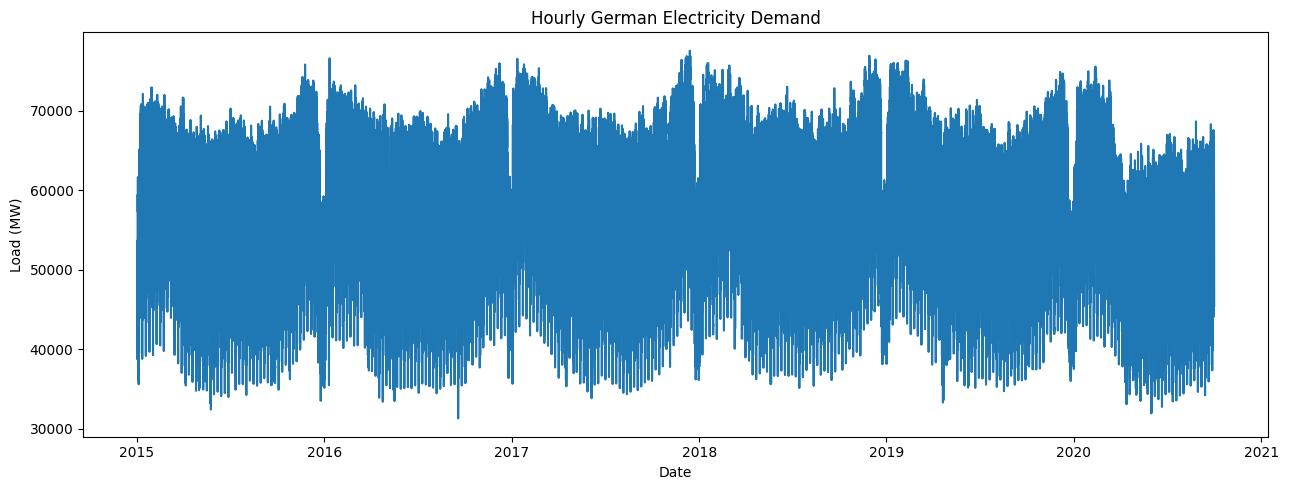

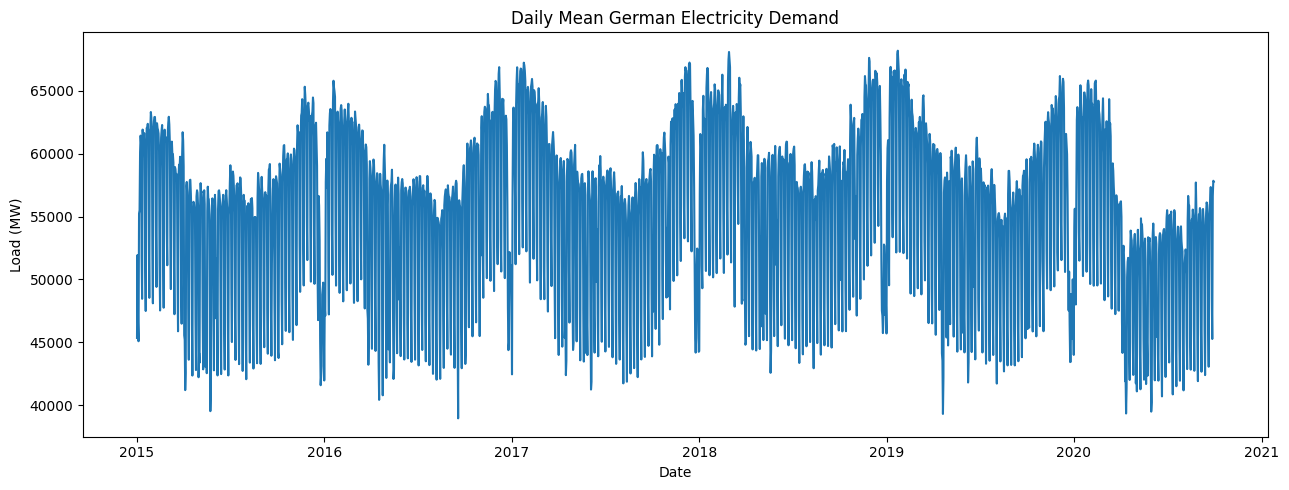

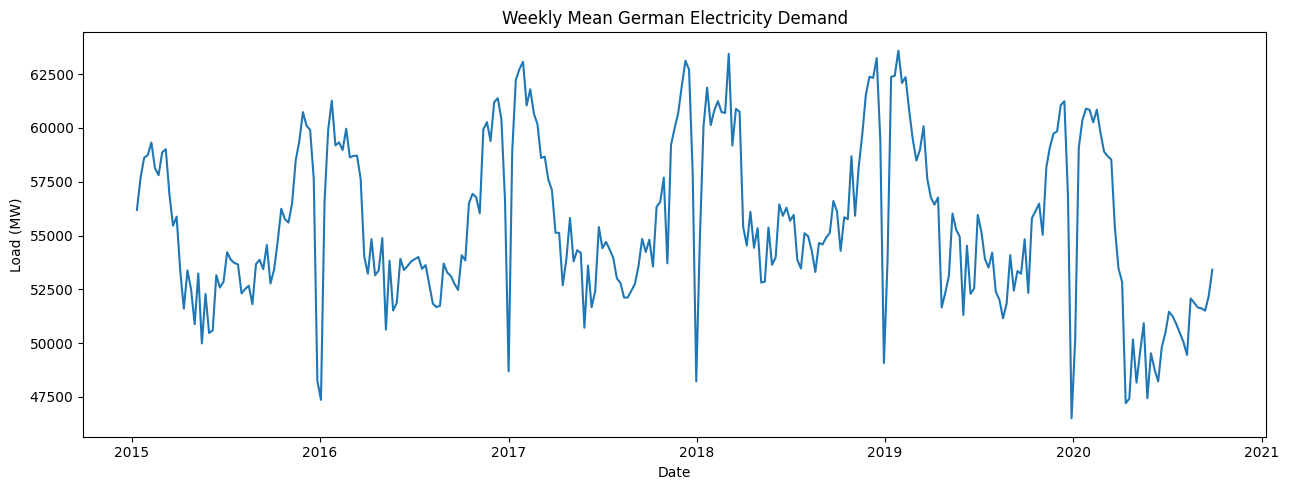

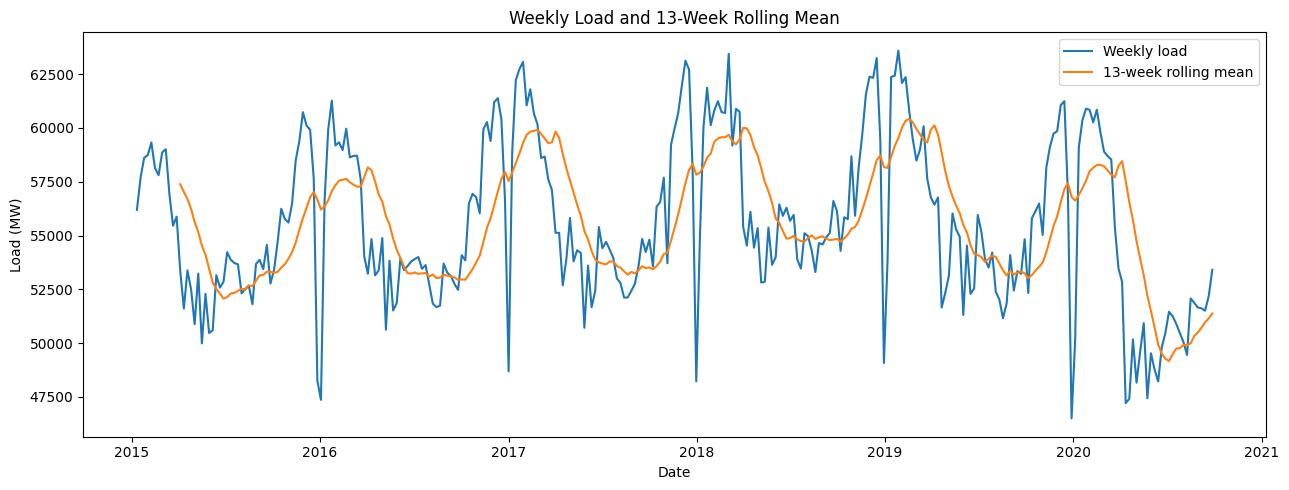

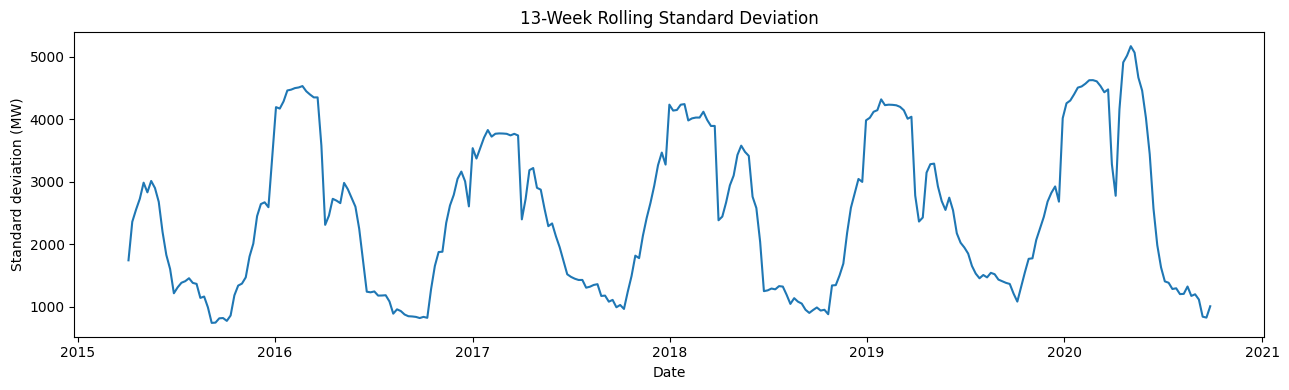

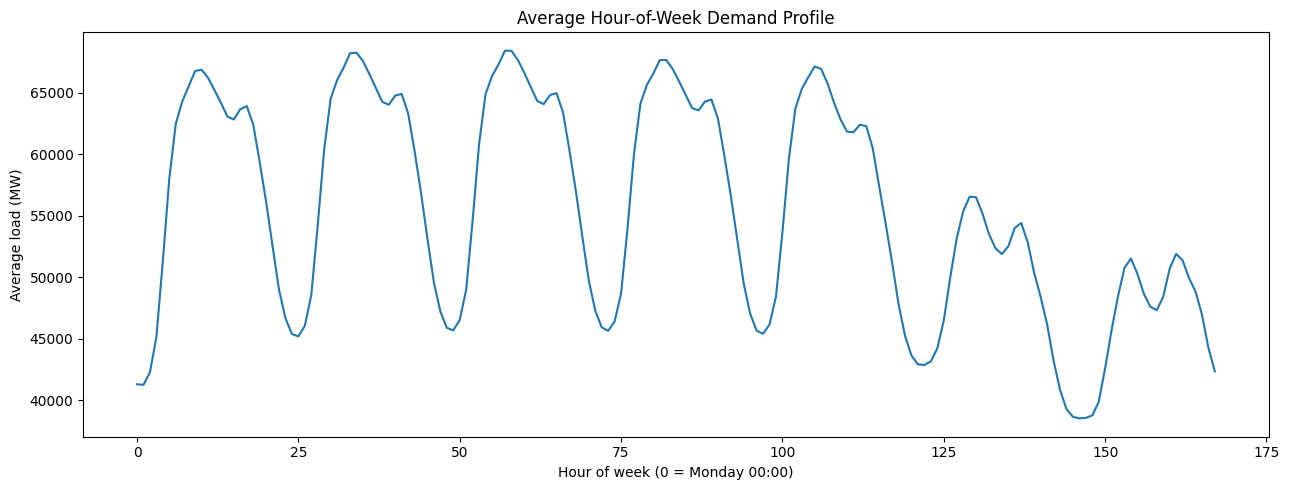

In [7]:
plt.figure(figsize=(13, 5))
plt.plot(load_hourly.index, load_hourly.values)
plt.title("Hourly German Electricity Demand")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
finish_plot("01_hourly_load.png")

plt.figure(figsize=(13, 5))
plt.plot(daily_load.index, daily_load.values)
plt.title("Daily Mean German Electricity Demand")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
finish_plot("02_daily_load.png")

plt.figure(figsize=(13, 5))
plt.plot(weekly_load.index, weekly_load.values)
plt.title("Weekly Mean German Electricity Demand")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
finish_plot("03_weekly_load.png")

rolling_mean = weekly_load.rolling(13).mean()
rolling_std = weekly_load.rolling(13).std()

plt.figure(figsize=(13, 5))
plt.plot(weekly_load.index, weekly_load.values, label="Weekly load")
plt.plot(rolling_mean.index, rolling_mean.values, label="13-week rolling mean")
plt.title("Weekly Load and 13-Week Rolling Mean")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
plt.legend()
finish_plot("04a_weekly_rolling_mean.png")

plt.figure(figsize=(13, 4))
plt.plot(rolling_std.index, rolling_std.values)
plt.title("13-Week Rolling Standard Deviation")
plt.xlabel("Date")
plt.ylabel("Standard deviation (MW)")
finish_plot("04b_weekly_rolling_std.png")

# Hour-of-week profile demonstrates daily and weekly seasonality in the hourly data.
hour_of_week = load_hourly.index.dayofweek * 24 + load_hourly.index.hour
hourly_profile = load_hourly.groupby(hour_of_week).mean()
plt.figure(figsize=(13, 5))
plt.plot(hourly_profile.index, hourly_profile.values)
plt.title("Average Hour-of-Week Demand Profile")
plt.xlabel("Hour of week (0 = Monday 00:00)")
plt.ylabel("Average load (MW)")
finish_plot("05_hour_of_week_profile.png")

### Calendar seasonality and distribution diagnostics

These charts are descriptive only. Model tuning and formal stationarity tests below are restricted to pre-origin observations.


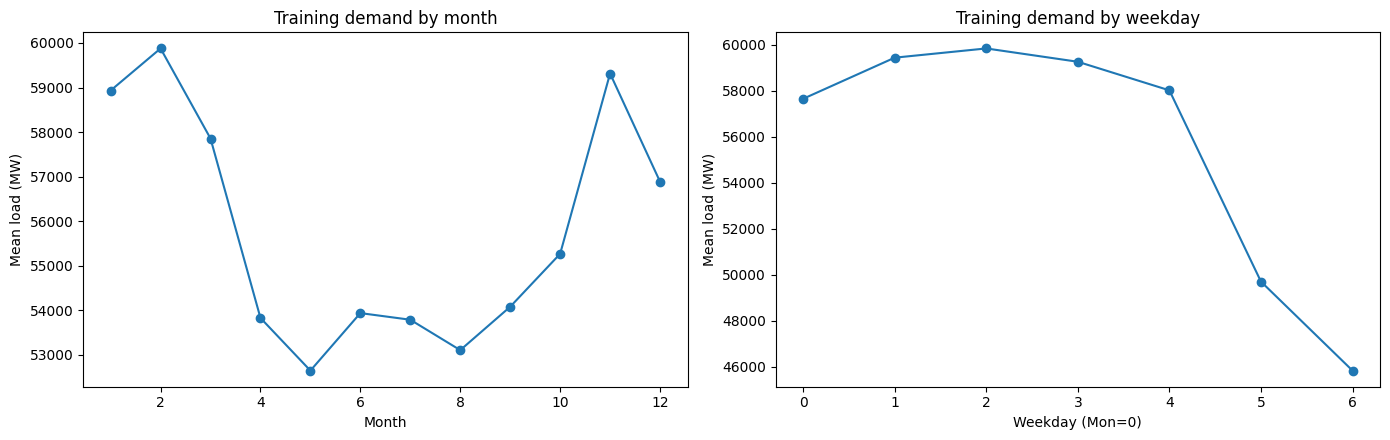

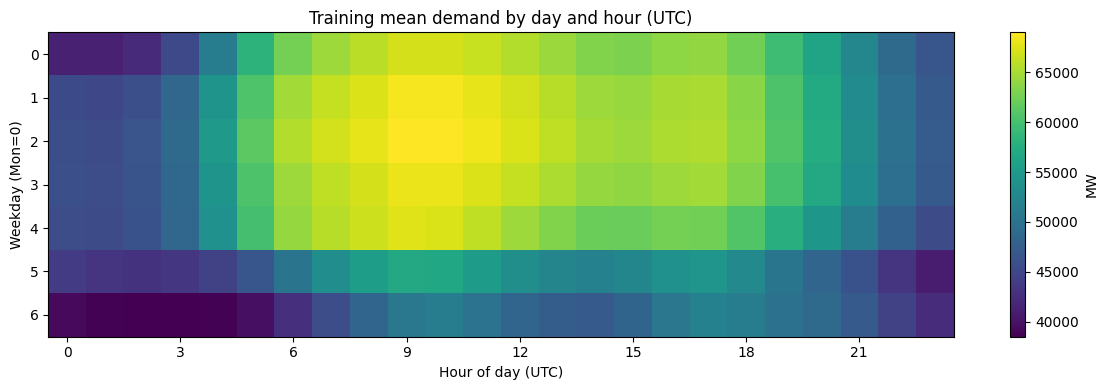

In [8]:
# Training-only seasonal profiles avoid using test outcomes in modelling decisions.
_train_load_frame = train_hourly.to_frame("load_MW")
_train_load_frame["month"] = _train_load_frame.index.month
_train_load_frame["hour"] = _train_load_frame.index.hour
_train_load_frame["weekday"] = _train_load_frame.index.dayofweek

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
_train_load_frame.groupby("month")["load_MW"].mean().plot(ax=axes[0], marker="o")
axes[0].set(title="Training demand by month", xlabel="Month", ylabel="Mean load (MW)")
_train_load_frame.groupby("weekday")["load_MW"].mean().plot(ax=axes[1], marker="o")
axes[1].set(title="Training demand by weekday", xlabel="Weekday (Mon=0)", ylabel="Mean load (MW)")
finish_plot("04c_training_calendar_patterns.png")

_training_hour_week = _train_load_frame.pivot_table(
    values="load_MW", index="weekday", columns="hour", aggfunc="mean"
)
fig, ax = plt.subplots(figsize=(12, 4))
heatmap = ax.imshow(_training_hour_week.to_numpy(), aspect="auto", origin="upper")
ax.set(title="Training mean demand by day and hour (UTC)", xlabel="Hour of day (UTC)", ylabel="Weekday (Mon=0)")
ax.set_xticks(range(0, 24, 3))
ax.set_yticks(range(7))
fig.colorbar(heatmap, ax=ax, label="MW")
finish_plot("04d_training_weekday_hour_heatmap.png")

_training_hour_week.to_csv(TABLE_DIR / "training_day_hour_profile.csv")


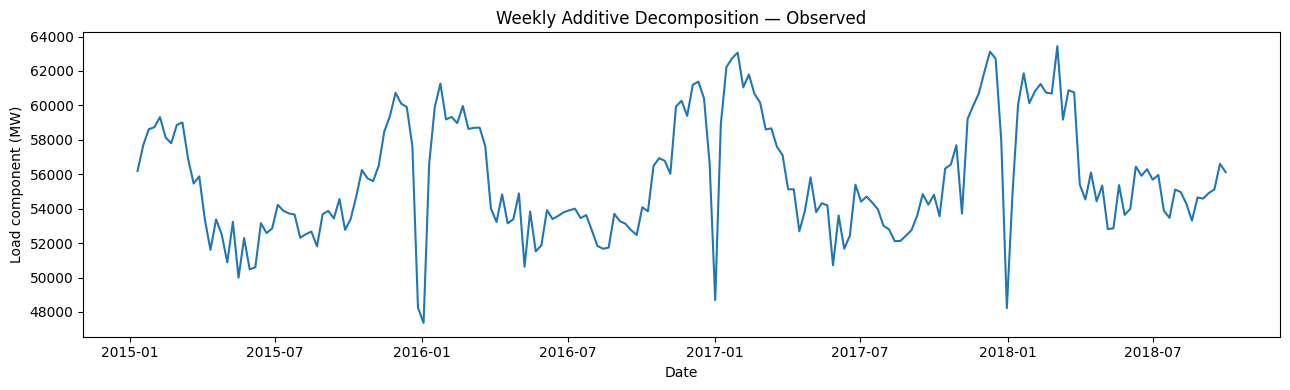

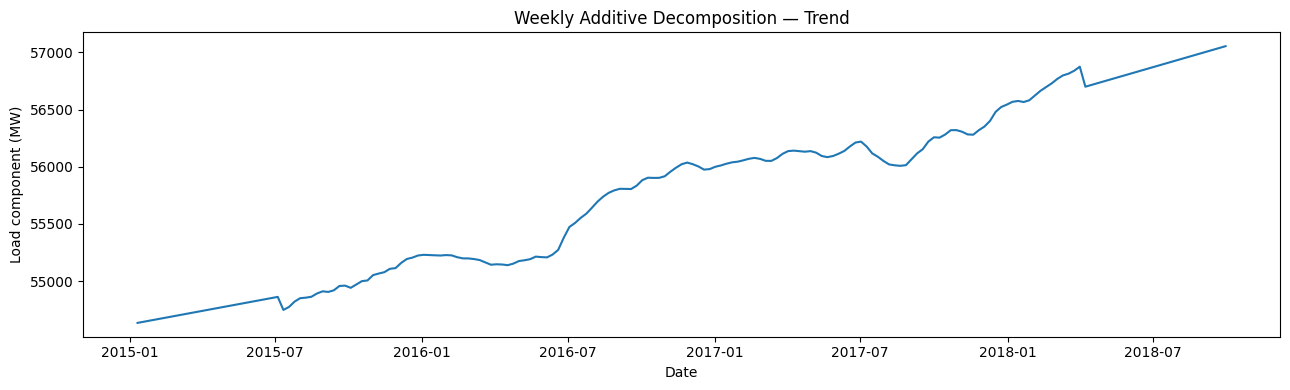

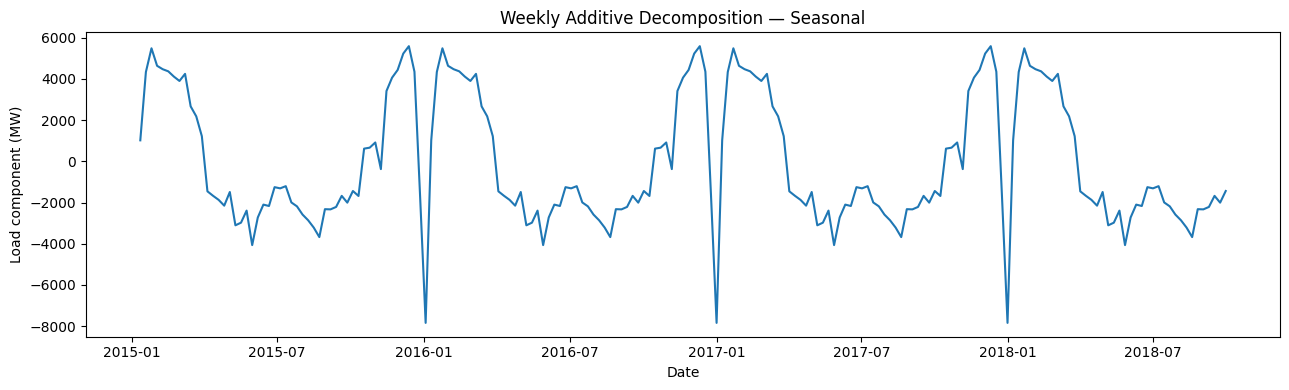

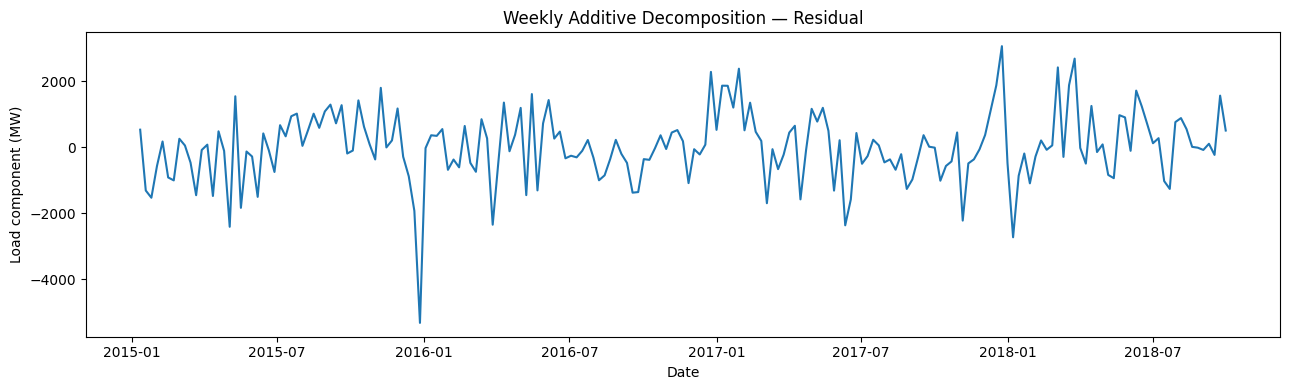

In [9]:
weekly_decomposition = seasonal_decompose(
    train_weekly, model="additive", period=SEASONAL_PERIOD_WEEKLY, extrapolate_trend="freq"
)

for component_name, component in {
    "Observed": weekly_decomposition.observed,
    "Trend": weekly_decomposition.trend,
    "Seasonal": weekly_decomposition.seasonal,
    "Residual": weekly_decomposition.resid,
}.items():
    plt.figure(figsize=(13, 4))
    plt.plot(component.index, component.values)
    plt.title(f"Weekly Additive Decomposition — {component_name}")
    plt.xlabel("Date")
    plt.ylabel("Load component (MW)")
    finish_plot(f"06_decomposition_{component_name.lower()}.png")

### Stationarity: ADF, KPSS, ACF, PACF and differencing

                              Series  ADF_statistic  ADF_p_value  KPSS_statistic  KPSS_p_value  ADF_rejects_unit_root_at_5pct  KPSS_rejects_stationarity_at_5pct
               Training weekly level      -5.003027 2.188904e-05        0.149877           0.1                           True                              False
           Training first difference      -5.570781 1.469164e-06        0.040588           0.1                           True                              False
   Training seasonal difference (52)      -5.039514 1.852536e-05        0.090992           0.1                           True                              False
Training first + seasonal difference      -6.727919 3.352826e-09        0.013846           0.1                           True                              False


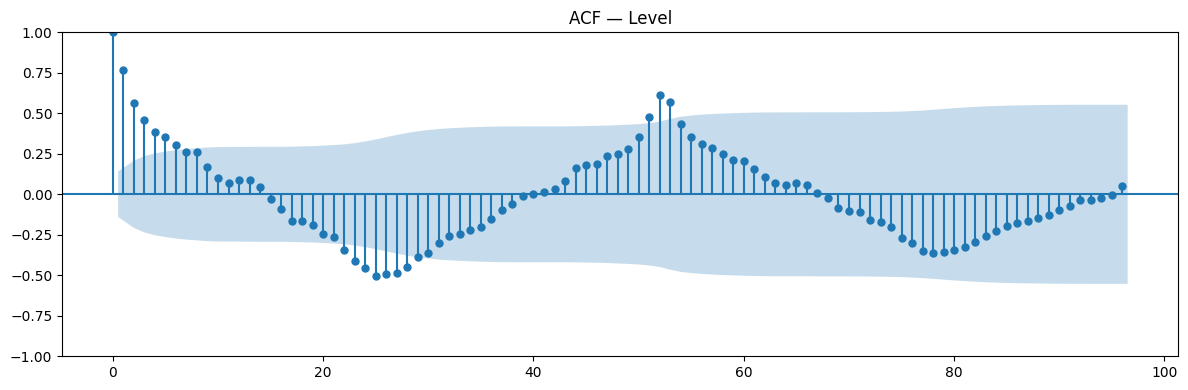

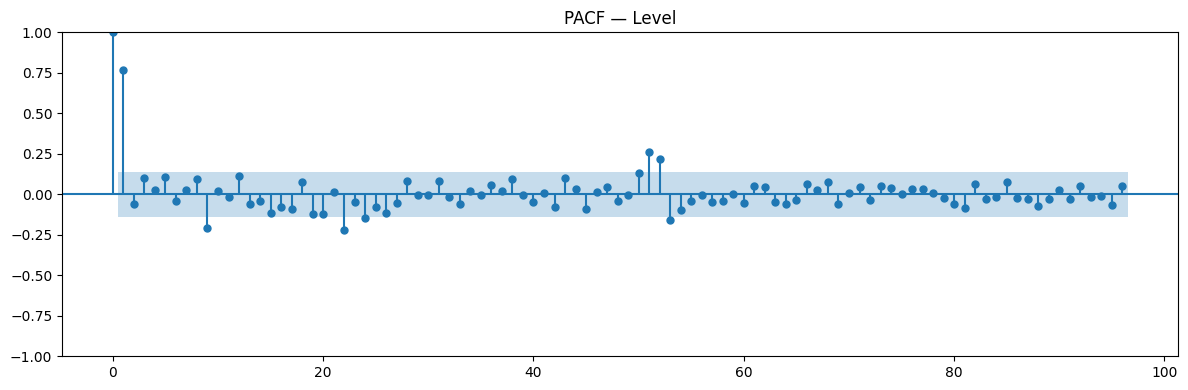

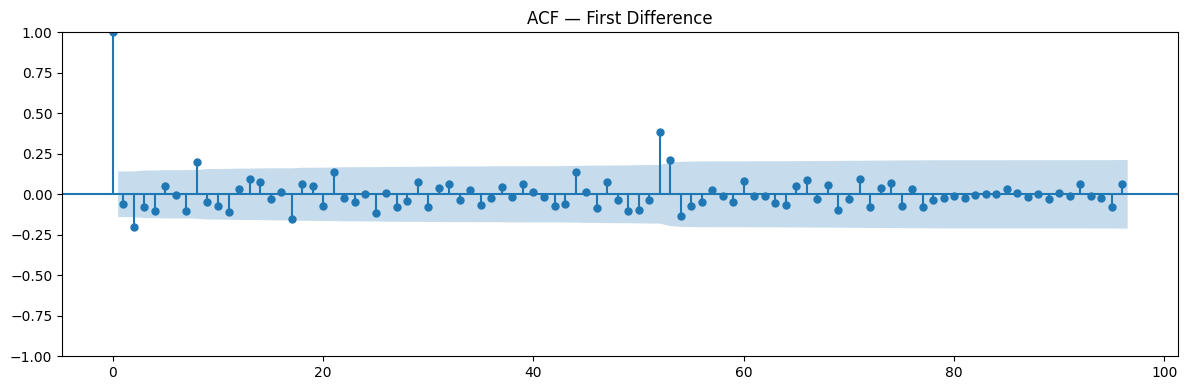

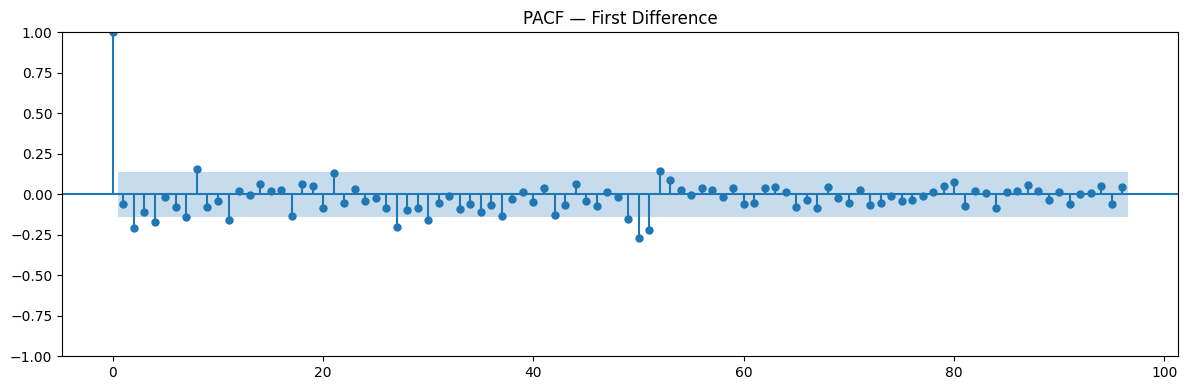

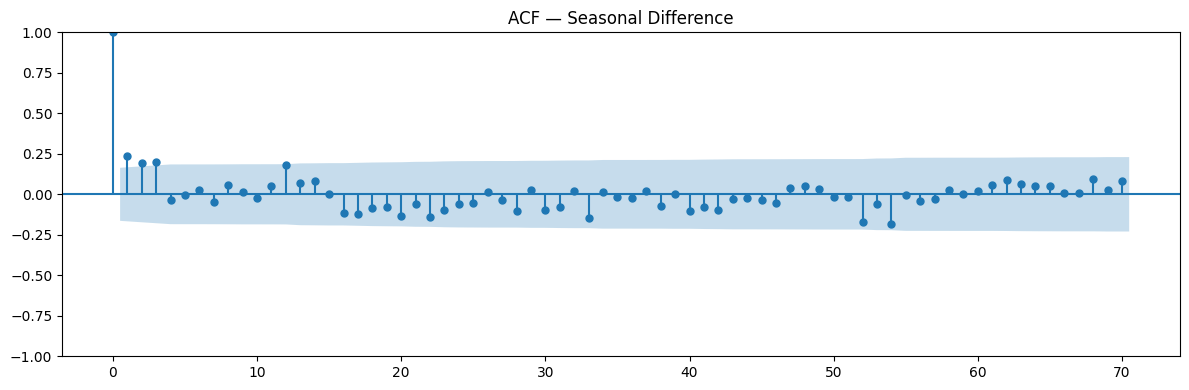

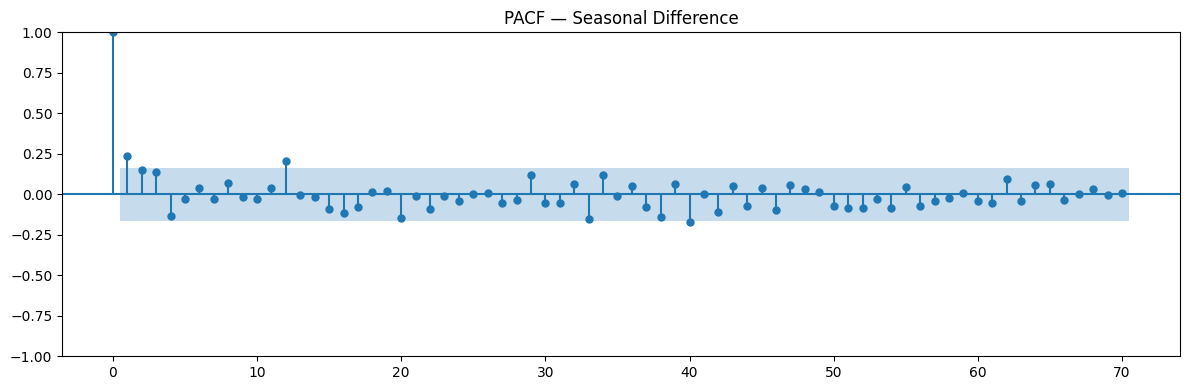

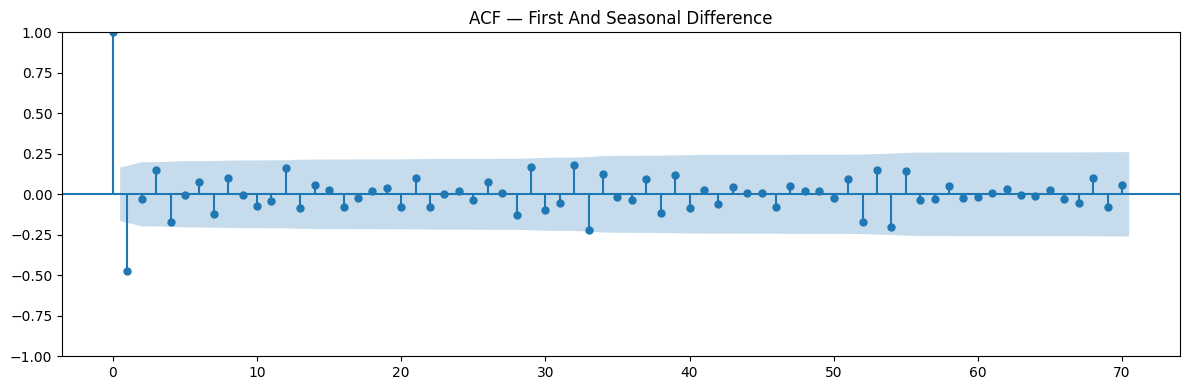

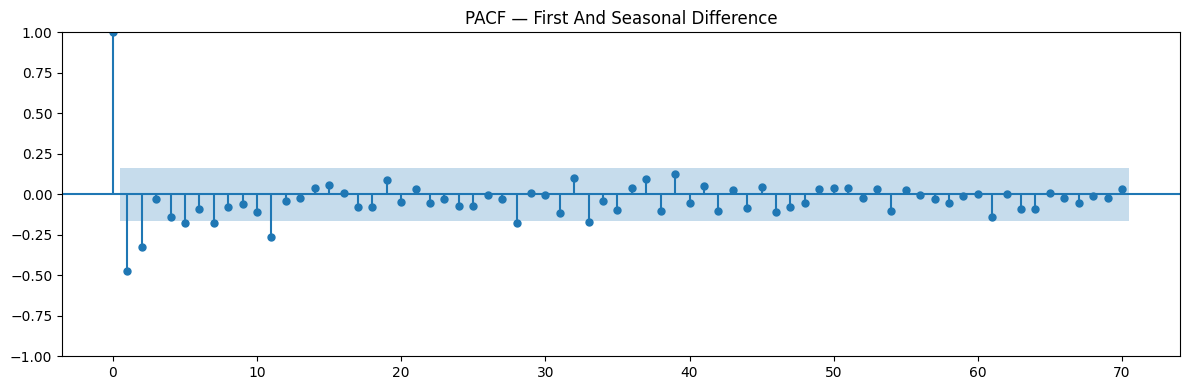

Interpretation: ADF p<0.05 rejects a unit root; KPSS p>=0.05 fails to reject stationarity.
Neither test alone determines seasonal D; compare candidate AIC and residual checks.


In [10]:
def stationarity_row(series: pd.Series, label: str) -> dict:
    clean = series.dropna()
    adf_result = adfuller(clean, autolag="AIC")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_result = kpss(clean, regression="c", nlags="auto")
    return {
        "Series": label,
        "ADF_statistic": adf_result[0],
        "ADF_p_value": adf_result[1],
        "KPSS_statistic": kpss_result[0],
        "KPSS_p_value": kpss_result[1],
    }

stationarity_results = pd.DataFrame([
    stationarity_row(train_weekly, "Training weekly level"),
    stationarity_row(train_weekly.diff(), "Training first difference"),
    stationarity_row(train_weekly.diff(SEASONAL_PERIOD_WEEKLY), "Training seasonal difference (52)"),
    stationarity_row(
        train_weekly.diff().diff(SEASONAL_PERIOD_WEEKLY),
        "Training first + seasonal difference",
    ),
])
# ADF null: unit root; KPSS null: stationarity. These are different tests.
stationarity_results["ADF_rejects_unit_root_at_5pct"] = stationarity_results["ADF_p_value"] < 0.05
stationarity_results["KPSS_rejects_stationarity_at_5pct"] = stationarity_results["KPSS_p_value"] < 0.05
stationarity_results.to_csv(TABLE_DIR / "stationarity_tests.csv", index=False)
print(stationarity_results.to_string(index=False))

series_for_diagnostics = {
    "level": train_weekly,
    "first_difference": train_weekly.diff(),
    "seasonal_difference": train_weekly.diff(SEASONAL_PERIOD_WEEKLY),
    "first_and_seasonal_difference": train_weekly.diff().diff(SEASONAL_PERIOD_WEEKLY),
}

for label, series in series_for_diagnostics.items():
    clean = series.dropna()
    max_lags = min(104, len(clean) // 2 - 1)

    fig, ax = plt.subplots(figsize=(12, 4))
    plot_acf(clean, lags=max_lags, ax=ax)
    ax.set_title(f"ACF — {label.replace('_', ' ').title()}")
    finish_plot(f"07_acf_{label}.png")

    fig, ax = plt.subplots(figsize=(12, 4))
    plot_pacf(clean, lags=max_lags, method="ywm", ax=ax)
    ax.set_title(f"PACF — {label.replace('_', ' ').title()}")
    finish_plot(f"08_pacf_{label}.png")

print("Interpretation: ADF p<0.05 rejects a unit root; KPSS p>=0.05 fails to reject stationarity.")
print("Neither test alone determines seasonal D; compare candidate AIC and residual checks.")

In [11]:
# Store correctly interpreted training-only ADF/KPSS decisions for report traceability.
_stationarity_explanations = stationarity_results.copy()
_stationarity_explanations["ADF_null"] = "unit root"
_stationarity_explanations["KPSS_null"] = "level stationarity"
_stationarity_explanations["ADF_interpretation"] = np.where(
    _stationarity_explanations["ADF_rejects_unit_root_at_5pct"],
    "reject unit root", "insufficient evidence to reject unit root",
)
_stationarity_explanations["KPSS_interpretation"] = np.where(
    _stationarity_explanations["KPSS_rejects_stationarity_at_5pct"],
    "reject stationarity", "insufficient evidence to reject stationarity",
)
_stationarity_explanations.to_csv(TABLE_DIR / "stationarity_interpretation.csv", index=False)
assert (_stationarity_explanations["ADF_rejects_unit_root_at_5pct"] ==
        (_stationarity_explanations["ADF_p_value"] < 0.05)).all()
print(_stationarity_explanations[["Series", "ADF_interpretation", "KPSS_interpretation"]].to_string(index=False))


                              Series ADF_interpretation                          KPSS_interpretation
               Training weekly level   reject unit root insufficient evidence to reject stationarity
           Training first difference   reject unit root insufficient evidence to reject stationarity
   Training seasonal difference (52)   reject unit root insufficient evidence to reject stationarity
Training first + seasonal difference   reject unit root insufficient evidence to reject stationarity


## Part 2 — Chronological split and benchmark forecasts

In [12]:
# Forecast-origin audit: defined immediately after preprocessing.
if len(train_weekly) < 2 * SEASONAL_PERIOD_WEEKLY:
    raise ValueError("Insufficient weekly training history for seasonal modelling.")
if test_weekly.empty or test_hourly.empty:
    raise ValueError("The two-year test period is empty.")

print(f"Forecast origin: {forecast_start}")
print(f"Weekly train: {train_weekly.index.min()} to {train_weekly.index.max()} ({len(train_weekly)})")
print(f"Weekly test:  {test_weekly.index.min()} to {test_weekly.index.max()} ({len(test_weekly)})")
print(f"Hourly train: {train_hourly.index.min()} to {train_hourly.index.max()} ({len(train_hourly)})")
print(f"Hourly test:  {test_hourly.index.min()} to {test_hourly.index.max()} ({len(test_hourly)})")

Forecast origin: 2018-10-01 00:00:00
Weekly train: 2015-01-11 00:00:00 to 2018-09-30 00:00:00 (195)
Weekly test:  2018-10-07 00:00:00 to 2020-09-27 00:00:00 (104)
Hourly train: 2015-01-01 00:00:00 to 2018-09-30 23:00:00 (32856)
Hourly test:  2018-10-01 00:00:00 to 2020-09-30 23:00:00 (17544)


         Model Frequency                 Protocol   N        RMSE         MAE  sMAPE_pct     MASE
          Mean    Weekly Fixed-origin operational 104 4402.058785 3789.845282   6.873777 2.805083
         Naive    Weekly Fixed-origin operational 104 4475.767085 3858.147779   6.995443 2.855638
Seasonal Naive    Weekly Fixed-origin operational 104 2988.248349 2288.489240   4.206690 1.693843
         Drift    Weekly Fixed-origin operational 104 4466.494389 3850.775752   6.982349 2.850181


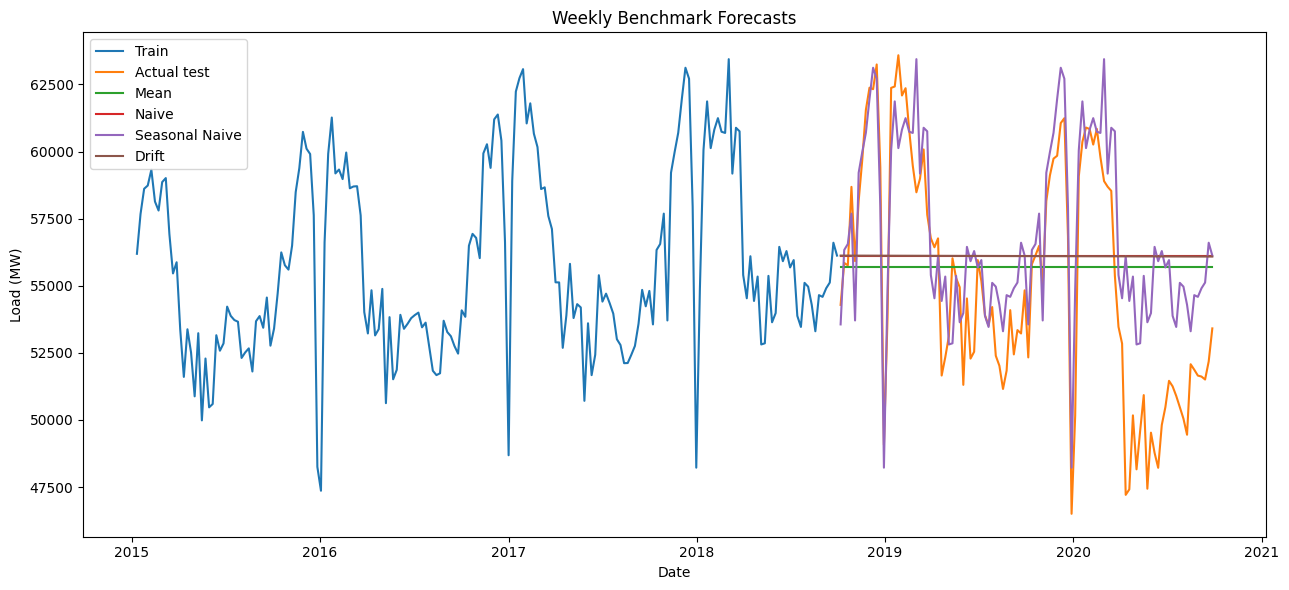

In [13]:
def benchmark_forecasts(train: pd.Series, test_index: pd.DatetimeIndex, season_length: int):
    horizon = len(test_index)
    mean_fc = pd.Series(np.repeat(train.mean(), horizon), index=test_index)
    naive_fc = pd.Series(np.repeat(train.iloc[-1], horizon), index=test_index)
    seasonal_fc = pd.Series(
        np.resize(train.iloc[-season_length:].to_numpy(), horizon),
        index=test_index,
    )
    slope = (train.iloc[-1] - train.iloc[0]) / max(1, len(train) - 1)
    drift_fc = pd.Series(
        train.iloc[-1] + slope * np.arange(1, horizon + 1),
        index=test_index,
    )
    return {
        "Mean": mean_fc,
        "Naive": naive_fc,
        "Seasonal Naive": seasonal_fc,
        "Drift": drift_fc,
    }

weekly_forecasts = benchmark_forecasts(
    train_weekly, test_weekly.index, SEASONAL_PERIOD_WEEKLY
)
forecast_metadata = {
    "Mean": ("Fixed-origin operational", "Weekly"),
    "Naive": ("Fixed-origin operational", "Weekly"),
    "Seasonal Naive": ("Fixed-origin operational", "Weekly"),
    "Drift": ("Fixed-origin operational", "Weekly"),
}

benchmark_metrics = pd.DataFrame([
    metric_record(
        name, test_weekly, forecast, train_weekly,
        SEASONAL_PERIOD_WEEKLY, "Fixed-origin operational", "Weekly"
    )
    for name, forecast in weekly_forecasts.items()
])
benchmark_metrics.to_csv(TABLE_DIR / "benchmark_metrics.csv", index=False)
print(benchmark_metrics.to_string(index=False))

plt.figure(figsize=(13, 6))
plt.plot(train_weekly.index, train_weekly.values, label="Train")
plt.plot(test_weekly.index, test_weekly.values, label="Actual test")
for name, forecast in weekly_forecasts.items():
    plt.plot(forecast.index, forecast.values, label=name)
plt.title("Weekly Benchmark Forecasts")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
plt.legend()
finish_plot("09_benchmark_forecasts.png")

## Part 3 — Full-range SARIMA search, diagnostics and forecast

This **full** 1,176-combination grid evaluates nonseasonal `p=0..6`, `d=0..2`, `q=0..6` crossed with `P,D,Q=0..1` and seasonal period 52. Fits use **training observations only**. All attempted specifications (including failures) are saved. A cache is reused only if its training-data fingerprint and search configuration match. **Primary model selection uses the smallest AIC among converged, finite, forecast-stable models; residual diagnostics are reported independently**, rather than silently replacing AIC with a post-hoc selection rule. AIC need not give the smallest test RMSE.

**Colab progress:** Each small batch writes the grid CSV and metadata. The printed number counts *attempted configurations*, including nonconverged/failed fits. The final successful-fit count is printed separately. The CSV and metadata must stay together. Cached outputs are reused only when the training fingerprint and configuration match.

In [14]:
P_VALUES = range(0, 2)
D_VALUES = range(0, 2)
Q_VALUES = range(0, 2)

sarima_specs = [
    ((p, d, q), (P, D, Q, SEASONAL_PERIOD_WEEKLY))
    for p, d, q in itertools.product(range(0, 7), range(0, 3), range(0, 7))
    for P, D, Q in itertools.product(P_VALUES, D_VALUES, Q_VALUES)
]

print(f"Total SARIMA specifications: {len(sarima_specs)}")
assert len({spec[0] for spec in sarima_specs}) == 7 * 3 * 7
assert len(sarima_specs) == 7 * 3 * 7 * 2 * 2 * 2

Total SARIMA specifications: 1176


In [15]:
def fit_sarima_model(series, order, seasonal_order, maxiter=SARIMA_MAXITER):
    """Fit one constrained SARIMA model, trying two optimisers."""
    last_error = None
    for method in ("lbfgs", "powell"):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                model = SARIMAX(
                    series,
                    order=order,
                    seasonal_order=seasonal_order,
                    trend="n",
                    enforce_stationarity=True,
                    enforce_invertibility=True,
                )
                fitted = model.fit(disp=False, method=method, maxiter=maxiter)
            converged = bool(fitted.mle_retvals.get("converged", True))
            finite = np.all(np.isfinite(fitted.params)) and np.isfinite(fitted.aic)
            if converged and finite:
                return fitted, method
            last_error = RuntimeError(
                f"{method} returned a non-converged or non-finite fit"
            )
        except Exception as exc:
            last_error = exc
    raise RuntimeError(f"Both optimisers failed: {last_error}")


def evaluate_sarima_spec(order, seasonal_order, series, sanity_steps):
    record = {
        "order": str(tuple(order)),
        "seasonal_order": str(tuple(seasonal_order)),
        "aic": np.inf,
        "bic": np.inf,
        "converged": False,
        "stable_forecast": False,
        "optimizer": None,
        "error": None,
    }
    try:
        fitted, method = fit_sarima_model(series, order, seasonal_order)
        converged = bool(fitted.mle_retvals.get("converged", False))
        params_ok = np.all(np.isfinite(fitted.params))
        aic_ok = np.isfinite(fitted.aic)
        forecast = fitted.get_forecast(steps=sanity_steps).predicted_mean
        forecast_ok = (
            np.all(np.isfinite(forecast))
            and float(forecast.max()) < float(series.max()) * 3.0
            and float(forecast.min()) > -0.25 * float(series.mean())
        )
        record.update({
            "aic": float(fitted.aic) if aic_ok else np.inf,
            "bic": float(fitted.bic) if np.isfinite(fitted.bic) else np.inf,
            "converged": converged and params_ok and aic_ok,
            "stable_forecast": bool(forecast_ok),
            "optimizer": method,
        })
    except Exception as exc:
        record["error"] = str(exc)[:300]
    return record


def parse_tuple(text):
    import ast
    return tuple(ast.literal_eval(text))

In [16]:
def specification_key(order, seasonal_order):
    return f"{tuple(order)}|{tuple(seasonal_order)}"


# Strong cache provenance: never use a grid from another training sample or configuration.
series_bytes = (train_weekly.index.asi8.tobytes()
                + train_weekly.to_numpy(dtype="float64").tobytes())
search_fingerprint = hashlib.sha256(series_bytes).hexdigest()
expected_grid_metadata = {
    "series_sha256": search_fingerprint,
    "training_start": str(train_weekly.index.min()),
    "training_end": str(train_weekly.index.max()),
    "training_n": int(len(train_weekly)),
    "seasonal_period": SEASONAL_PERIOD_WEEKLY,
    "maxiter": SARIMA_MAXITER,
    "statsmodels_version": version("statsmodels"),
    "data_url": DATA_URL,
    "load_column": LOAD_COLUMN,
    "week_frequency": WEEK_FREQ,
    "grid_size": len(sarima_specs),
    "enforce_stationarity": True,
    "enforce_invertibility": True,
}

# Protect the user's previous run: do not overwrite invalid, partial, or
# foreign checkpoints unless a rerun has been explicitly requested.
checkpoint_paths = [SARIMA_GRID_FILE, SARIMA_GRID_META_FILE]
checkpoint_present = [path.exists() for path in checkpoint_paths]
if FORCE_RERUN_SARIMA_GRID and any(checkpoint_present):
    raise RuntimeError(
        "FORCE_RERUN_SARIMA_GRID=True would replace saved progress. "
        "To intentionally rerun, back up both checkpoint files and move/remove "
        "them manually, then set FORCE_RERUN_SARIMA_GRID=False."
    )

if any(checkpoint_present) and not all(checkpoint_present):
    raise RuntimeError(
        "Incomplete checkpoint pair: both sarima_full_grid.csv and "
        "sarima_full_grid_metadata.json must be present. Do not overwrite; "
        "recover both files from your Kaggle checkpoint dataset or move the incomplete file "
        "to a safe backup folder."
    )

if all(checkpoint_present):
    try:
        cached_metadata = json.loads(SARIMA_GRID_META_FILE.read_text(encoding="utf-8"))
    except (ValueError, OSError) as exc:
        raise RuntimeError("SARIMA checkpoint metadata could not be read; previous files were preserved.") from exc
    if cached_metadata != expected_grid_metadata:
        difference_keys = sorted(set(cached_metadata) | set(expected_grid_metadata))
        difference_keys = [k for k in difference_keys if cached_metadata.get(k) != expected_grid_metadata.get(k)]
        raise RuntimeError(
            "Incompatible saved SARIMA checkpoint; NO files were overwritten. "
            f"Mismatched metadata fields: {difference_keys}. Confirm the same "
            "source data, statsmodels version and grid settings, or use a different "
            "checkpoint folder after backing up the old files."
        )
    try:
        sarima_grid = pd.read_csv(SARIMA_GRID_FILE)
    except Exception as exc:
        raise RuntimeError("SARIMA checkpoint CSV unreadable; previous files were preserved.") from exc
    print(f"Verified SARIMA checkpoint: {len(sarima_grid)} rows", flush=True)
else:
    sarima_grid = pd.DataFrame()
    print("No earlier SARIMA checkpoint found; starting a new 1,176-specification grid.", flush=True)

if not sarima_grid.empty:
    required_grid_columns = {"order", "seasonal_order", "aic", "converged", "stable_forecast"}
    missing_grid_columns = required_grid_columns.difference(sarima_grid.columns)
    if missing_grid_columns:
        raise ValueError(f"Existing SARIMA checkpoint missing required columns: {sorted(missing_grid_columns)}")
    completed_keys = set(sarima_grid["order"].astype(str) + "|" +
                         sarima_grid["seasonal_order"].astype(str))
    allowed_keys = {specification_key(order, seas) for order, seas in sarima_specs}
    unknown_keys = completed_keys - allowed_keys
    if unknown_keys:
        raise ValueError(f"SARIMA checkpoint has {len(unknown_keys)} unknown configurations; checkpoint configuration mismatch")
    if len(completed_keys) != len(sarima_grid):
        raise ValueError("Checkpoint contains duplicate SARIMA configurations")
    if len(sarima_grid) > len(sarima_specs):
        raise ValueError("Checkpoint has more rows than the required grid")
else:
    completed_keys = set()

pending_specs = [(order, seas) for order, seas in sarima_specs
                 if specification_key(order, seas) not in completed_keys]
if pending_specs and not RUN_FULL_SARIMA_GRID:
    raise FileNotFoundError(
        f"The grid is incomplete ({len(pending_specs)} specifications missing) "
        "while RUN_FULL_SARIMA_GRID=False."
    )

def persist_grid_checkpoint(grid: pd.DataFrame) -> None:
    """Safely stage both checkpoint files, then replace existing versions.

    This protects against partially written CSV/JSON files in ordinary failures;
    Kaggle working files are temporary until preserved in a saved version or external backup.
    """
    csv_temp = SARIMA_GRID_FILE.with_name(SARIMA_GRID_FILE.name + ".tmp")
    meta_temp = SARIMA_GRID_META_FILE.with_name(SARIMA_GRID_META_FILE.name + ".tmp")
    grid.to_csv(csv_temp, index=False)
    meta_temp.write_text(json.dumps(expected_grid_metadata, indent=2), encoding="utf-8")
    os.replace(csv_temp, SARIMA_GRID_FILE)
    os.replace(meta_temp, SARIMA_GRID_META_FILE)
    # A single downloadable backup of the matching pair, refreshed after every batch.
    # This is still local to the active Kaggle session until downloaded or saved.
    backup_path = WORKING_ROOT / "German_Electricity_SARIMA_Checkpoint.zip"
    staged_backup = backup_path.with_suffix(".zip.tmp")
    with zipfile.ZipFile(staged_backup, "w", compression=zipfile.ZIP_DEFLATED) as archive:
        archive.write(SARIMA_GRID_FILE, arcname=SARIMA_GRID_FILE.name)
        archive.write(SARIMA_GRID_META_FILE, arcname=SARIMA_GRID_META_FILE.name)
    os.replace(staged_backup, backup_path)

if pending_specs:
    sanity_steps = len(test_weekly)
    batch_size = max(4, 4 * SARIMA_N_JOBS)
    print(f"Resuming at {len(sarima_grid)}/{len(sarima_specs)} configurations.", flush=True)
    print(f"Remaining SARIMA configurations: {len(pending_specs)}", flush=True)
    print(f"Saving every {batch_size} attempts locally to {SARIMA_GRID_FILE}", flush=True)
    session_start = time.monotonic()
    for batch_start in range(0, len(pending_specs), batch_size):
        batch_start_time = time.monotonic()
        batch = pending_specs[batch_start:batch_start + batch_size]
        batch_records = Parallel(n_jobs=SARIMA_N_JOBS, verbose=0)(
            delayed(evaluate_sarima_spec)(order, seasonal_order, train_weekly, sanity_steps)
            for order, seasonal_order in batch
        )
        sarima_grid = pd.concat([sarima_grid, pd.DataFrame(batch_records)], ignore_index=True)
        sarima_grid = sarima_grid.drop_duplicates(subset=["order", "seasonal_order"], keep="last")
        persist_grid_checkpoint(sarima_grid)
        batch_elapsed = time.monotonic() - batch_start_time
        total_elapsed = time.monotonic() - session_start
        completed_total = len(sarima_grid)
        converged_count = sarima_grid["converged"].astype(str).str.lower().eq("true").sum()
        remaining = len(sarima_specs) - completed_total
        print(
            f"SARIMA checkpoint: {completed_total}/{len(sarima_specs)} attempts "
            f"({converged_count} converged; {remaining} remaining) "
            f"| last batch {batch_elapsed/60:.1f} min | this run {total_elapsed/60:.1f} min",
            flush=True,
        )
else:
    print(f"All {len(sarima_specs)} SARIMA specifications present in verified checkpoint.", flush=True)

# Deliver the complete grid in the standard outputs/tables directory even when
# the working/resumable checkpoint lives in the Kaggle working directory. This fixes the
# original final-validation failure with Drive-only checkpoints.
if len(sarima_grid) == len(sarima_specs):
    sarima_grid.to_csv(LOCAL_GRID_EXPORT, index=False)
    LOCAL_GRID_META_EXPORT.write_text(
        json.dumps(expected_grid_metadata, indent=2), encoding="utf-8"
    )
    print(f"Exported completed grid to {LOCAL_GRID_EXPORT}", flush=True)

if len(sarima_grid) != len(sarima_specs):
    raise RuntimeError(f"SARIMA grid incomplete: {len(sarima_grid)}/{len(sarima_specs)}")
valid_sarima_grid = sarima_grid.loc[
    sarima_grid["converged"].astype(str).str.lower().eq("true")
    & sarima_grid["stable_forecast"].astype(str).str.lower().eq("true")
    & np.isfinite(pd.to_numeric(sarima_grid["aic"], errors="coerce"))
].sort_values("aic").reset_index(drop=True)

if valid_sarima_grid.empty:
    raise RuntimeError("No converged and stable SARIMA specification was found.")

print(f"Valid stable models: {len(valid_sarima_grid)} / {len(sarima_grid)}")
print(valid_sarima_grid.head(15).to_string(index=False))

Verified SARIMA checkpoint: 1176 rows
All 1176 SARIMA specifications present in verified checkpoint.
Exported completed grid to /content/German_Electricity_Forecasting/outputs/tables/sarima_full_grid.csv
Valid stable models: 1114 / 1176
    order seasonal_order         aic         bic  converged  stable_forecast optimizer  error
(0, 0, 0)  (1, 1, 1, 52) 2535.155610 2544.044144       True             True     lbfgs    NaN
(1, 0, 0)  (1, 1, 1, 52) 2535.853883 2547.705261       True             True     lbfgs    NaN
(1, 0, 4)  (0, 1, 0, 52) 2536.362547 2554.139615       True             True     lbfgs    NaN
(0, 0, 1)  (1, 1, 1, 52) 2536.666131 2548.517510       True             True     lbfgs    NaN
(1, 0, 1)  (1, 1, 1, 52) 2537.017103 2551.831326       True             True     lbfgs    NaN
(2, 0, 0)  (1, 1, 1, 52) 2537.028091 2551.842314       True             True     lbfgs    NaN
(2, 0, 2)  (0, 1, 0, 52) 2537.154542 2551.968765       True             True     lbfgs    NaN
(0, 0, 2)  

In [17]:
# Strict AIC model selection; diagnostics NEVER access test observations.
def minimum_ar_ma_root_modulus(fitted_model) -> float:
    roots = []
    for attribute in ("arroots", "maroots"):
        try:
            values = np.asarray(getattr(fitted_model, attribute), dtype=complex)
            roots.extend(np.abs(values[np.isfinite(values)]).tolist())
        except Exception:
            continue
    return float(min(roots)) if roots else np.inf


candidate_diagnostics = []
for _, row in valid_sarima_grid.head(20).iterrows():
    order = parse_tuple(row["order"])
    seasonal_order = parse_tuple(row["seasonal_order"])
    try:
        fitted, optimizer = fit_sarima_model(
            train_weekly, order, seasonal_order, maxiter=250
        )
        forecast = fitted.get_forecast(steps=len(test_weekly)).predicted_mean
        stable = (
            np.all(np.isfinite(forecast))
            and float(forecast.max()) < float(train_weekly.max()) * 3.0
            and float(forecast.min()) > -0.25 * float(train_weekly.mean())
        )
        burn = max(10, seasonal_order[3])
        residuals = fitted.resid.iloc[burn:].dropna()
        diagnostic_lags = [
            lag for lag in (1, 4, 12, 26, 52) if lag < len(residuals)
        ]
        ljung = acorr_ljungbox(residuals, lags=diagnostic_lags, return_df=True)
        minimum_p = float(ljung["lb_pvalue"].min()) if not ljung.empty else np.nan
        minimum_root = minimum_ar_ma_root_modulus(fitted)
        passes_residual_screen = bool(
            np.isnan(minimum_p) or minimum_p > SARIMA_RESIDUAL_ALPHA
        )
        passes_root_screen = bool(minimum_root > SARIMA_ROOT_MARGIN)
        candidate_diagnostics.append({
            "order": str(tuple(order)),
            "seasonal_order": str(tuple(seasonal_order)),
            "aic": float(fitted.aic),
            "bic": float(fitted.bic),
            "minimum_ljung_box_p": minimum_p,
            "minimum_root_modulus": minimum_root,
            "stable": stable,
            "passes_residual_screen": passes_residual_screen,
            "passes_root_screen": passes_root_screen,
            "optimizer": optimizer,
        })
    except Exception as exc:
        candidate_diagnostics.append({
            "order": str(tuple(order)),
            "seasonal_order": str(tuple(seasonal_order)),
            "aic": np.inf,
            "bic": np.inf,
            "minimum_ljung_box_p": np.nan,
            "minimum_root_modulus": np.nan,
            "stable": False,
            "passes_residual_screen": False,
            "passes_root_screen": False,
            "optimizer": None,
            "error": str(exc)[:300],
        })

candidate_diagnostics_df = pd.DataFrame(candidate_diagnostics)
candidate_diagnostics_df.to_csv(
    TABLE_DIR / "sarima_top_candidate_diagnostics.csv", index=False
)

# AIC winner is the stable, converged model from the FULL grid.
# If a refit fails, fall back to the next candidate by AIC (with recorded reason).
selection_failures = []
for _, candidate in valid_sarima_grid.iterrows():
    proposed_order = parse_tuple(candidate["order"])
    proposed_seasonal = parse_tuple(candidate["seasonal_order"])
    try:
        proposed_fit, proposed_optimizer = fit_sarima_model(
            train_weekly, proposed_order, proposed_seasonal, maxiter=300
        )
        trial_forecast = proposed_fit.get_forecast(steps=len(test_weekly)).predicted_mean
        if not np.isfinite(trial_forecast).all():
            raise ArithmeticError("Non-finite forecast")
        best_model, best_optimizer = proposed_fit, proposed_optimizer
        best_order, best_seasonal_order = proposed_order, proposed_seasonal
        selected_row = candidate
        break
    except Exception as exc:
        selection_failures.append({"order": str(proposed_order),
                                   "seasonal_order": str(proposed_seasonal),
                                   "failure": str(exc)[:250]})
else:
    raise RuntimeError("None of the ranked converged SARIMA models could be refitted")

pd.DataFrame(selection_failures, columns=["order", "seasonal_order", "failure"]).to_csv(
    TABLE_DIR / "sarima_selection_refit_failures.csv", index=False)
selection_note = (
    f"Full-grid minimum-AIC ranking (converged and forecast-stable); selected "
    f"AIC={best_model.aic:.2f}. Refit failures above it: {len(selection_failures)}. "
    "Residual correlation and AR/MA roots are DIAGNOSTICS and limitations, "
    "not alternative hidden selection criteria."
)

print(f"Selected order: {best_order}")
print(f"Selected seasonal order: {best_seasonal_order}")
print(f"Optimizer: {best_optimizer}")
print(selection_note)
print(best_model.summary())

Selected order: (0, 0, 0)
Selected seasonal order: (1, 1, 1, 52)
Optimizer: lbfgs
Full-grid minimum-AIC ranking (converged and forecast-stable); selected AIC=2535.16. Refit failures above it: 0. Residual correlation and AR/MA roots are DIAGNOSTICS and limitations, not alternative hidden selection criteria.
                                 SARIMAX Results                                  
Dep. Variable:                       load   No. Observations:                  195
Model:             SARIMAX(1, 1, [1], 52)   Log Likelihood               -1264.578
Date:                    Mon, 26 Oct 2026   AIC                           2535.156
Time:                            13:22:47   BIC                           2544.044
Sample:                        01-11-2015   HQIC                          2538.767
                             - 09-30-2018                                         
Covariance Type:                      opg                                         
                 coef    std

In [18]:
# AIC evidence for d and seasonal D: compare the best converged and stable
# specification in each differencing family, using training fits only.
_differencing_family = valid_sarima_grid.copy()
_differencing_family["d"] = _differencing_family["order"].map(lambda x: int(parse_tuple(x)[1]))
_differencing_family["D"] = _differencing_family["seasonal_order"].map(lambda x: int(parse_tuple(x)[1]))
_differencing_comparison = (
    _differencing_family.sort_values("aic")
    .groupby(["d", "D"], as_index=False).first()
    [["d", "D", "order", "seasonal_order", "aic", "bic"]]
    .sort_values("aic")
)
_differencing_comparison.to_csv(TABLE_DIR / "sarima_differencing_aic_comparison.csv", index=False)
print("Minimum training AIC by differencing family:")
print(_differencing_comparison.to_string(index=False))


Minimum training AIC by differencing family:
 d  D     order seasonal_order         aic         bic
 0  1 (0, 0, 0)  (1, 1, 1, 52) 2535.155610 2544.044144
 1  1 (3, 1, 0)  (0, 1, 1, 52) 2545.826042 2560.605177
 2  1 (2, 2, 3)  (0, 1, 1, 52) 2607.050515 2627.691834
 1  0 (0, 1, 2)  (1, 0, 1, 52) 3477.741965 3494.081256
 0  0 (5, 0, 3)  (1, 0, 1, 52) 3478.607447 3514.610442
 2  0 (1, 2, 1)  (1, 0, 1, 52) 3563.011826 3579.325277


### SARIMA diagnostic sensitivity — chosen with training diagnostics only

The full-grid **AIC-selected model remains the primary SARIMA**. As an additional diagnostic exercise, compare the top-20 models using their pre-test residual screening. If a different candidate passes the residual check and has roots outside the unit circle, fit it once more as a **sensitivity model**, never as a test-set replacement. A root near 1 and large covariance condition number still warrant caution. The held-out RMSE and interval coverage are reported *only after* this training-only choice.


In [19]:
# Retain every top-20 diagnostic, including models that fail the residual screen.
# The alternative is chosen only by AIC after *training-only* residual screening.
candidate_screen_table = candidate_diagnostics_df.copy()
candidate_screen_table["aic_delta_from_primary"] = (
    candidate_screen_table["aic"] - float(best_model.aic)
)
candidate_screen_table.to_csv(TABLE_DIR / "sarima_diagnostic_screen_comparison.csv", index=False)

sensitivity_rows = [{
    "candidate": "Primary full-grid AIC winner",
    "order": str(best_order),
    "seasonal_order": str(best_seasonal_order),
    "AIC": float(best_model.aic),
    "minimum_ljung_box_p": float(candidate_screen_table.loc[
        (candidate_screen_table["order"] == str(best_order)) &
        (candidate_screen_table["seasonal_order"] == str(best_seasonal_order)),
        "minimum_ljung_box_p"].iloc[0]) if (
        (candidate_screen_table["order"] == str(best_order)) &
        (candidate_screen_table["seasonal_order"] == str(best_seasonal_order))
    ).any() else np.nan,
    "minimum_root_modulus": minimum_ar_ma_root_modulus(best_model),
    "selection_basis": "Primary: full 1176-model training-only AIC ranking",
}]

sensitivity_model = None
if RUN_SARIMA_DIAGNOSTIC_SENSITIVITY:
    available = candidate_screen_table.loc[
        candidate_screen_table["stable"].fillna(False)
        & candidate_screen_table["passes_residual_screen"].fillna(False)
        & (pd.to_numeric(candidate_screen_table["minimum_root_modulus"], errors="coerce") > 1.0)
    ].sort_values("aic")
    available = available.loc[
        ~((available["order"] == str(best_order)) &
          (available["seasonal_order"] == str(best_seasonal_order)))
    ]
    if len(available):
        alt_candidate = available.iloc[0]
        try:
            alt_order = parse_tuple(alt_candidate["order"])
            alt_seasonal = parse_tuple(alt_candidate["seasonal_order"])
            sensitivity_model, _ = fit_sarima_model(
                train_weekly, alt_order, alt_seasonal, maxiter=300
            )
            alt_result = sensitivity_model.get_forecast(steps=len(test_weekly))
            alt_prediction = pd.Series(alt_result.predicted_mean.to_numpy(),
                                       index=test_weekly.index)
            alt_ci = alt_result.conf_int(alpha=0.05)
            alt_ci.index = test_weekly.index
            if not np.isfinite(alt_prediction.to_numpy()).all():
                raise ValueError("Sensitivity model produced non-finite predictions")
            sensitivity_rows.append({
                "candidate": "Training-residual sensitivity (NOT primary)",
                "order": str(alt_order),
                "seasonal_order": str(alt_seasonal),
                "AIC": float(sensitivity_model.aic),
                "minimum_ljung_box_p": float(alt_candidate["minimum_ljung_box_p"]),
                "minimum_root_modulus": minimum_ar_ma_root_modulus(sensitivity_model),
                "selection_basis": "Top-20 AIC, training-only Ljung-Box p>0.01; root modulus >1",
            })
            # Stored independently: does not change the main 15-model leaderboard.
            sarima_sensitivity_prediction = alt_prediction
            sarima_sensitivity_interval = alt_ci
        except Exception as exc:
            sensitivity_model = None
            print("Sensitivity fit not available:", repr(exc))
    else:
        print("No alternative among the AIC top 20 passed the training-only screen.")

sarima_sensitivity_screen_summary = pd.DataFrame(sensitivity_rows)
sarima_sensitivity_screen_summary.to_csv(
    TABLE_DIR / "sarima_diagnostic_sensitivity.csv", index=False
)
print(sarima_sensitivity_screen_summary.to_string(index=False))
print("CAUTION: a diagnostic sensitivity model is not evidence of operational superiority.")


                                  candidate     order seasonal_order         AIC  minimum_ljung_box_p  minimum_root_modulus                                             selection_basis
               Primary full-grid AIC winner (0, 0, 0)  (1, 1, 1, 52) 2535.155610             0.000582              1.000030          Primary: full 1176-model training-only AIC ranking
Training-residual sensitivity (NOT primary) (4, 0, 0)  (1, 1, 1, 52) 2538.304298             0.012477              1.000029 Top-20 AIC, training-only Ljung-Box p>0.01; root modulus >1
CAUTION: a diagnostic sensitivity model is not evidence of operational superiority.


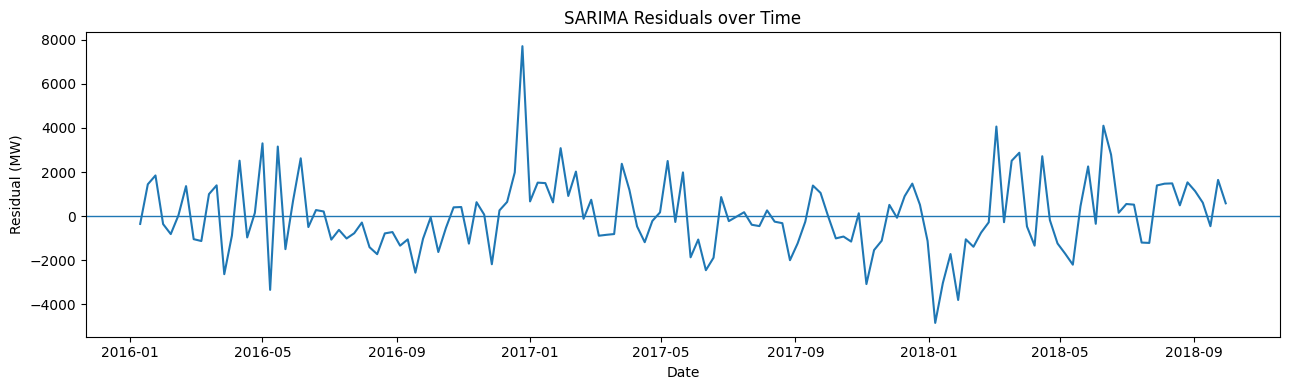

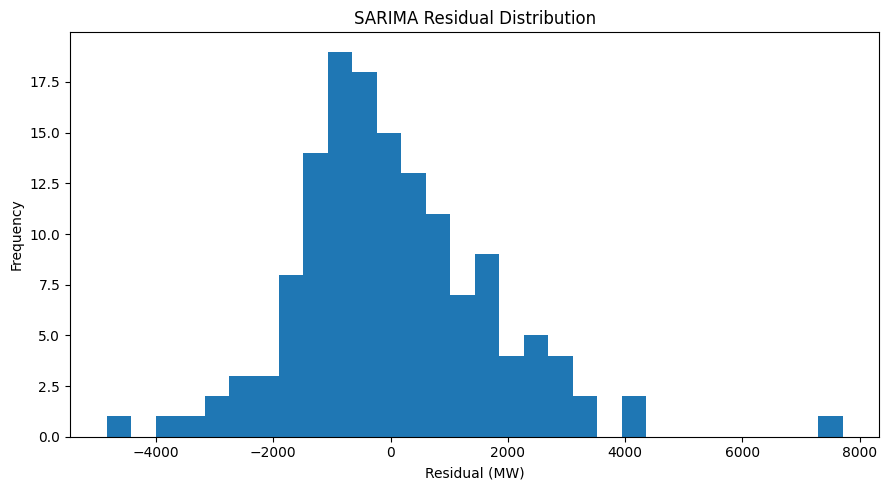

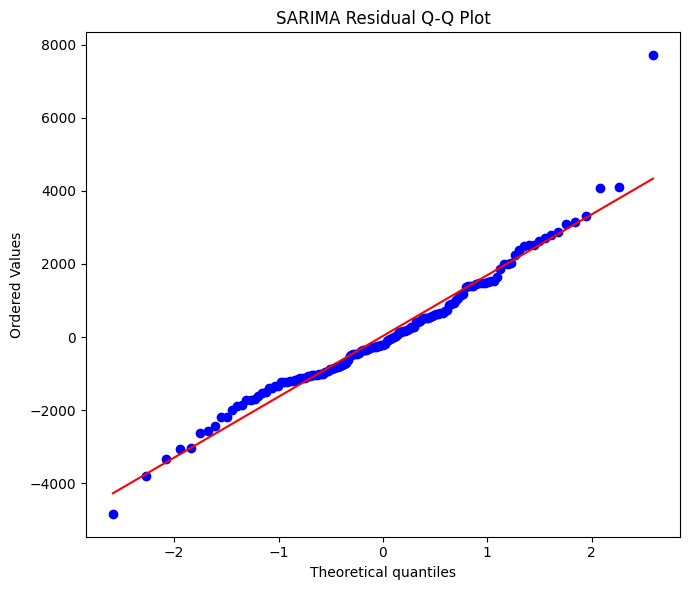

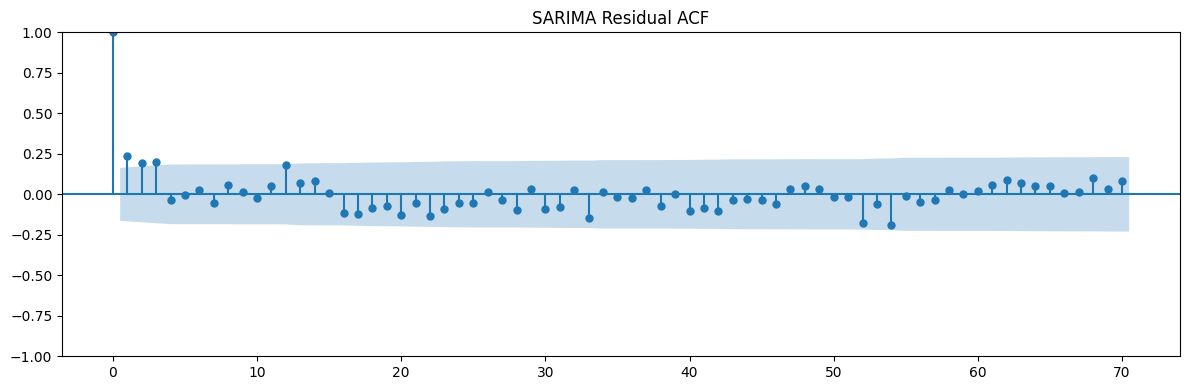

      lb_stat  lb_pvalue
1    8.079460   0.004477
4   19.663763   0.000582
12  26.551053   0.008962
26  43.987996   0.015161
52  69.701097   0.051101
    order seasonal_order  minimum_ljung_box_p  residual_screen_alpha  passes_residual_screen  minimum_root_modulus  root_margin_threshold  passes_root_screen  covariance_condition_number                                                                                                                                                                                                                    selection_note
(0, 0, 0)  (1, 1, 1, 52)             0.000582                   0.01                   False               1.00003                  1.001               False                 3.908666e+28 Full-grid minimum-AIC ranking (converged and forecast-stable); selected AIC=2535.16. Refit failures above it: 0. Residual correlation and AR/MA roots are DIAGNOSTICS and limitations, not alternative hidden selection criteria.
Diagnostic limitation: r

In [20]:
# Residual diagnostics required by the assignment.
burn = max(10, best_seasonal_order[3])
sarima_residuals = best_model.resid.iloc[burn:].dropna()

plt.figure(figsize=(13, 4))
plt.plot(sarima_residuals.index, sarima_residuals.values)
plt.axhline(0, linewidth=1)
plt.title("SARIMA Residuals over Time")
plt.xlabel("Date")
plt.ylabel("Residual (MW)")
finish_plot("10_sarima_residual_time.png")

plt.figure(figsize=(9, 5))
plt.hist(sarima_residuals, bins=30)
plt.title("SARIMA Residual Distribution")
plt.xlabel("Residual (MW)")
plt.ylabel("Frequency")
finish_plot("11_sarima_residual_histogram.png")

plt.figure(figsize=(7, 6))
stats.probplot(sarima_residuals, dist="norm", plot=plt)
plt.title("SARIMA Residual Q-Q Plot")
finish_plot("12_sarima_residual_qq.png")

fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(
    sarima_residuals,
    lags=min(104, len(sarima_residuals) // 2 - 1),
    ax=ax,
)
ax.set_title("SARIMA Residual ACF")
finish_plot("13_sarima_residual_acf.png")

ljung_lags = [lag for lag in (1, 4, 12, 26, 52) if lag < len(sarima_residuals)]
sarima_ljung_box = acorr_ljungbox(
    sarima_residuals, lags=ljung_lags, return_df=True
)
sarima_ljung_box.to_csv(TABLE_DIR / "sarima_ljung_box.csv")
minimum_ljung_p = float(sarima_ljung_box["lb_pvalue"].min())
minimum_root_modulus = minimum_ar_ma_root_modulus(best_model)
try:
    covariance_condition_number = float(np.linalg.cond(np.asarray(best_model.cov_params())))
except Exception:
    covariance_condition_number = np.nan

sarima_diagnostic_summary = pd.DataFrame([{
    "order": str(best_order),
    "seasonal_order": str(best_seasonal_order),
    "minimum_ljung_box_p": minimum_ljung_p,
    "residual_screen_alpha": SARIMA_RESIDUAL_ALPHA,
    "passes_residual_screen": minimum_ljung_p > SARIMA_RESIDUAL_ALPHA,
    "minimum_root_modulus": minimum_root_modulus,
    "root_margin_threshold": SARIMA_ROOT_MARGIN,
    "passes_root_screen": minimum_root_modulus > SARIMA_ROOT_MARGIN,
    "covariance_condition_number": covariance_condition_number,
    "selection_note": selection_note,
}])
sarima_diagnostic_summary.to_csv(
    TABLE_DIR / "sarima_diagnostic_summary.csv", index=False
)

print(sarima_ljung_box)
print(sarima_diagnostic_summary.to_string(index=False))
if minimum_ljung_p <= SARIMA_RESIDUAL_ALPHA:
    print(
        "Diagnostic limitation: residual autocorrelation remains at the strict "
        f"{SARIMA_RESIDUAL_ALPHA:.0%} level and must be discussed in the report."
    )
else:
    print(
        "No severe residual autocorrelation was detected at the pre-specified "
        f"{SARIMA_RESIDUAL_ALPHA:.0%} level across the reported lags."
    )

from scipy.stats import jarque_bera
jb_statistic, jb_pvalue = jarque_bera(sarima_residuals)
sarima_diagnostic_summary["residual_mean_MW"] = float(sarima_residuals.mean())
sarima_diagnostic_summary["residual_std_MW"] = float(sarima_residuals.std())
sarima_diagnostic_summary["jarque_bera_p"] = float(jb_pvalue)
sarima_diagnostic_summary.to_csv(TABLE_DIR / "sarima_diagnostic_summary.csv", index=False)
if np.isfinite(covariance_condition_number) and covariance_condition_number > 1e10:
    print("CAUTION: SARIMA covariance matrix is ill-conditioned; interpret intervals cautiously.")

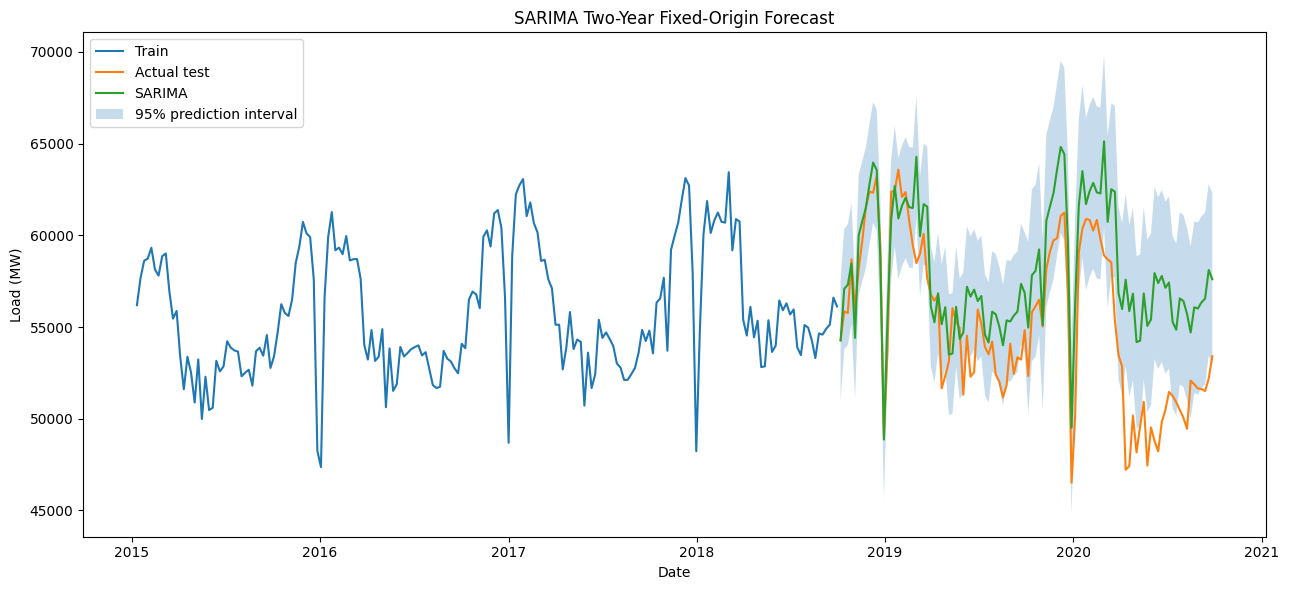

 Model Frequency                 Protocol   N       RMSE         MAE  sMAPE_pct     MASE
SARIMA    Weekly Fixed-origin operational 104 3890.55546 3116.197315   5.640106 2.306477
 Model  nominal_coverage  empirical_test_coverage  average_interval_width_MW  evaluation_only
SARIMA              0.95                 0.701923                7982.377104             True


In [21]:
sarima_forecast_object = best_model.get_forecast(steps=len(test_weekly))
sarima_forecast = pd.Series(
    sarima_forecast_object.predicted_mean.to_numpy(), index=test_weekly.index, name="SARIMA"
)
sarima_confidence = sarima_forecast_object.conf_int(alpha=0.05).copy()
sarima_confidence.index = test_weekly.index

if not np.all(np.isfinite(sarima_forecast)):
    raise RuntimeError("Selected SARIMA produced non-finite forecasts.")

weekly_forecasts["SARIMA"] = sarima_forecast
forecast_metadata["SARIMA"] = ("Fixed-origin operational", "Weekly")

plt.figure(figsize=(13, 6))
plt.plot(train_weekly.index, train_weekly.values, label="Train")
plt.plot(test_weekly.index, test_weekly.values, label="Actual test")
plt.plot(sarima_forecast.index, sarima_forecast.values, label="SARIMA")
plt.fill_between(
    test_weekly.index,
    sarima_confidence.iloc[:, 0].to_numpy(),
    sarima_confidence.iloc[:, 1].to_numpy(),
    alpha=0.25,
    label="95% prediction interval",
)
plt.title("SARIMA Two-Year Fixed-Origin Forecast")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
plt.legend()
finish_plot("14_sarima_forecast.png")

sarima_metric = metric_record(
    "SARIMA", test_weekly, sarima_forecast, train_weekly,
    SEASONAL_PERIOD_WEEKLY, "Fixed-origin operational", "Weekly"
)
print(pd.DataFrame([sarima_metric]).to_string(index=False))

# Empirical *test* interval coverage is an evaluation metric, not used for tuning.
sarima_interval_coverage = float(((test_weekly >= sarima_confidence.iloc[:, 0]) &
                                  (test_weekly <= sarima_confidence.iloc[:, 1])).mean())
sarima_interval_summary = pd.DataFrame([{
    "Model": "SARIMA", "nominal_coverage": 0.95,
    "empirical_test_coverage": sarima_interval_coverage,
    "average_interval_width_MW": float((sarima_confidence.iloc[:, 1] -
                                        sarima_confidence.iloc[:, 0]).mean()),
    "evaluation_only": True,
}])
sarima_interval_summary.to_csv(TABLE_DIR / "sarima_interval_coverage.csv", index=False)
print(sarima_interval_summary.to_string(index=False))

### SARIMA residual, numerical and interval adequacy assessment

The compulsory minimum-AIC model remains the **primary** forecast even if its diagnostics fail.
A Ljung-Box p-value at or below the predeclared 1% level indicates residual correlation;
a root modulus close to 1 raises stability concerns; a high covariance condition number
suggests fragile parameter uncertainty. These diagnostics **do not** justify selecting a
replacement using held-out forecast errors. Empirical 95% interval coverage is a
post-selection **test diagnostic**, never used for model choice or interval calibration.

The generated `sarima_diagnostic_interpretation.csv` records exact observed values,
thresholds, pass/warning labels and consequences. The accompanying plot compares
nominal and observed interval coverage. Retain all failures in the report.

                                   Diagnostic     Observed                                                      Criterion    Assessment                                             Inference                                                       Selection_use
   Residual independence: minimum Ljung-Box p 5.817976e-04                                                       p > 0.01       WARNING                      Residual autocorrelation remains Training-only diagnostic; not a hidden filter for primary AIC model
                   AR/MA minimum root modulus 1.000030e+00                                           root modulus > 1.001       WARNING Near-boundary roots; long-range numerical sensitivity                                            Training-only diagnostic
        Estimated covariance condition number 3.908666e+28                       finite and <= 1e10 (heuristic threshold)       WARNING           Parameter covariance may be ill-conditioned                  Training-only diagn

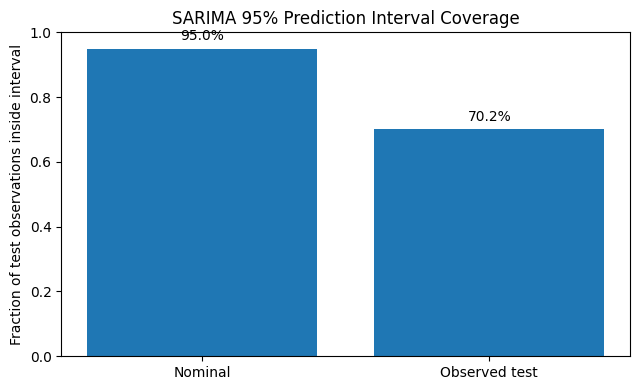

In [22]:
# Report model adequacy transparently, without changing the minimum-AIC forecast.
_sarima_summary = sarima_diagnostic_summary.iloc[0]
_nominal_coverage = 0.95
_observed_coverage = float(sarima_interval_coverage)
_min_ljung = float(_sarima_summary["minimum_ljung_box_p"])
_root_modulus = float(_sarima_summary["minimum_root_modulus"])
_cov_condition = float(_sarima_summary["covariance_condition_number"])
_jb_p = float(_sarima_summary["jarque_bera_p"])
sarima_diagnostic_interpretation = pd.DataFrame([
    {
        "Diagnostic": "Residual independence: minimum Ljung-Box p",
        "Observed": _min_ljung,
        "Criterion": f"p > {SARIMA_RESIDUAL_ALPHA}",
        "Assessment": "PASS" if _min_ljung > SARIMA_RESIDUAL_ALPHA else "WARNING",
        "Inference": "Residual autocorrelation remains" if _min_ljung <= SARIMA_RESIDUAL_ALPHA
                     else "No evidence of residual dependence at the declared lags and level",
        "Selection_use": "Training-only diagnostic; not a hidden filter for primary AIC model",
    },
    {
        "Diagnostic": "AR/MA minimum root modulus",
        "Observed": _root_modulus,
        "Criterion": f"root modulus > {SARIMA_ROOT_MARGIN}",
        "Assessment": "PASS" if _root_modulus > SARIMA_ROOT_MARGIN else "WARNING",
        "Inference": "Near-boundary roots; long-range numerical sensitivity" if _root_modulus <= SARIMA_ROOT_MARGIN
                     else "Roots exceed selected safety margin",
        "Selection_use": "Training-only diagnostic",
    },
    {
        "Diagnostic": "Estimated covariance condition number",
        "Observed": _cov_condition,
        "Criterion": "finite and <= 1e10 (heuristic threshold)",
        "Assessment": "PASS" if np.isfinite(_cov_condition) and _cov_condition <= 1e10 else "WARNING",
        "Inference": "Parameter covariance may be ill-conditioned" if not np.isfinite(_cov_condition) or _cov_condition > 1e10
                     else "No severe numerical ill-conditioning by this heuristic",
        "Selection_use": "Training-only diagnostic; threshold is descriptive",
    },
    {
        "Diagnostic": "Jarque-Bera residual normality p",
        "Observed": _jb_p,
        "Criterion": "p > 0.05",
        "Assessment": "PASS" if _jb_p > 0.05 else "WARNING",
        "Inference": "Normality assumption questionable" if _jb_p <= 0.05
                     else "No evidence against normality from this test",
        "Selection_use": "Training-only diagnostic",
    },
    {
        "Diagnostic": "Nominal 95% predictive-interval test coverage",
        "Observed": _observed_coverage,
        "Criterion": "0.95 nominal; test coverage descriptive (not a pass/fail test)",
        "Assessment": "UNDERCOVERAGE" if _observed_coverage < 0.95 else "AT/ABOVE NOMINAL",
        "Inference": f"Observed coverage minus nominal = {_observed_coverage-0.95:.2%}",
        "Selection_use": "Test-only evaluation; never used for selection or calibration",
    },
])
sarima_diagnostic_interpretation.to_csv(
    TABLE_DIR / "sarima_diagnostic_interpretation.csv", index=False)
print(sarima_diagnostic_interpretation.to_string(index=False))

plt.figure(figsize=(6.5, 4))
plt.bar(["Nominal", "Observed test"], [_nominal_coverage, _observed_coverage])
plt.ylim(0, 1.0)
plt.ylabel("Fraction of test observations inside interval")
plt.title("SARIMA 95% Prediction Interval Coverage")
for _i, _coverage in enumerate([_nominal_coverage, _observed_coverage]):
    plt.text(_i, min(0.98, _coverage + 0.025), f"{_coverage:.1%}", ha="center")
finish_plot("14b_sarima_interval_reliability.png")

In [23]:
# Evaluate the pre-selected alternative only AFTER the main SARIMA forecast exists.
# Never select/tune based on these test errors.
if sensitivity_model is not None:
    sensitivity_evaluation = pd.DataFrame([
        {"candidate": "Primary AIC winner", "RMSE_MW": rmse(test_weekly, sarima_forecast),
         "MAE_MW": float(mean_absolute_error(test_weekly, sarima_forecast)),
         "empirical_95pct_interval_coverage": sarima_interval_coverage},
        {"candidate": "Training-residual sensitivity (NOT primary)",
         "RMSE_MW": rmse(test_weekly, sarima_sensitivity_prediction),
         "MAE_MW": float(mean_absolute_error(test_weekly, sarima_sensitivity_prediction)),
         "empirical_95pct_interval_coverage": float((
             (test_weekly >= sarima_sensitivity_interval.iloc[:, 0]) &
             (test_weekly <= sarima_sensitivity_interval.iloc[:, 1])
         ).mean())},
    ])
    sensitivity_evaluation.to_csv(TABLE_DIR / "sarima_sensitivity_test_evaluation.csv", index=False)
    print("Hindsight evaluation — not used for model selection:")
    print(sensitivity_evaluation.to_string(index=False))
    sensitivity_prediction_frame = pd.DataFrame({
        "actual_MW": test_weekly,
        "primary_AIC_MW": sarima_forecast,
        "training_diagnostic_sensitivity_MW": sarima_sensitivity_prediction,
    })
    sensitivity_prediction_frame.to_csv(
        TABLE_DIR / "sarima_sensitivity_predictions.csv", index_label="week_end_utc"
    )


Hindsight evaluation — not used for model selection:
                                  candidate     RMSE_MW      MAE_MW  empirical_95pct_interval_coverage
                         Primary AIC winner 3890.555460 3116.197315                           0.701923
Training-residual sensitivity (NOT primary) 3869.479364 3097.818777                           0.692308


## Part 4 — Berlin temperature, German holidays and SARIMAX ablation

Load timestamps are UTC. The Open-Meteo daily-temperature series is requested with UTC calendar-day boundaries so that Sunday-ending weeks use the same time basis. National holidays are assigned by German civil date (a minor approximation at week boundaries). Berlin is a *representative weather proxy*, not national population-weighted exposure. Climatological future temperatures are forecast-time **scenarios**, not observed future weather.

In [24]:
TEMPERATURE_CACHE = DATA_DIR / "berlin_temperature_daily_utc.csv"
# Optional offline/Kaggle input: a previously generated Berlin temperature cache.
if not TEMPERATURE_CACHE.exists() and INPUT_ROOT.exists():
    candidate_temperature_caches = list(INPUT_ROOT.rglob("berlin_temperature_daily_utc.csv"))
    if len(candidate_temperature_caches) == 1:
        import shutil
        shutil.copy2(candidate_temperature_caches[0], TEMPERATURE_CACHE)
        print("Using attached Berlin temperature cache:", candidate_temperature_caches[0])
    elif len(candidate_temperature_caches) > 1:
        raise RuntimeError("Multiple Berlin temperature caches attached; keep only the intended source.")


def fetch_berlin_temperature(start_date: str, end_date: str) -> pd.Series:
    if TEMPERATURE_CACHE.exists():
        cached = pd.read_csv(TEMPERATURE_CACHE, parse_dates=["date"]).set_index("date")
        if "temperature_2m_mean" not in cached:
            raise KeyError("Cached temperature file needs temperature_2m_mean column")
        cached_series = pd.to_numeric(cached["temperature_2m_mean"], errors="coerce")
        expected_days = pd.date_range(start_date, end_date, freq="D")
        if cached.index.duplicated().any() or not expected_days.isin(cached.index).all():
            raise ValueError("Attached cached Berlin temperature has duplicates/missing source days")
        return cached_series.reindex(expected_days).rename("temperature_2m_mean")

    endpoint = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": 52.52,
        "longitude": 13.41,
        "start_date": start_date,
        "end_date": end_date,
        "daily": "temperature_2m_mean",
        "timezone": "UTC",  # Match the OPSD UTC-hour calendar boundaries.
    }
    response = requests.get(endpoint, params=params, timeout=60)
    response.raise_for_status()
    payload = response.json()
    if "daily" not in payload:
        raise ValueError(f"Unexpected Open-Meteo response: {payload}")

    temperature = pd.Series(
        payload["daily"]["temperature_2m_mean"],
        index=pd.to_datetime(payload["daily"]["time"]),
        name="temperature_2m_mean",
        dtype=float,
    )
    temperature.to_frame().rename_axis("date").to_csv(TEMPERATURE_CACHE)
    return temperature


def weekly_temperature_climatology(
    reference_temperature: pd.Series,
    target_index: pd.DatetimeIndex,
) -> pd.Series:
    """Create a week-of-year climatology using reference data only."""
    reference_temperature = reference_temperature.dropna().astype(float)
    reference_weeks = reference_temperature.index.isocalendar().week.astype(int)
    week_means = reference_temperature.groupby(reference_weeks).mean()
    overall_mean = float(reference_temperature.mean())
    values = [
        float(week_means.get(int(week), overall_mean))
        for week in target_index.isocalendar().week
    ]
    return pd.Series(values, index=target_index, name="temp_climatology")


temperature_daily = fetch_berlin_temperature(
    load_hourly.index.min().strftime("%Y-%m-%d"),
    load_hourly.index.max().strftime("%Y-%m-%d"),
)
temperature_weekly = temperature_daily.resample(WEEK_FREQ).mean().reindex(weekly_load.index)

# National German public holidays. State-specific holidays are not included.
holiday_calendar = holidays.Germany(
    years=range(load_hourly.index.min().year, load_hourly.index.max().year + 1)
)
holiday_daily = pd.Series(
    1.0,
    index=pd.DatetimeIndex(pd.to_datetime(list(holiday_calendar.keys()))),
    name="holiday",
)
holiday_weekly = holiday_daily.resample(WEEK_FREQ).sum().reindex(
    weekly_load.index, fill_value=0.0
)

exog_weekly = pd.DataFrame({
    "temp_observed": temperature_weekly,
    "holiday_count": holiday_weekly,
}, index=weekly_load.index)

if exog_weekly["temp_observed"].isna().any():
    missing_temperature_weeks = exog_weekly.index[
        exog_weekly["temp_observed"].isna()
    ].tolist()
    raise ValueError(
        f"Temperature is missing for {len(missing_temperature_weeks)} weekly periods. "
        "Inspect the API response instead of interpolating future values."
    )

# Training-only climatology for an operational long-horizon temperature proxy.
train_temp = exog_weekly.loc[train_weekly.index, "temp_observed"]
exog_weekly["temp_climatology"] = weekly_temperature_climatology(
    train_temp, exog_weekly.index
)

exog_weekly.to_csv(DATA_DIR / "weekly_temperature_holidays.csv")
print(exog_weekly.head())
print(exog_weekly.tail())

# Record weather coordinates, forecast availability and file checksum for independent reproduction.
_weather_hash = hashlib.sha256(TEMPERATURE_CACHE.read_bytes()).hexdigest()
_weather_metadata = {
    "provider": "Open-Meteo Historical Weather Archive",
    "endpoint": "https://archive-api.open-meteo.com/v1/archive",
    "latitude": 52.52,
    "longitude": 13.41,
    "timezone": "UTC",
    "variable": "daily temperature_2m_mean (C)",
    "weather_cache_sha256": _weather_hash,
    "training_weather_last_week": str(train_temp.index.max()),
    "forecast_origin": str(forecast_start),
    "future_observed_weather_known_at_origin": False,
    "operational_weather_method": "Week-of-year climatology estimated from the training period only",
}
(TABLE_DIR / "weather_source_provenance.json").write_text(
    json.dumps(_weather_metadata, indent=2), encoding="utf-8"
)
assert train_temp.index.max() < test_weekly.index.min()
assert temperature_daily.loc[load_hourly.index.min().normalize():load_hourly.index.max().normalize()].notna().all()
print("Weather data provenance and chronological coverage recorded.")


            temp_observed  holiday_count  temp_climatology
2015-01-11       3.914286            0.0          0.885714
2015-01-18       4.842857            0.0         -0.182143
2015-01-25       0.057143            0.0          2.539286
2015-02-01       1.400000            0.0          2.635714
2015-02-08      -1.228571            0.0         -0.507143
            temp_observed  holiday_count  temp_climatology
2020-08-30      17.728571            0.0         18.950000
2020-09-06      15.942857            0.0         18.110714
2020-09-13      16.485714            0.0         16.842857
2020-09-20      17.214286            0.0         15.700000
2020-09-27      15.000000            0.0         13.925000
Weather data provenance and chronological coverage recorded.


Weekly load-temperature Pearson correlation: -0.6780


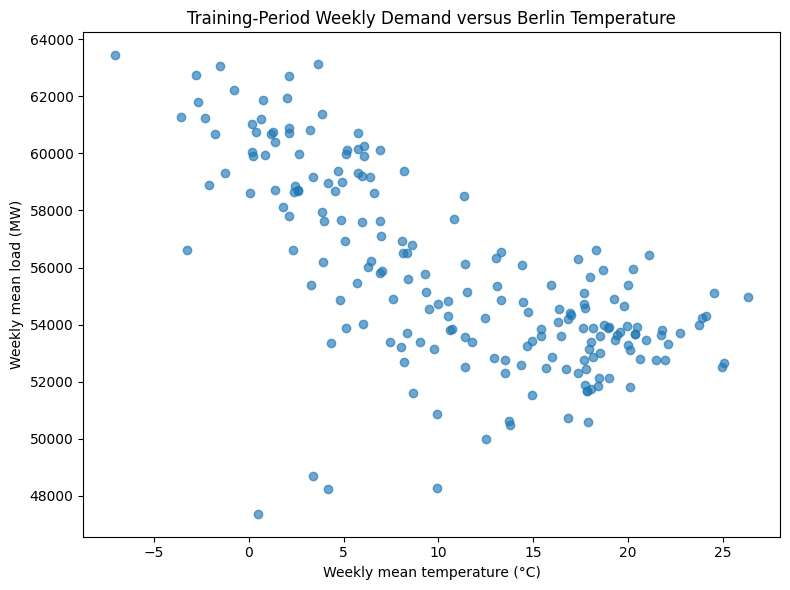

                               count          mean          std
No national holiday              165  56306.177850  3147.459586
At least one national holiday     30  52370.574802  2302.723526


In [25]:
relationship_data = pd.DataFrame({
    "load": train_weekly,
    "temperature": exog_weekly.loc[train_weekly.index, "temp_observed"],
    "holiday_count": exog_weekly.loc[train_weekly.index, "holiday_count"],
}).dropna()

correlation = relationship_data[["load", "temperature"]].corr().iloc[0, 1]
print(f"Weekly load-temperature Pearson correlation: {correlation:.4f}")

plt.figure(figsize=(8, 6))
plt.scatter(relationship_data["temperature"], relationship_data["load"], alpha=0.65)
plt.title("Training-Period Weekly Demand versus Berlin Temperature")
plt.xlabel("Weekly mean temperature (°C)")
plt.ylabel("Weekly mean load (MW)")
finish_plot("15_temperature_load_relationship.png")

holiday_group_summary = relationship_data.groupby(
    relationship_data["holiday_count"] > 0
)["load"].agg(["count", "mean", "std"])
holiday_group_summary.index = ["No national holiday", "At least one national holiday"]
holiday_group_summary.to_csv(TABLE_DIR / "holiday_week_load_summary.csv")
print(holiday_group_summary)

### Temperature association after controlling for the annual calendar

A raw temperature-load correlation can be dominated by shared seasonality. The following **training-only** check correlates departures from each ISO week's average load and temperature. It is a descriptive association, not proof of causality, and is not used to select the final forecasting models.

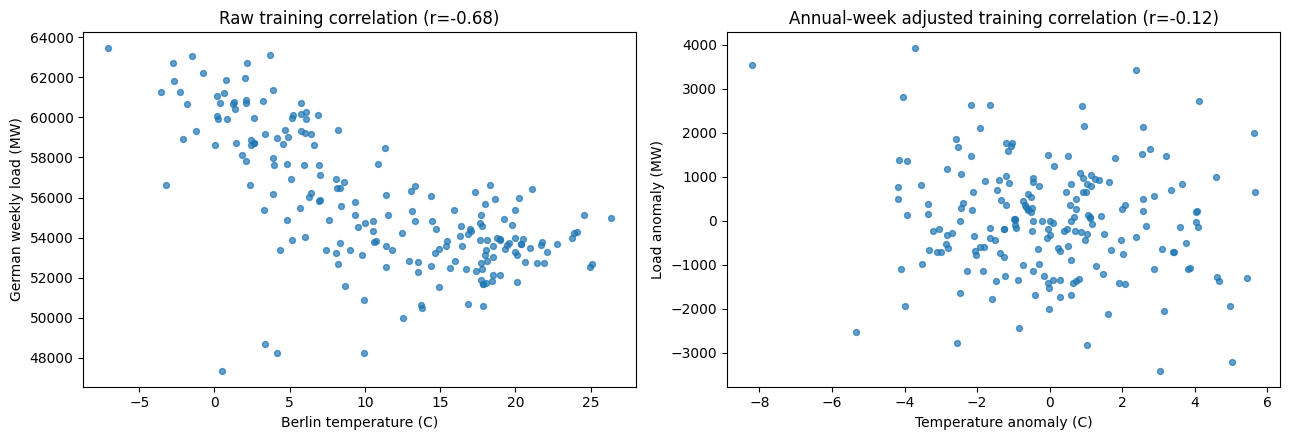

                     Specification  Pearson_r   N  Causal_claim
        Raw training weekly series  -0.677962 195         False
Within-ISO-week training anomalies  -0.124213 195         False


In [26]:
# Compare raw association with within-week-of-year anomalies on training data only.
_train_association = pd.DataFrame({
    "load_MW": train_weekly,
    "temperature_C": exog_weekly.loc[train_weekly.index, "temp_observed"],
}).dropna()
_annual_week = _train_association.index.isocalendar().week.to_numpy(dtype=int)
_train_association["iso_week"] = _annual_week
for _column in ("load_MW", "temperature_C"):
    _train_association[f"{_column}_anomaly"] = (
        _train_association[_column] -
        _train_association.groupby("iso_week")[_column].transform("mean")
    )
_raw_r = _train_association["load_MW"].corr(_train_association["temperature_C"])
_anomaly_r = _train_association["load_MW_anomaly"].corr(
    _train_association["temperature_C_anomaly"])
_temperature_association = pd.DataFrame([
    {"Specification": "Raw training weekly series", "Pearson_r": float(_raw_r),
     "N": len(_train_association), "Causal_claim": False},
    {"Specification": "Within-ISO-week training anomalies", "Pearson_r": float(_anomaly_r),
     "N": len(_train_association), "Causal_claim": False},
])
_temperature_association.to_csv(TABLE_DIR / "training_temperature_association.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(_train_association["temperature_C"], _train_association["load_MW"],
                s=18, alpha=0.7)
axes[0].set(title=f"Raw training correlation (r={_raw_r:.2f})",
            xlabel="Berlin temperature (C)", ylabel="German weekly load (MW)")
axes[1].scatter(_train_association["temperature_C_anomaly"],
                _train_association["load_MW_anomaly"], s=18, alpha=0.7)
axes[1].set(title=f"Annual-week adjusted training correlation (r={_anomaly_r:.2f})",
            xlabel="Temperature anomaly (C)", ylabel="Load anomaly (MW)")
finish_plot("15b_temperature_seasonal_anomaly_association.png")
print(_temperature_association.to_string(index=False))

In [27]:
def fit_sarimax_exog(train_y, train_exog, test_exog, order, seasonal_order):
    scaler = StandardScaler()
    train_scaled_exog = pd.DataFrame(
        scaler.fit_transform(train_exog), index=train_exog.index, columns=train_exog.columns
    )
    test_scaled_exog = pd.DataFrame(
        scaler.transform(test_exog), index=test_exog.index, columns=test_exog.columns
    )

    fitted = None
    last_error = None
    for method in ("lbfgs", "powell"):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                model = SARIMAX(
                    train_y,
                    exog=train_scaled_exog,
                    order=order,
                    seasonal_order=seasonal_order,
                    trend="n",
                    enforce_stationarity=True,
                    enforce_invertibility=True,
                )
                candidate = model.fit(disp=False, method=method, maxiter=300)
            finite_fit = np.all(np.isfinite(candidate.params)) and np.isfinite(candidate.aic)
            if not candidate.mle_retvals.get("converged", False) or not finite_fit:
                continue
            fitted = candidate
            break
        except Exception as exc:
            last_error = exc

    if fitted is None:
        raise RuntimeError(f"SARIMAX fitting failed: {last_error}")

    forecast_object = fitted.get_forecast(steps=len(test_exog), exog=test_scaled_exog)
    forecast = pd.Series(
        forecast_object.predicted_mean.to_numpy(), index=test_exog.index
    )
    confidence = forecast_object.conf_int(alpha=0.05).copy()
    confidence.index = test_exog.index

    if (
        not np.all(np.isfinite(forecast))
        or not np.all(np.isfinite(confidence.to_numpy()))
        or forecast.max() >= train_y.max() * 3.0
        or forecast.min() <= -0.25 * train_y.mean()
    ):
        raise RuntimeError("SARIMAX forecast failed the numerical stability check.")

    burn = max(10, seasonal_order[3])
    residuals = fitted.resid.iloc[burn:].dropna()
    diagnostic_lags = [lag for lag in (1, 4, 12, 26, 52) if lag < len(residuals)]
    ljung = acorr_ljungbox(residuals, lags=diagnostic_lags, return_df=True)
    minimum_p = float(ljung["lb_pvalue"].min()) if not ljung.empty else np.nan

    diagnostics = {
        "aic": float(fitted.aic),
        "bic": float(fitted.bic),
        "minimum_ljung_box_p": minimum_p,
        "passes_residual_screen": bool(
            np.isnan(minimum_p) or minimum_p > SARIMA_RESIDUAL_ALPHA
        ),
        "minimum_root_modulus": minimum_ar_ma_root_modulus(fitted),
    }
    return fitted, scaler, forecast, confidence, diagnostics


train_exog_all = exog_weekly.loc[train_weekly.index]
test_exog_all = exog_weekly.loc[test_weekly.index]

sarimax_designs = {
    "SARIMAX Holidays": {
        "train": train_exog_all[["holiday_count"]],
        "test": test_exog_all[["holiday_count"]],
        "protocol": "Fixed-origin operational",
    },
    "SARIMAX Temperature Conditional": {
        "train": train_exog_all[["temp_observed"]],
        "test": test_exog_all[["temp_observed"]],
        "protocol": "Fixed-origin conditional: observed future temperature",
    },
    "SARIMAX Temp+Holiday Conditional": {
        "train": train_exog_all[["temp_observed", "holiday_count"]],
        "test": test_exog_all[["temp_observed", "holiday_count"]],
        "protocol": "Fixed-origin conditional: observed future temperature",
    },
    "SARIMAX Climatology Operational": {
        "train": train_exog_all[["temp_observed"]],
        "test": test_exog_all[["temp_climatology"]].rename(
            columns={"temp_climatology": "temp_observed"}),
        "protocol": "Fixed-origin operational: forecast temperature climatology",
    },
    "SARIMAX Climatology+Holiday Operational": {
        # Historical relationship must be learned from OBSERVED historical temperature.
        # Only the unknown future temperature is substituted by training-only climatology.
        "train": train_exog_all[["temp_observed", "holiday_count"]],
        "test": test_exog_all[["temp_climatology", "holiday_count"]].rename(
            columns={"temp_climatology": "temp_observed"}),
        "protocol": "Fixed-origin operational: training-only temperature climatology",
    },
}

sarimax_fits = {}
sarimax_confidence_intervals = {}
sarimax_diagnostic_records = []
for model_name, design in sarimax_designs.items():
    fitted, scaler, forecast, confidence, diagnostics = fit_sarimax_exog(
        train_weekly,
        design["train"],
        design["test"],
        best_order,
        best_seasonal_order,
    )
    forecast.name = model_name
    sarimax_fits[model_name] = fitted
    sarimax_confidence_intervals[model_name] = confidence
    weekly_forecasts[model_name] = forecast
    forecast_metadata[model_name] = (design["protocol"], "Weekly")
    interval_coverage = float(((test_weekly >= confidence.iloc[:, 0]) &
                               (test_weekly <= confidence.iloc[:, 1])).mean())
    sarimax_diagnostic_records.append({"Model": model_name,
        "nominal_coverage": 0.95,
        "empirical_test_coverage": interval_coverage,
        "average_interval_width_MW": float((confidence.iloc[:, 1] - confidence.iloc[:, 0]).mean()),
        **diagnostics})
    print(model_name, rmse(test_weekly, forecast))

sarimax_diagnostics = pd.DataFrame(sarimax_diagnostic_records)
sarimax_diagnostics.to_csv(TABLE_DIR / "sarimax_residual_diagnostics.csv", index=False)
print(sarimax_diagnostics.to_string(index=False))

SARIMAX Holidays 3808.9199957347832
SARIMAX Temperature Conditional 3932.2369969990814
SARIMAX Temp+Holiday Conditional 3869.6505212543693
SARIMAX Climatology Operational 3981.2896440944173
SARIMAX Climatology+Holiday Operational 3912.0686695057884
                                  Model  nominal_coverage  empirical_test_coverage  average_interval_width_MW         aic         bic  minimum_ljung_box_p  passes_residual_screen  minimum_root_modulus
                       SARIMAX Holidays              0.95                 0.653846                6895.761409 2494.246242 2506.097621         8.783776e-09                   False              1.000019
        SARIMAX Temperature Conditional              0.95                 0.663462                7721.853270 2527.431367 2539.282746         4.266140e-03                   False              1.000028
       SARIMAX Temp+Holiday Conditional              0.95                 0.615385                6367.041173 2476.297205 2491.111428         2.5927

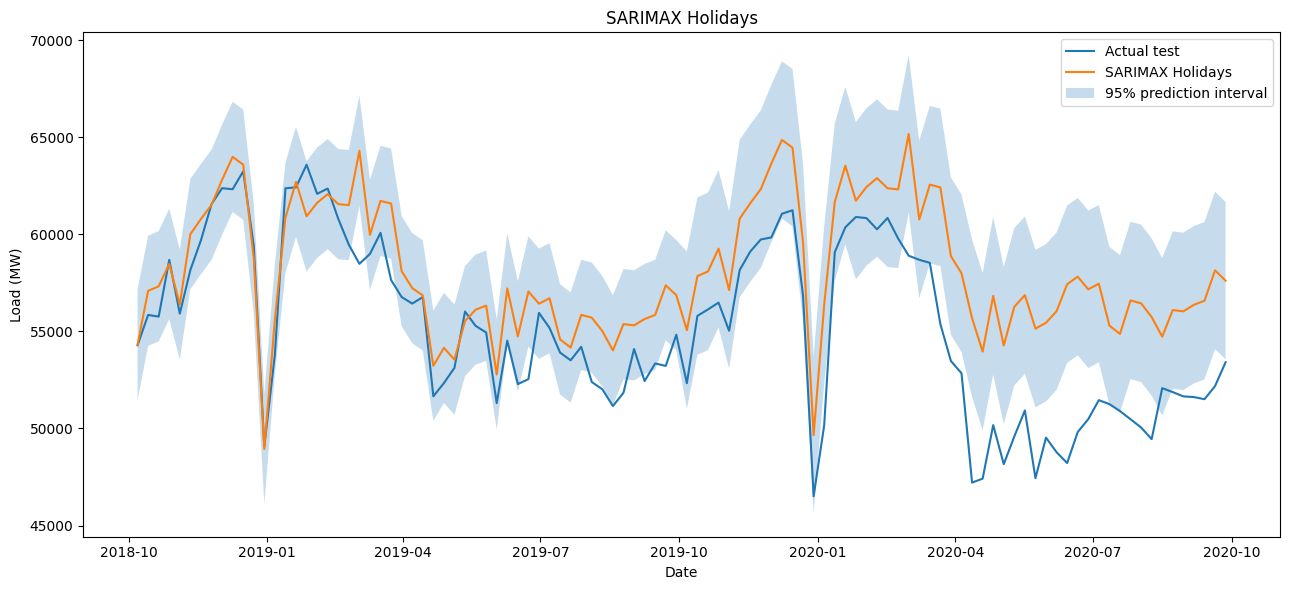

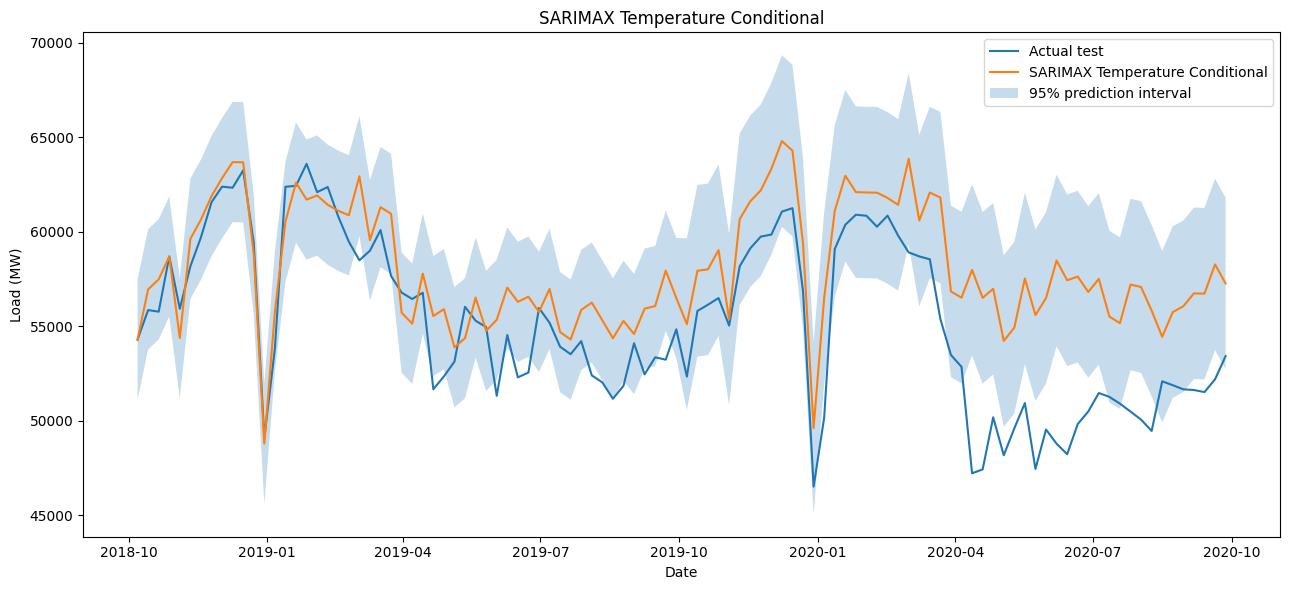

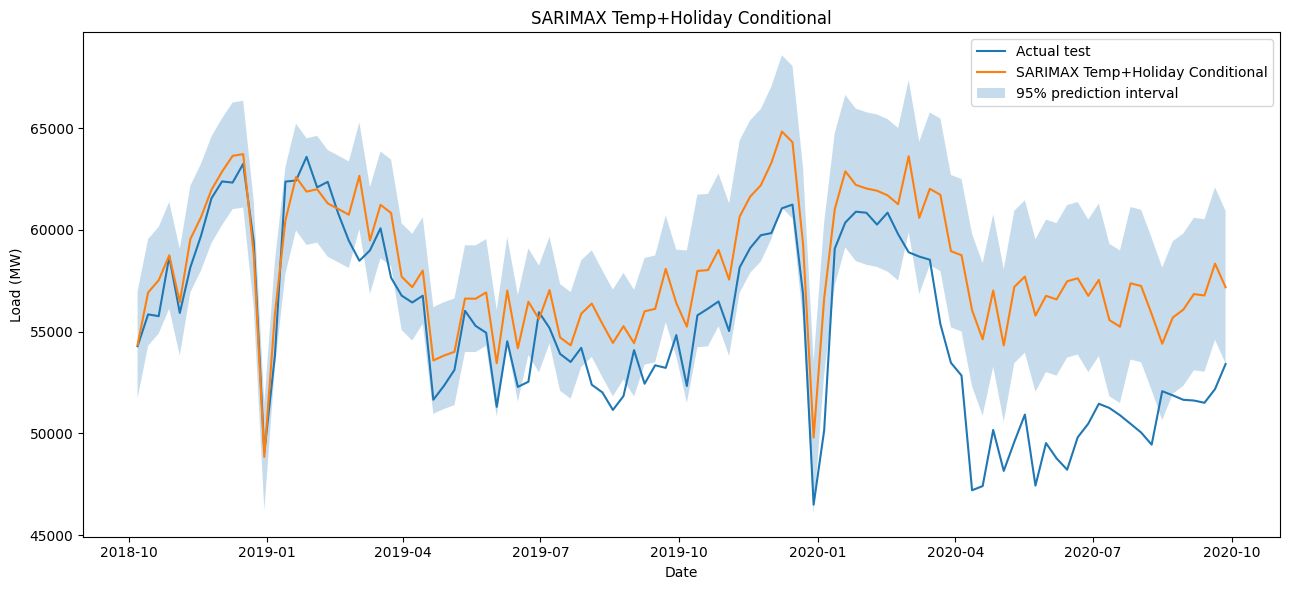

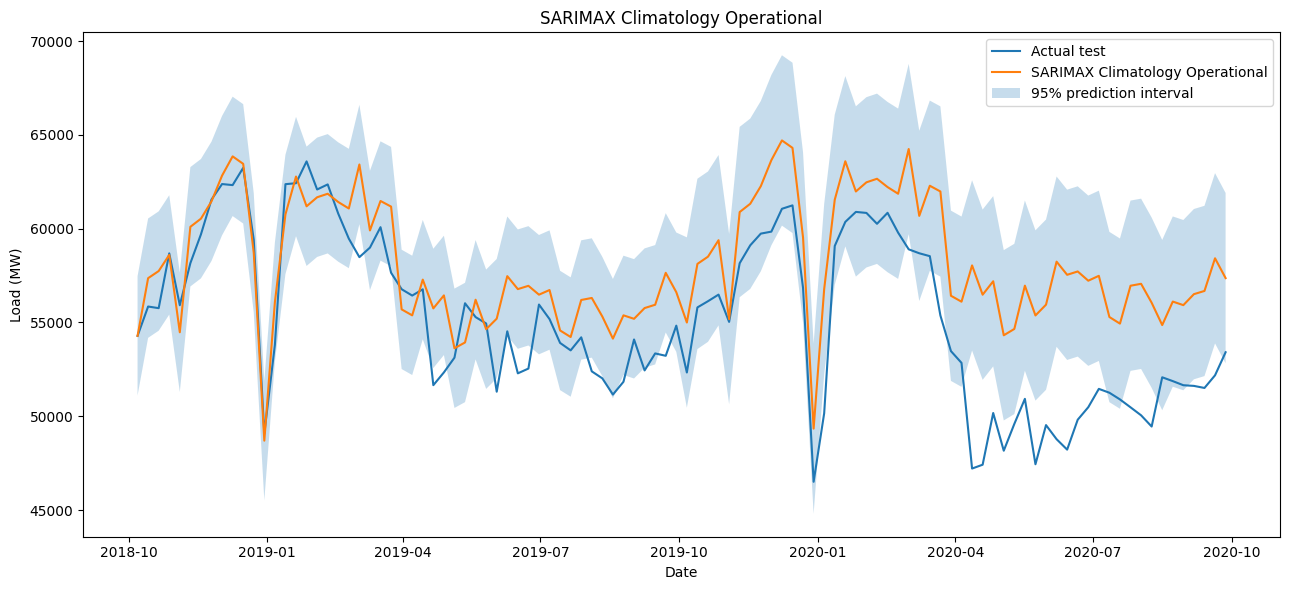

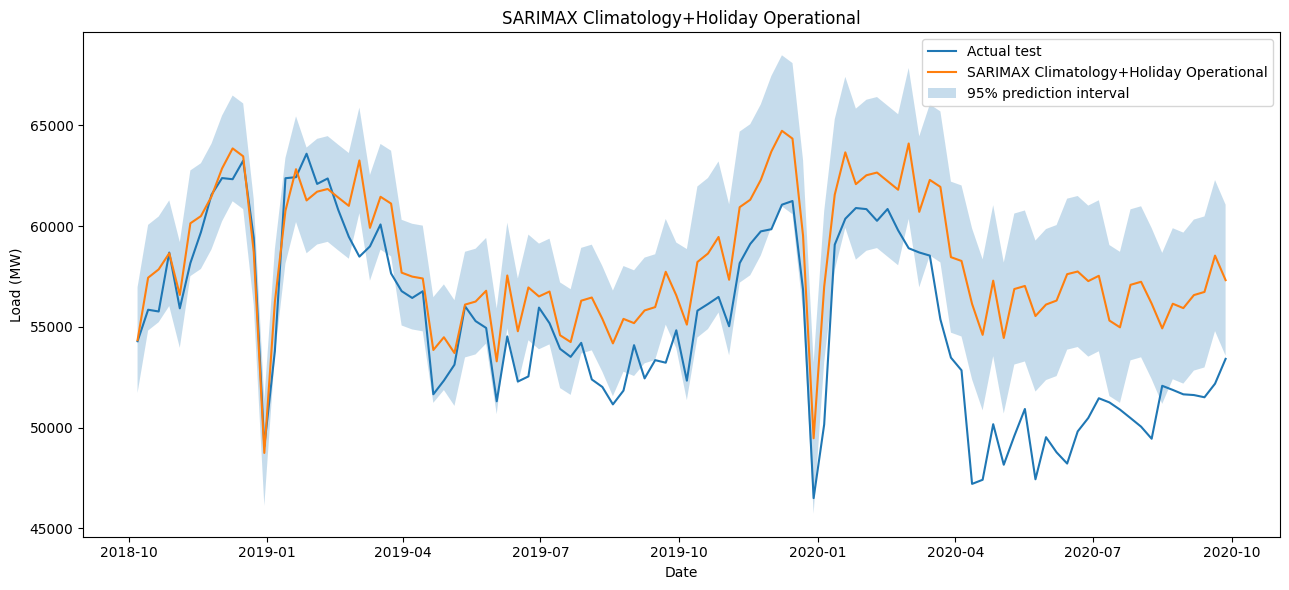

In [28]:
for model_name in sarimax_designs:
    forecast = weekly_forecasts[model_name]
    confidence = sarimax_confidence_intervals[model_name]
    plt.figure(figsize=(13, 6))
    plt.plot(test_weekly.index, test_weekly.values, label="Actual test")
    plt.plot(forecast.index, forecast.values, label=model_name)
    plt.fill_between(
        forecast.index,
        confidence.iloc[:, 0].to_numpy(),
        confidence.iloc[:, 1].to_numpy(),
        alpha=0.25,
        label="95% prediction interval",
    )
    plt.title(model_name)
    plt.xlabel("Date")
    plt.ylabel("Load (MW)")
    plt.legend()
    safe_name = model_name.lower().replace(" ", "_").replace("+", "plus")
    finish_plot(f"15_{safe_name}.png")

## Part 5 — Leakage-safe feature-based regression

The tree-based models use **observed historical** Berlin temperatures to learn demand/weather relationships. Temperature at test dates is either (i) an explicitly labelled observed-future *conditional* scenario or (ii) an origin-available temperature climatology *operational* proxy. Load lags are recursively generated from predictions. For temperature lags, history starts with observed **training** temperatures and then appends only the temperature inputs supplied for each forecast date. This prevents test-observed temperatures from leaking into operational lag predictors. Holiday covariates are deterministic calendar information.

Hyperparameters use expanding-window recursive validation with **fold-specific** climatologies. All validation model choices happen before the final 104-week test. Feature importance is descriptive and is not a causal claim.

In [29]:
FEATURE_LAGS = [1, 2, 4, 13, 52]
FEATURE_ROLLING_WINDOWS = [4, 13, 52]
TEMPERATURE_LAGS = [1, 2, 4, 52]


def calendar_features(index: pd.DatetimeIndex) -> pd.DataFrame:
    week = index.isocalendar().week.astype(int).to_numpy()
    month = index.month.to_numpy()
    return pd.DataFrame({
        "week_sin": np.sin(2 * np.pi * week / 52.0),
        "week_cos": np.cos(2 * np.pi * week / 52.0),
        "month_sin": np.sin(2 * np.pi * month / 12.0),
        "month_cos": np.cos(2 * np.pi * month / 12.0),
    }, index=index)


def build_weekly_training_features(y, temperature, holiday_count):
    # y and temperature are TRAINING-ONLY here (or earlier validation fold data).
    if not y.index.equals(temperature.index):
        raise ValueError("Historical temperatures must align with the training target")
    features = pd.DataFrame(index=y.index)
    for lag in FEATURE_LAGS:
        features[f"load_lag_{lag}"] = y.shift(lag)
    for lag in TEMPERATURE_LAGS:
        features[f"temp_lag_{lag}"] = temperature.shift(lag)
    shifted = y.shift(1)
    for window in FEATURE_ROLLING_WINDOWS:
        features[f"load_roll_mean_{window}"] = shifted.rolling(window).mean()
        features[f"load_roll_std_{window}"] = shifted.rolling(window).std()
    features = features.join(calendar_features(features.index))
    features["temperature"] = temperature
    features["holiday_count"] = holiday_count.reindex(features.index).fillna(0.0)
    features["target"] = y
    return features.dropna()


def make_recursive_feature_row(
    date, history_values, temperature_history, temperature_value,
    holiday_value, feature_columns,
):
    history = np.asarray(history_values, dtype=float)
    prior_temperature = np.asarray(temperature_history, dtype=float)
    if len(history) < max(FEATURE_LAGS + FEATURE_ROLLING_WINDOWS):
        raise ValueError("Insufficient demand history for recursive features")
    if len(prior_temperature) < max(TEMPERATURE_LAGS):
        raise ValueError("Insufficient temperature history for lag features")
    week = int(date.isocalendar().week)
    month = int(date.month)
    row = {}
    for lag in FEATURE_LAGS:
        row[f"load_lag_{lag}"] = history[-lag]
    for lag in TEMPERATURE_LAGS:
        row[f"temp_lag_{lag}"] = prior_temperature[-lag]
    for window in FEATURE_ROLLING_WINDOWS:
        recent = history[-window:]
        row[f"load_roll_mean_{window}"] = float(np.mean(recent))
        row[f"load_roll_std_{window}"] = float(np.std(recent, ddof=1))
    row.update({
        "week_sin": np.sin(2 * np.pi * week / 52.0),
        "week_cos": np.cos(2 * np.pi * week / 52.0),
        "month_sin": np.sin(2 * np.pi * month / 12.0),
        "month_cos": np.cos(2 * np.pi * month / 12.0),
        "temperature": float(temperature_value),
        "holiday_count": float(holiday_value),
    })
    return pd.DataFrame([row], index=[date])[feature_columns]


def recursive_feature_forecast(
    model, train_y, future_index, train_temp_history, future_temp,
    future_holidays, feature_columns,
):
    if not train_y.index.equals(train_temp_history.index):
        raise ValueError("Training demand/temperature indexes must be identical")
    if not future_index.equals(future_temp.index):
        raise ValueError("Future temperature must align with every predicted week")
    if not future_index.equals(future_holidays.index):
        raise ValueError("Future holidays must align with every predicted week")
    history = list(train_y.astype(float).to_numpy())
    temp_history = list(train_temp_history.astype(float).to_numpy())
    predictions = []
    for date in future_index:
        supplied_temp = float(future_temp.loc[date])
        row = make_recursive_feature_row(
            date, history, temp_history, supplied_temp,
            future_holidays.loc[date], feature_columns,
        )
        prediction = max(0.0, float(model.predict(row)[0]))
        predictions.append(prediction)
        history.append(prediction)       # NEVER append actual validation/test demand.
        temp_history.append(supplied_temp) # Only origin-available proxy or declared conditional.
    return pd.Series(predictions, index=future_index)


_reference_training_features = build_weekly_training_features(
    train_weekly, train_exog_all["temp_observed"],
    train_exog_all["holiday_count"],
)
feature_columns = [c for c in _reference_training_features if c != "target"]
assert _reference_training_features.index.max() <= train_weekly.index.max()
print("Training feature shape:", _reference_training_features.shape)
print("Predictors:", feature_columns)

Training feature shape: (143, 22)
Predictors: ['load_lag_1', 'load_lag_2', 'load_lag_4', 'load_lag_13', 'load_lag_52', 'temp_lag_1', 'temp_lag_2', 'temp_lag_4', 'temp_lag_52', 'load_roll_mean_4', 'load_roll_std_4', 'load_roll_mean_13', 'load_roll_std_13', 'load_roll_mean_52', 'load_roll_std_52', 'week_sin', 'week_cos', 'month_sin', 'month_cos', 'temperature', 'holiday_count']


### Leakage-control verification for lagged temperature and demand

Lagged inputs are observed only before the training forecast origin, then use scenario temperatures supplied sequentially at future weeks. Demand lags must always advance using **predictions**, not held-out actual demand. The synthetic tests below explicitly check both transitions.


In [30]:
# Fixed small fixtures make feature provenance independently testable.
_timeline = pd.date_range("2015-01-04", periods=60, freq=WEEK_FREQ)
_y_fixture = pd.Series(np.arange(60, dtype=float) + 100.0, index=_timeline)
_t_fixture = pd.Series(np.arange(60, dtype=float) + 1000.0, index=_timeline)
_h_fixture = pd.Series(0.0, index=_timeline)
_fit_fixture = build_weekly_training_features(_y_fixture, _t_fixture, _h_fixture)
for lag in TEMPERATURE_LAGS:
    assert _fit_fixture.iloc[-1][f"temp_lag_{lag}"] == _t_fixture.iloc[-1-lag]
for lag in FEATURE_LAGS:
    assert _fit_fixture.iloc[-1][f"load_lag_{lag}"] == _y_fixture.iloc[-1-lag]
assert _fit_fixture.iloc[-1]["load_roll_mean_4"] == np.mean(_y_fixture.iloc[-5:-1])
class _RecordPredictor:
    def __init__(self): self.rows=[]
    def predict(self, frame):
        self.rows.append(frame.copy())
        return np.array([123.0])
_future_ix = pd.date_range(_timeline[-1] + pd.Timedelta(weeks=1), periods=3, freq=WEEK_FREQ)
_future_t = pd.Series([10.0, 11.0, 12.0], index=_future_ix)
_fake_predictor = _RecordPredictor()
_fake_output = recursive_feature_forecast(
    _fake_predictor, _y_fixture, _future_ix, _t_fixture, _future_t,
    pd.Series(0.0, index=_future_ix), feature_columns,
)
assert _fake_predictor.rows[0]["temp_lag_1"].iloc[0] == 1059.0
assert _fake_predictor.rows[1]["temp_lag_1"].iloc[0] == 10.0
assert _fake_predictor.rows[2]["temp_lag_2"].iloc[0] == 10.0
assert _fake_predictor.rows[1]["load_lag_1"].iloc[0] == 123.0
assert (_fake_output == 123.0).all()
print("Training lag and 3-step recursive leakage tests passed")


Training lag and 3-step recursive leakage tests passed


In [31]:
FEATURE_VALIDATION_SIZE = 13
FEATURE_VALIDATION_SPLITS = 4
MIN_FEATURE_TRAIN_WEEKS = 104


def expanding_recursive_splits(
    index: pd.DatetimeIndex,
    min_train_size: int = MIN_FEATURE_TRAIN_WEEKS,
    validation_size: int = FEATURE_VALIDATION_SIZE,
    n_splits: int = FEATURE_VALIDATION_SPLITS,
):
    max_origin = len(index) - validation_size
    if max_origin < min_train_size:
        raise ValueError("Insufficient history for recursive feature-model validation.")
    origins = np.unique(
        np.linspace(min_train_size, max_origin, n_splits, dtype=int)
    )
    return [
        (int(origin), int(min(origin + validation_size, len(index))))
        for origin in origins
    ]


def tune_recursive_feature_model(
    model_label,
    base_estimator,
    parameter_space,
    n_iter,
    temperature_mode,
):
    records = []
    splits = expanding_recursive_splits(train_weekly.index)
    sampled_parameters = list(
        ParameterSampler(parameter_space, n_iter=n_iter, random_state=RANDOM_SEED)
    )

    for candidate_id, parameters in enumerate(sampled_parameters, start=1):
        fold_scores = []
        for fold_id, (origin, end) in enumerate(splits, start=1):
            fold_train_y = train_weekly.iloc[:origin]
            validation_index = train_weekly.index[origin:end]
            fold_reference_temp = train_exog_all.loc[
                fold_train_y.index, "temp_observed"
            ]

            if temperature_mode == "conditional":
                validation_temp = train_exog_all.loc[
                    validation_index, "temp_observed"
                ]
            elif temperature_mode == "operational":
                validation_temp = weekly_temperature_climatology(
                    fold_reference_temp, validation_index
                )
            else:
                raise ValueError(f"Unknown temperature mode: {temperature_mode}")

            fold_holidays = train_exog_all.loc[
                fold_train_y.index, "holiday_count"
            ]
            validation_holidays = train_exog_all.loc[
                validation_index, "holiday_count"
            ]
            fold_frame = build_weekly_training_features(
                fold_train_y, fold_reference_temp, fold_holidays
            )
            estimator = clone(base_estimator).set_params(**parameters)
            estimator.fit(fold_frame[feature_columns], fold_frame["target"])
            validation_forecast = recursive_feature_forecast(
                estimator,
                fold_train_y,
                validation_index,
                fold_reference_temp,
                validation_temp,
                validation_holidays,
                feature_columns,
            )
            fold_scores.append(
                rmse(train_weekly.loc[validation_index], validation_forecast)
            )

        records.append({
            "candidate": candidate_id,
            "model": model_label,
            "temperature_mode": temperature_mode,
            "mean_recursive_validation_RMSE": float(np.mean(fold_scores)),
            "std_recursive_validation_RMSE": float(np.std(fold_scores)),
            "fold_RMSE": json.dumps([float(score) for score in fold_scores]),
            "parameters": json.dumps(parameters, sort_keys=True),
        })

    tuning_table = pd.DataFrame(records).sort_values(
        ["mean_recursive_validation_RMSE", "std_recursive_validation_RMSE"]
    ).reset_index(drop=True)
    best_parameters = json.loads(tuning_table.iloc[0]["parameters"])
    safe_name = model_label.lower().replace(" ", "_")
    tuning_table.to_csv(
        TABLE_DIR / f"{safe_name}_recursive_tuning.csv", index=False
    )
    return best_parameters, tuning_table


rf_base = RandomForestRegressor(random_state=RANDOM_SEED, n_jobs=-1)
rf_parameters = {
    "n_estimators": [300, 500, 800],
    "max_depth": [None, 4, 6, 8, 12],
    "min_samples_leaf": [1, 2, 4, 6],
    "max_features": [0.6, 0.8, 1.0],
}
gbr_base = GradientBoostingRegressor(random_state=RANDOM_SEED)
gbr_parameters = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.02, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_leaf": [2, 4, 6, 10],
    "subsample": [0.7, 0.85, 1.0],
}

feature_search_specs = {
    "RF Conditional": (rf_base, rf_parameters, 16, "conditional"),
    "RF Operational": (rf_base, rf_parameters, 16, "operational"),
    "GBR Conditional": (gbr_base, gbr_parameters, 18, "conditional"),
    "GBR Operational": (gbr_base, gbr_parameters, 18, "operational"),
}

best_feature_models = {}
feature_tuning_summaries = []
for model_name, (base_estimator, parameter_space, n_iter, temperature_mode) in feature_search_specs.items():
    best_parameters, tuning_table = tune_recursive_feature_model(
        model_name,
        base_estimator,
        parameter_space,
        n_iter,
        temperature_mode,
    )

    # Historical training weather is observed in BOTH forecasting protocols.
    final_training_temperature = train_exog_all["temp_observed"]

    final_frame = build_weekly_training_features(
        train_weekly,
        final_training_temperature,
        train_exog_all["holiday_count"],
    )
    final_estimator = clone(base_estimator).set_params(**best_parameters)
    final_estimator.fit(final_frame[feature_columns], final_frame["target"])
    best_feature_models[model_name] = final_estimator
    safe_name = model_name.lower().replace(" ", "_")
    joblib.dump(final_estimator, MODEL_DIR / f"{safe_name}.joblib")
    feature_tuning_summaries.append({
        "Model": model_name,
        "Temperature_mode": temperature_mode,
        "Best_recursive_validation_RMSE": tuning_table.iloc[0][
            "mean_recursive_validation_RMSE"
        ],
        "Best_parameters": json.dumps(best_parameters, sort_keys=True),
    })
    print(
        model_name,
        "best recursive validation RMSE:",
        tuning_table.iloc[0]["mean_recursive_validation_RMSE"],
    )

feature_tuning_summary = pd.DataFrame(feature_tuning_summaries)
feature_tuning_summary.to_csv(TABLE_DIR / "feature_model_tuning_summary.csv", index=False)
print(feature_tuning_summary.to_string(index=False))

RF Conditional best recursive validation RMSE: 1392.8100125710612
RF Operational best recursive validation RMSE: 1553.9318597050224
GBR Conditional best recursive validation RMSE: 1259.4371982105254
GBR Operational best recursive validation RMSE: 1454.5329771425072
          Model Temperature_mode  Best_recursive_validation_RMSE                                                                                       Best_parameters
 RF Conditional      conditional                     1392.810013                     {"max_depth": 8, "max_features": 0.6, "min_samples_leaf": 2, "n_estimators": 800}
 RF Operational      operational                     1553.931860                     {"max_depth": 8, "max_features": 0.6, "min_samples_leaf": 2, "n_estimators": 800}
GBR Conditional      conditional                     1259.437198 {"learning_rate": 0.02, "max_depth": 2, "min_samples_leaf": 6, "n_estimators": 300, "subsample": 0.7}
GBR Operational      operational                     1454.532977 {

### Exogenous-feature ablation on pre-test validation folds

Fixed, already-tuned tree hyperparameters are reused for **diagnostics only**. Remove temperature predictors, holiday counts, or both and evaluate recursively on pre-origin expanding windows. This isolates whether the covariates help beyond load history without using test outcomes for selecting a model.


In [32]:
# Validation-only ablation. Kept separate from the primary model selection.
ABLATION_GROUPS = {
    "Full features": set(),
    "No temperature": {"temperature"} | {f"temp_lag_{lag}" for lag in TEMPERATURE_LAGS},
    "No holidays": {"holiday_count"},
    "Load + calendar only": {"temperature", "holiday_count"} |
                            {f"temp_lag_{lag}" for lag in TEMPERATURE_LAGS},
}
_ablation_folds = expanding_recursive_splits(train_weekly.index)[-2:]
_ablation_rows = []
for model_name in ["RF Operational", "GBR Operational"]:
    for ablation_name, removed in ABLATION_GROUPS.items():
        kept = [col for col in feature_columns if col not in removed]
        fold_losses = []
        for origin, end in _ablation_folds:
            y_fold = train_weekly.iloc[:origin]
            exog_fold = train_exog_all.loc[y_fold.index]
            future_index = train_weekly.index[origin:end]
            future_clim = weekly_temperature_climatology(
                exog_fold["temp_observed"], future_index,
            )
            future_holiday = train_exog_all.loc[future_index, "holiday_count"]
            frame = build_weekly_training_features(
                y_fold, exog_fold["temp_observed"], exog_fold["holiday_count"]
            )
            fitted_ablation = clone(best_feature_models[model_name])
            fitted_ablation.fit(frame[kept], frame["target"])
            predictions = recursive_feature_forecast(
                fitted_ablation, y_fold, future_index,
                exog_fold["temp_observed"], future_clim, future_holiday, kept,
            )
            fold_losses.append(rmse(train_weekly.loc[future_index], predictions))
        _ablation_rows.append({
            "Model": model_name, "Ablation": ablation_name,
            "Fold_RMSE_MW": json.dumps(fold_losses),
            "Mean_pretest_validation_RMSE_MW": float(np.mean(fold_losses)),
            "N_folds": len(fold_losses),
            "Used_test_targets_for_selection": False,
        })
feature_ablation_validation = pd.DataFrame(_ablation_rows)
feature_ablation_validation.to_csv(TABLE_DIR / "feature_ablation_pretest_validation.csv", index=False)
print(feature_ablation_validation.to_string(index=False))


          Model             Ablation                             Fold_RMSE_MW  Mean_pretest_validation_RMSE_MW  N_folds  Used_test_targets_for_selection
 RF Operational        Full features [2170.8672477342784, 1067.0241006319761]                      1618.945674        2                            False
 RF Operational       No temperature  [2085.675280326902, 1087.3859759005875]                      1586.530628        2                            False
 RF Operational          No holidays  [2183.233345040956, 1039.8828513922037]                      1611.558098        2                            False
 RF Operational Load + calendar only  [2168.6840063772465, 1120.030721541488]                      1644.357364        2                            False
GBR Operational        Full features  [1873.4867300466456, 949.9365356920694]                      1411.711633        2                            False
GBR Operational       No temperature  [1810.3059310466936, 969.2128567333395]     

In [33]:
feature_model_designs = {
    "RF Conditional": (
        best_feature_models["RF Conditional"],
        test_exog_all["temp_observed"],
        "Fixed-origin conditional: observed future temperature",
    ),
    "RF Operational": (
        best_feature_models["RF Operational"],
        test_exog_all["temp_climatology"],
        "Fixed-origin operational: training-only temperature climatology",
    ),
    "GBR Conditional": (
        best_feature_models["GBR Conditional"],
        test_exog_all["temp_observed"],
        "Fixed-origin conditional: observed future temperature",
    ),
    "GBR Operational": (
        best_feature_models["GBR Operational"],
        test_exog_all["temp_climatology"],
        "Fixed-origin operational: training-only temperature climatology",
    ),
}

for model_name, (model, temperature_series, protocol) in feature_model_designs.items():
    forecast = recursive_feature_forecast(
        model,
        train_weekly,
        test_weekly.index,
        train_exog_all["temp_observed"],
        temperature_series,
        test_exog_all["holiday_count"],
        feature_columns,
    )
    weekly_forecasts[model_name] = forecast
    forecast_metadata[model_name] = (protocol, "Weekly")
    print(model_name, rmse(test_weekly, forecast))

RF Conditional 2939.4867876734247
RF Operational 3003.57642639026
GBR Conditional 2989.881446520259
GBR Operational 2998.3634281606264


### Independent model-persistence verification: tree ensembles

Every fitted tree model is reloaded from its `.joblib` artifact and run through the
**entire 104-week recursive test protocol**, using the same exogenous scenario
specified before the test. An exact forecast comparison checks that the saved
artifact and its feature schema can regenerate the final predictions. This is
an engineering repeatability check, not a second model-selection step.

In [34]:
# Reload all four final tree models and regenerate the complete fixed-origin forecasts.
TREE_MODEL_ARTIFACTS = {
    "RF Conditional": "rf_conditional.joblib",
    "RF Operational": "rf_operational.joblib",
    "GBR Conditional": "gbr_conditional.joblib",
    "GBR Operational": "gbr_operational.joblib",
}
tree_schema = {
    "forecast_origin": str(forecast_start),
    "training_end_week": str(train_weekly.index.max()),
    "forecast_weeks": int(len(test_weekly)),
    "feature_columns": list(feature_columns),
    "load_lags_weeks": FEATURE_LAGS,
    "temperature_lags_weeks": TEMPERATURE_LAGS,
    "rolling_windows_weeks": FEATURE_ROLLING_WINDOWS,
    "conditional_weather_is_observed_future": True,
    "operational_weather_is_train_only_climatology": True,
}
(MODEL_DIR / "tree_feature_schema.json").write_text(
    json.dumps(tree_schema, indent=2), encoding="utf-8")
tree_reload_records = []
for _model_name, _artifact_name in TREE_MODEL_ARTIFACTS.items():
    _artifact_path = MODEL_DIR / _artifact_name
    assert _artifact_path.is_file(), f"Missing trained tree model: {_artifact_path}"
    _loaded_model = joblib.load(_artifact_path)
    assert list(_loaded_model.feature_names_in_) == list(feature_columns), (
        f"Feature schema mismatch in {_model_name}")
    _, _exog_temperature, _ = feature_model_designs[_model_name]
    _loaded_prediction = recursive_feature_forecast(
        _loaded_model, train_weekly, test_weekly.index,
        train_exog_all["temp_observed"], _exog_temperature,
        test_exog_all["holiday_count"], feature_columns,
    )
    _original_prediction = weekly_forecasts[_model_name]
    _maximum_error = float(np.max(np.abs(_loaded_prediction - _original_prediction)))
    _passed = bool(np.allclose(_loaded_prediction.to_numpy(),
                               _original_prediction.to_numpy(), atol=1e-6, rtol=1e-9))
    tree_reload_records.append({
        "Model": _model_name, "artifact": _artifact_name, "weeks": len(_loaded_prediction),
        "max_absolute_difference_MW": _maximum_error, "passed": _passed,
        "features_verified": True, "test_target_used_for_refit": False,
    })
    del _loaded_model

tree_model_reload_checks = pd.DataFrame(tree_reload_records)
tree_model_reload_checks.to_csv(TABLE_DIR / "tree_model_reload_checks.csv", index=False)
assert tree_model_reload_checks["passed"].all(), "Tree model reload mismatch"
print(tree_model_reload_checks.to_string(index=False))

          Model               artifact  weeks  max_absolute_difference_MW  passed  features_verified  test_target_used_for_refit
 RF Conditional  rf_conditional.joblib    104                1.455192e-11    True               True                       False
 RF Operational  rf_operational.joblib    104                1.455192e-11    True               True                       False
GBR Conditional gbr_conditional.joblib    104                0.000000e+00    True               True                       False
GBR Operational gbr_operational.joblib    104                0.000000e+00    True               True                       False


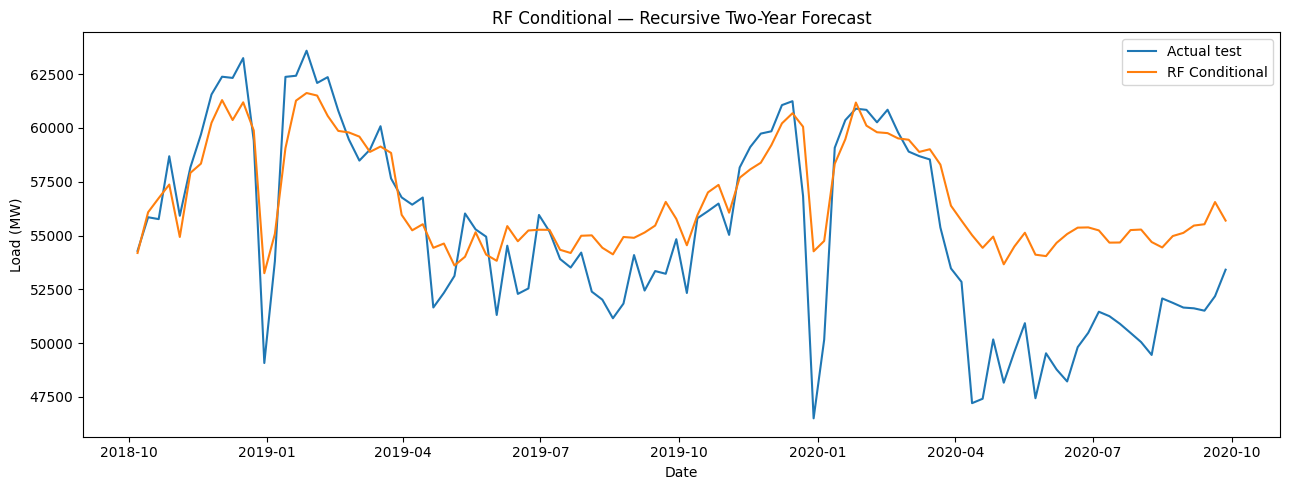

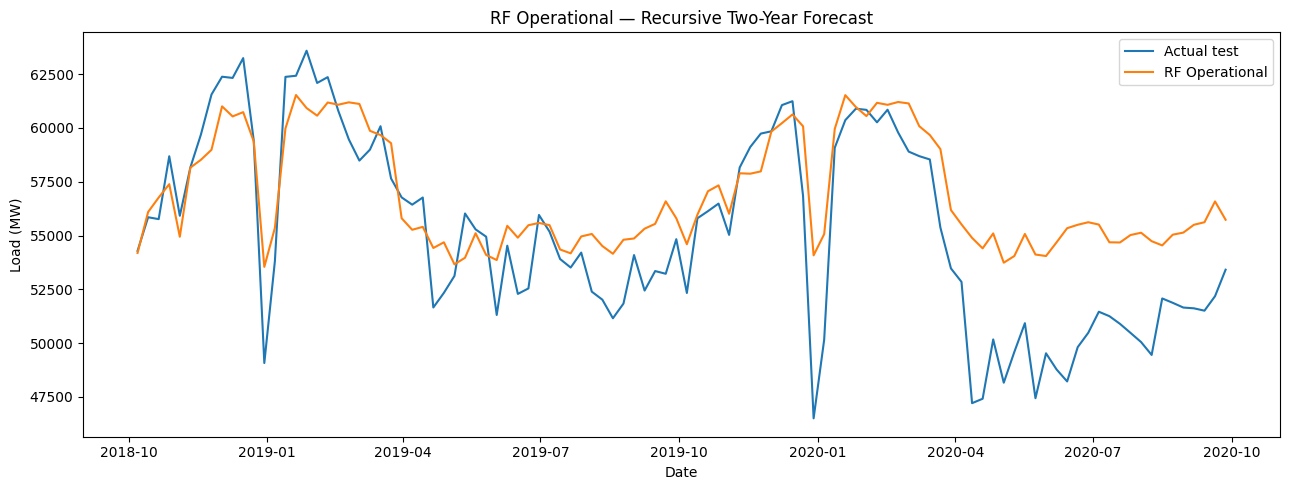

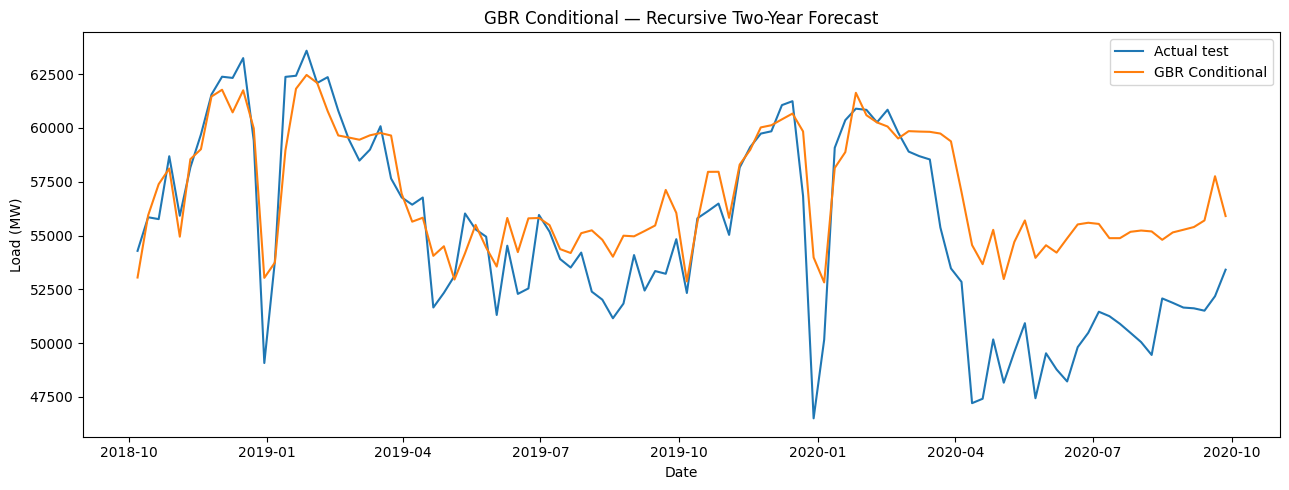

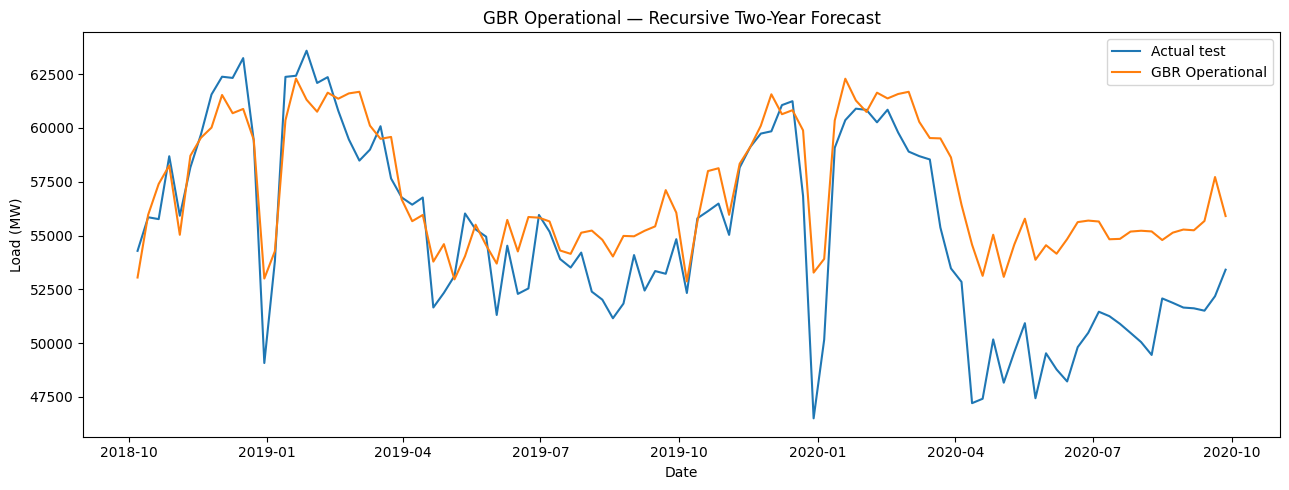

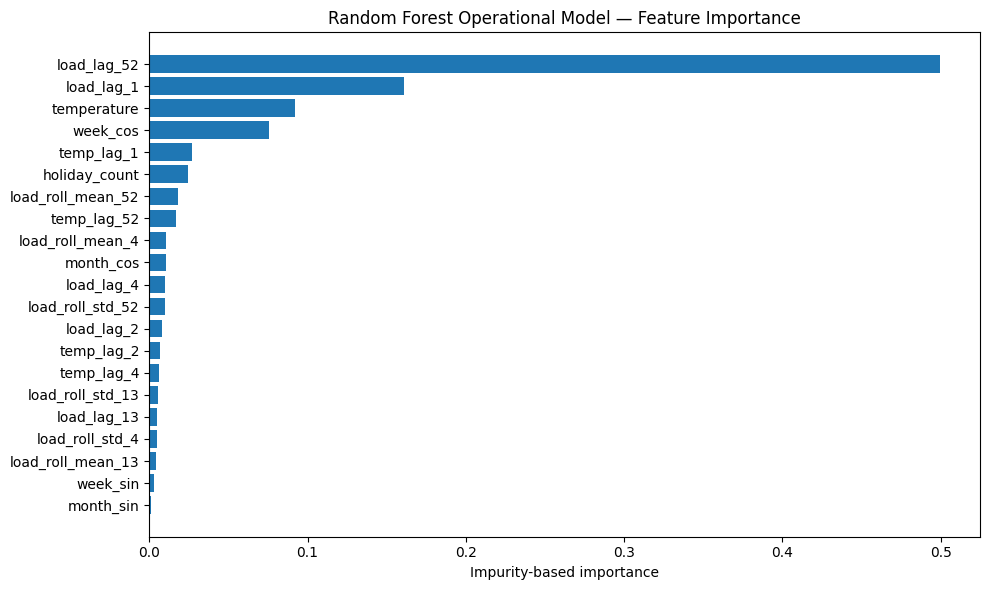

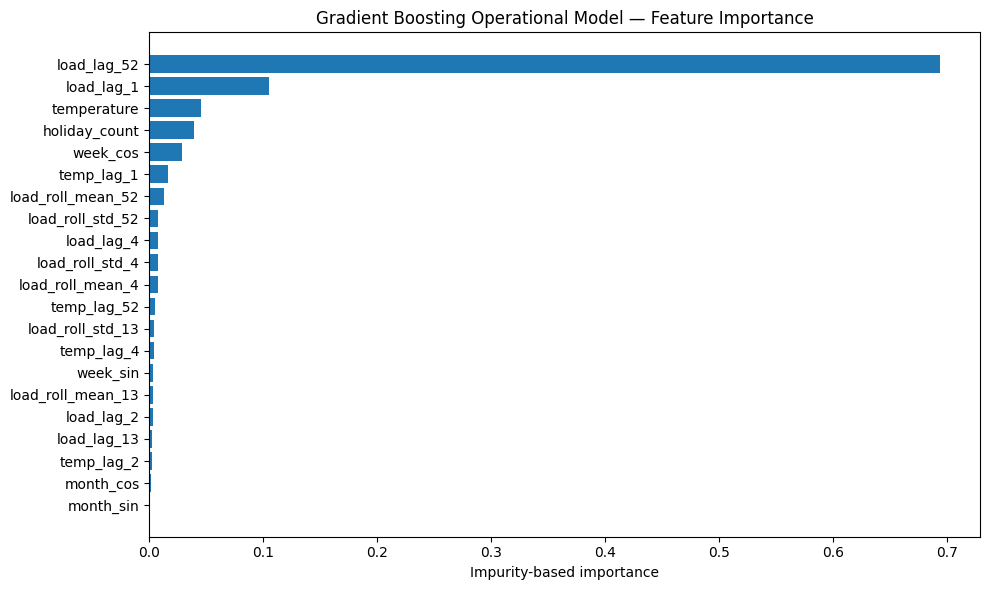

In [35]:
for model_name in feature_model_designs:
    plt.figure(figsize=(13, 5))
    plt.plot(test_weekly.index, test_weekly.values, label="Actual test")
    plt.plot(
        weekly_forecasts[model_name].index,
        weekly_forecasts[model_name].values,
        label=model_name,
    )
    plt.title(f"{model_name} — Recursive Two-Year Forecast")
    plt.xlabel("Date")
    plt.ylabel("Load (MW)")
    plt.legend()
    finish_plot(f"16_{model_name.lower().replace(' ', '_')}.png")

importance_models = {
    "Random Forest": best_feature_models["RF Operational"],
    "Gradient Boosting": best_feature_models["GBR Operational"],
}
for display_name, model in importance_models.items():
    importance = pd.Series(
        model.feature_importances_, index=feature_columns
    ).sort_values()
    plt.figure(figsize=(10, 6))
    plt.barh(importance.index, importance.values)
    plt.title(f"{display_name} Operational Model — Feature Importance")
    plt.xlabel("Impurity-based importance")
    finish_plot(
        f"17_{display_name.lower().replace(' ', '_')}_importance.png"
    )

## Part 6 — Hourly LSTM with chronological tuning and fixed-origin block forecasting

### Part 6 literature context and limits of comparability

The original LSTM architecture was introduced by Hochreiter and Schmidhuber (1997) to learn long-range dependencies using gated memory. For electricity load forecasting, three relevant empirical studies motivate and qualify this experiment:

| Study | Research setting | Relevance / limitation for this assignment |
|---|---|---|
| Kong et al. (2019), *IEEE Transactions on Smart Grid*, [DOI](https://doi.org/10.1109/TSG.2017.2753802) | Short-term load forecasting for individual residential customers | Demonstrates the use of LSTM on volatile smart-meter series; does not establish performance on national demand two years ahead. |
| Lin et al. (2022), *International Journal of Electrical Power & Energy Systems*, [DOI](https://doi.org/10.1016/j.ijepes.2021.107818) | Short-term zonal load forecasting with weather and attention | Shows why time-varying exogenous weather features and prediction uncertainty can matter; the present hourly LSTM uses historical demand only and has no built-in intervals. |
| Yazici, Beyca and Delen (2022), *Engineering Applications of Artificial Intelligence*, [DOI](https://doi.org/10.1016/j.engappai.2021.104645) | Real-world comparison of 1-hour and 24-hour load forecasts with CNN/LSTM/GRU | Illustrates the usual short forecasting horizons in neural-load studies, which must not be compared directly with a 104-week fixed-origin recursion. |

The present two-year evaluation intentionally creates a **different forecasting task**: an LSTM emits one 168-hour block, then repeatedly takes its **own forecast outputs** as inputs with no future observed load. Recursion can accumulate error. The model is compared against both a 168-hour-repeat seasonal naive and a 52-week-repeat annual hourly benchmark. Interpret results as evidence about this implementation and evaluation protocol, not proof that neural networks are inherently inferior for shorter horizons. Select architecture and epochs using *pre-test recursive validation* only.

**Foundational reference:** Hochreiter, S. and Schmidhuber, J. (1997). *Long short-term memory*. Neural Computation, 9(8), 1735–1780. [DOI](https://doi.org/10.1162/neco.1997.9.8.1735).

The LSTM predicts the next 168 hourly values from a historical input window. At test time, predicted 168-hour blocks are recursively appended to history. Consequently, no actual test-period demand enters later input windows. The model is compared with a fixed-origin hourly seasonal-naive forecast that repeats the last observed training week.

An additional hourly **52-week seasonal baseline** is reported because replaying the most recent 168 hours alone captures weekly but not annual seasonality. The LSTM is evaluated against both baselines on the identical test hours. Multiple input windows and architectures are compared; the final model is reinitialized and fitted on all pre-test observations with the epoch count selected solely from pre-test recursive validation.

In [36]:
if RUN_LSTM:
    try:
        import tensorflow as tf
        from tensorflow.keras import Sequential
        from tensorflow.keras.layers import Dense, Dropout, Input, LSTM
        from tensorflow.keras.optimizers import Adam
    except ImportError as exc:
        raise ImportError("TensorFlow is required for Part 6. Install tensorflow and rerun.") from exc

    tf.keras.utils.set_random_seed(RANDOM_SEED)
    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

    LSTM_OUTPUT_HORIZON = 168
    LSTM_TRAIN_STRIDE = 24
    LSTM_MAX_EPOCHS = 30
    LSTM_EARLY_STOPPING_PATIENCE = 5
    LSTM_VALIDATION_FRACTION = 0.15
    LSTM_CANDIDATES = [
        {"input_window": 168, "units_1": 32, "units_2": 0, "dropout": 0.10, "learning_rate": 1e-3, "batch_size": 64},
        {"input_window": 168, "units_1": 64, "units_2": 0, "dropout": 0.10, "learning_rate": 1e-3, "batch_size": 64},
        {"input_window": 336, "units_1": 64, "units_2": 32, "dropout": 0.20, "learning_rate": 1e-3, "batch_size": 64},
        {"input_window": 336, "units_1": 128, "units_2": 64, "dropout": 0.20, "learning_rate": 5e-4, "batch_size": 32},
        {"input_window": 504, "units_1": 64, "units_2": 32, "dropout": 0.30, "learning_rate": 5e-4, "batch_size": 64},
    ]

In [37]:
def make_lstm_blocks(values, input_window, output_horizon, stride):
    X, y = [], []
    last_start = len(values) - output_horizon
    for target_start in range(input_window, last_start + 1, stride):
        X.append(values[target_start - input_window:target_start])
        y.append(values[target_start:target_start + output_horizon])
    X = np.asarray(X, dtype=np.float32)[..., np.newaxis]
    y = np.asarray(y, dtype=np.float32)
    return X, y


def build_lstm_model(config, output_horizon):
    layers = [Input(shape=(config["input_window"], 1))]
    if config["units_2"] > 0:
        layers.extend([
            LSTM(config["units_1"], return_sequences=True),
            Dropout(config["dropout"]),
            LSTM(config["units_2"]),
        ])
    else:
        layers.append(LSTM(config["units_1"]))
    layers.extend([Dropout(config["dropout"]), Dense(output_horizon)])
    model = Sequential(layers)
    model.compile(
        optimizer=Adam(learning_rate=config["learning_rate"]),
        loss="mse",
    )
    return model


def recursive_lstm_block_forecast(
    model, train_scaled, input_window, output_horizon, required_steps
):
    history = list(np.asarray(train_scaled, dtype=np.float32))
    predictions = []
    while len(predictions) < required_steps:
        model_input = np.asarray(
            history[-input_window:], dtype=np.float32
        ).reshape(1, input_window, 1)
        block = model.predict(model_input, verbose=0).reshape(-1)
        needed = min(output_horizon, required_steps - len(predictions))
        predictions.extend(block[:needed].tolist())
        history.extend(block.tolist())
    return np.asarray(predictions[:required_steps], dtype=float)


def inverse_standard_scale(values, scaler):
    values = np.asarray(values, dtype=float)
    return values * scaler.scale_[0] + scaler.mean_[0]

In [38]:
if RUN_LSTM:
    train_hourly_values = train_hourly.to_numpy(dtype=float)
    validation_boundary = int(
        len(train_hourly_values) * (1.0 - LSTM_VALIDATION_FRACTION)
    )
    # Align the validation origin to a complete 168-hour week.
    validation_boundary = (validation_boundary // LSTM_OUTPUT_HORIZON) * LSTM_OUTPUT_HORIZON
    tuning_train_raw = train_hourly_values[:validation_boundary]
    validation_raw = train_hourly_values[validation_boundary:]

    lstm_tuning_records = []
    best_validation_rmse = np.inf
    best_lstm_config = None
    best_lstm_epoch = None
    best_lstm_tuning_history = None

    for candidate_id, config in enumerate(LSTM_CANDIDATES, start=1):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(RANDOM_SEED + candidate_id)

        # The scaler is fitted only on the candidate's tuning-training segment.
        candidate_scaler = StandardScaler()
        tuning_train_scaled = candidate_scaler.fit_transform(
            tuning_train_raw.reshape(-1, 1)
        ).ravel()
        X_train_lstm, y_train_lstm = make_lstm_blocks(
            tuning_train_scaled,
            config["input_window"],
            LSTM_OUTPUT_HORIZON,
            LSTM_TRAIN_STRIDE,
        )

        candidate_model = build_lstm_model(config, LSTM_OUTPUT_HORIZON)
        candidate_best_rmse = np.inf
        candidate_best_epoch = 0
        candidate_best_weights = None
        patience_counter = 0
        training_losses = []
        recursive_validation_scores = []

        # Manual early stopping uses the same recursive fixed-origin protocol
        # that is used to rank candidates and evaluate the final test period.
        for epoch in range(1, LSTM_MAX_EPOCHS + 1):
            epoch_history = candidate_model.fit(
                X_train_lstm,
                y_train_lstm,
                epochs=1,
                batch_size=config["batch_size"],
                shuffle=False,
                verbose=0,
            )
            training_loss = float(epoch_history.history["loss"][-1])
            recursive_validation_scaled = recursive_lstm_block_forecast(
                candidate_model,
                tuning_train_scaled,
                config["input_window"],
                LSTM_OUTPUT_HORIZON,
                len(validation_raw),
            )
            recursive_validation_prediction = inverse_standard_scale(
                recursive_validation_scaled, candidate_scaler
            )
            validation_score = rmse(
                validation_raw, recursive_validation_prediction
            )
            training_losses.append(training_loss)
            recursive_validation_scores.append(validation_score)

            if validation_score < candidate_best_rmse - 1e-6:
                candidate_best_rmse = validation_score
                candidate_best_epoch = epoch
                candidate_best_weights = [
                    weight.copy() for weight in candidate_model.get_weights()
                ]
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= LSTM_EARLY_STOPPING_PATIENCE:
                    break

        if candidate_best_weights is None:
            raise RuntimeError(f"LSTM candidate {candidate_id} did not produce valid weights.")
        candidate_model.set_weights(candidate_best_weights)

        record = {
            "candidate": candidate_id,
            **config,
            "best_epoch": candidate_best_epoch,
            "recursive_validation_RMSE": candidate_best_rmse,
            "epochs_evaluated": len(training_losses),
        }
        lstm_tuning_records.append(record)
        print(record)

        if candidate_best_rmse < best_validation_rmse:
            best_validation_rmse = candidate_best_rmse
            best_lstm_config = config.copy()
            best_lstm_epoch = candidate_best_epoch
            best_lstm_tuning_history = {
                "training_loss": training_losses,
                "recursive_validation_RMSE": recursive_validation_scores,
            }

        del candidate_model, X_train_lstm, y_train_lstm
        gc.collect()

    lstm_tuning_table = pd.DataFrame(lstm_tuning_records).sort_values(
        "recursive_validation_RMSE"
    )
    lstm_tuning_table.to_csv(TABLE_DIR / "lstm_tuning_results.csv", index=False)

    # Refit both the scaler and selected architecture on every pre-test hour.
    hourly_scaler = StandardScaler()
    train_hourly_scaled = hourly_scaler.fit_transform(
        train_hourly_values.reshape(-1, 1)
    ).ravel()
    X_full_lstm, y_full_lstm = make_lstm_blocks(
        train_hourly_scaled,
        best_lstm_config["input_window"],
        LSTM_OUTPUT_HORIZON,
        LSTM_TRAIN_STRIDE,
    )

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_SEED)
    best_lstm_model = build_lstm_model(
        best_lstm_config, LSTM_OUTPUT_HORIZON
    )
    final_history = best_lstm_model.fit(
        X_full_lstm,
        y_full_lstm,
        epochs=max(1, int(best_lstm_epoch)),
        batch_size=best_lstm_config["batch_size"],
        shuffle=False,
        verbose=1,
    )
    final_lstm_history = final_history.history.copy()
    best_lstm_model.save(MODEL_DIR / "lstm_final_retrained.keras")
    # Persist the EXACT fitted, training-only scaler used by the saved LSTM.
    joblib.dump(hourly_scaler, MODEL_DIR / "lstm_standard_scaler.joblib")

    best_lstm_artifact = {
        **best_lstm_config,
        "selected_epoch": int(best_lstm_epoch),
        "recursive_validation_RMSE": float(best_validation_rmse),
        "scaler_fit_end": str(train_hourly.index.max()),
    }
    with open(MODEL_DIR / "best_lstm_config.json", "w", encoding="utf-8") as handle:
        json.dump(best_lstm_artifact, handle, indent=2)

    print("Best LSTM configuration:", best_lstm_artifact)
    print("Final model retrained on all pre-test hourly observations.")

{'candidate': 1, 'input_window': 168, 'units_1': 32, 'units_2': 0, 'dropout': 0.1, 'learning_rate': 0.001, 'batch_size': 64, 'best_epoch': 8, 'recursive_validation_RMSE': 5848.920198106521, 'epochs_evaluated': 13}
{'candidate': 2, 'input_window': 168, 'units_1': 64, 'units_2': 0, 'dropout': 0.1, 'learning_rate': 0.001, 'batch_size': 64, 'best_epoch': 9, 'recursive_validation_RMSE': 6108.328540438071, 'epochs_evaluated': 14}
{'candidate': 3, 'input_window': 336, 'units_1': 64, 'units_2': 32, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 64, 'best_epoch': 11, 'recursive_validation_RMSE': 5258.304533224883, 'epochs_evaluated': 16}
{'candidate': 4, 'input_window': 336, 'units_1': 128, 'units_2': 64, 'dropout': 0.2, 'learning_rate': 0.0005, 'batch_size': 32, 'best_epoch': 2, 'recursive_validation_RMSE': 6215.583895197635, 'epochs_evaluated': 7}
{'candidate': 5, 'input_window': 504, 'units_1': 64, 'units_2': 32, 'dropout': 0.3, 'learning_rate': 0.0005, 'batch_size': 64, 'best_epoch':

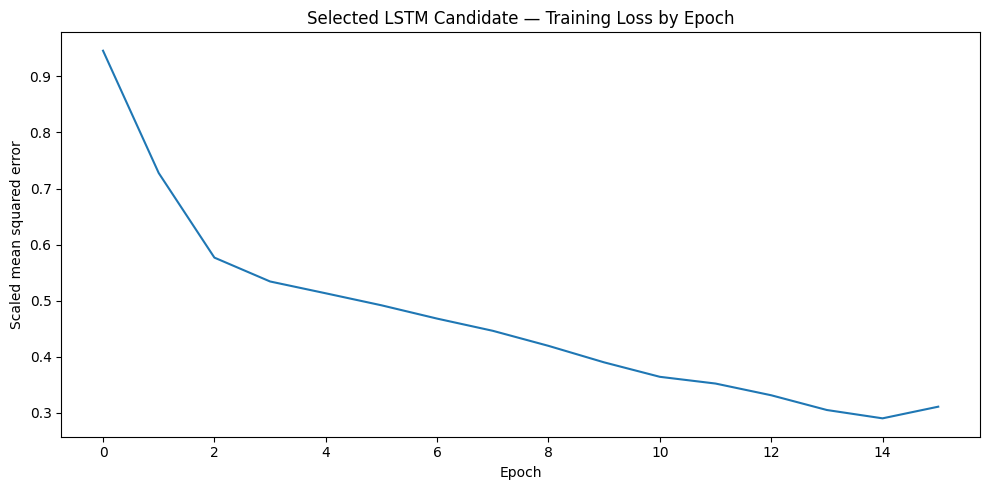

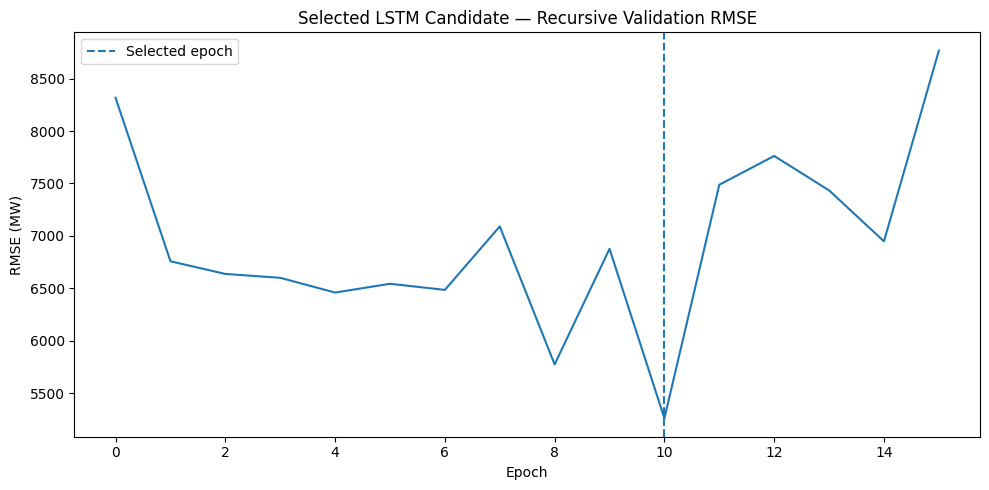

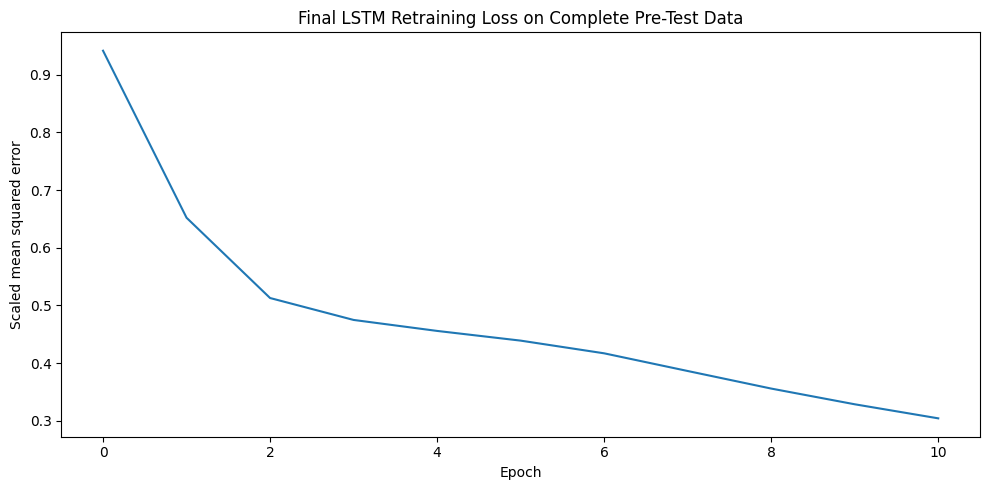

                       Model Frequency                                                                  Protocol     N        RMSE         MAE  sMAPE_pct     MASE  MASE_scaling_hours  MASE_denominator_MW  MASE_annual_scaling_secondary  Improvement_vs_hourly_annual_seasonal_naive_pct
Hourly Annual Seasonal Naive    Hourly                                                  Fixed-origin operational 17544 4502.721534 3073.118331   5.643549 1.334301                 168           2303.16789                       1.442410                                         0.000000
       Hourly Seasonal Naive    Hourly                                                  Fixed-origin operational 17544 5673.711282 4411.524567   8.074608 1.915416                 168           2303.16789                       2.070609                                       -26.006266
           LSTM Fixed-Origin    Hourly Fixed-origin operational; scaler and model refitted on full training data 17544 7601.608632 6113.788400  11.1

In [39]:
if RUN_LSTM:
    plt.figure(figsize=(10, 5))
    plt.plot(best_lstm_tuning_history["training_loss"])
    plt.title("Selected LSTM Candidate — Training Loss by Epoch")
    plt.xlabel("Epoch")
    plt.ylabel("Scaled mean squared error")
    finish_plot("18a_lstm_tuning_training_loss.png")

    plt.figure(figsize=(10, 5))
    plt.plot(best_lstm_tuning_history["recursive_validation_RMSE"])
    plt.axvline(best_lstm_epoch - 1, linestyle="--", label="Selected epoch")
    plt.title("Selected LSTM Candidate — Recursive Validation RMSE")
    plt.xlabel("Epoch")
    plt.ylabel("RMSE (MW)")
    plt.legend()
    finish_plot("18b_lstm_recursive_validation_rmse.png")

    plt.figure(figsize=(10, 5))
    plt.plot(final_lstm_history["loss"])
    plt.title("Final LSTM Retraining Loss on Complete Pre-Test Data")
    plt.xlabel("Epoch")
    plt.ylabel("Scaled mean squared error")
    finish_plot("18c_lstm_final_retraining_loss.png")

    lstm_test_prediction_scaled = recursive_lstm_block_forecast(
        best_lstm_model,
        train_hourly_scaled,
        best_lstm_config["input_window"],
        LSTM_OUTPUT_HORIZON,
        len(test_hourly),
    )
    lstm_test_prediction = inverse_standard_scale(
        lstm_test_prediction_scaled, hourly_scaler
    )
    lstm_hourly_forecast = pd.Series(
        lstm_test_prediction, index=test_hourly.index, name="LSTM fixed-origin"
    )

    hourly_seasonal_naive = pd.Series(
        np.resize(
            train_hourly.iloc[-SEASONAL_PERIOD_HOURLY:].to_numpy(),
            len(test_hourly),
        ),
        index=test_hourly.index,
        name="Hourly seasonal naive",
    )

    # Annual hourly seasonal naive: repeat 52 complete weeks known at origin.
    annual_hours = 52 * 168
    hourly_annual_seasonal_naive = pd.Series(
        np.resize(train_hourly.iloc[-annual_hours:].to_numpy(), len(test_hourly)),
        index=test_hourly.index, name="Hourly annual seasonal naive",
    )
    hourly_metrics = pd.DataFrame([
        metric_record(
            "Hourly Annual Seasonal Naive", test_hourly, hourly_annual_seasonal_naive,
            train_hourly, HOURLY_MASE_SCALING_PERIOD, "Fixed-origin operational", "Hourly"
        ),
        metric_record(
            "Hourly Seasonal Naive", test_hourly, hourly_seasonal_naive,
            train_hourly, HOURLY_MASE_SCALING_PERIOD,
            "Fixed-origin operational", "Hourly"
        ),
        metric_record(
            "LSTM Fixed-Origin", test_hourly, lstm_hourly_forecast,
            train_hourly, HOURLY_MASE_SCALING_PERIOD,
            "Fixed-origin operational; scaler and model refitted on full training data",
            "Hourly"
        ),
    ])
    # Use one common 168-hour training error denominator for all hourly MASE.
    hourly_mase_denominator = float(np.mean(np.abs(
        train_hourly.to_numpy()[HOURLY_MASE_SCALING_PERIOD:] -
        train_hourly.to_numpy()[:-HOURLY_MASE_SCALING_PERIOD]
    )))
    assert hourly_mase_denominator > 0
    hourly_metrics["MASE_scaling_hours"] = HOURLY_MASE_SCALING_PERIOD
    hourly_metrics["MASE_denominator_MW"] = hourly_mase_denominator
    assert np.allclose(hourly_metrics["MASE"], hourly_metrics["MAE"] / hourly_mase_denominator)
    # Secondary scaling sensitivity, also using one denominator for EVERY model.
    annual_denom = float(np.mean(np.abs(
        train_hourly.to_numpy()[annual_hours:] - train_hourly.to_numpy()[:-annual_hours]
    )))
    hourly_metrics["MASE_annual_scaling_secondary"] = hourly_metrics["MAE"] / annual_denom
    annual_baseline_rmse = float(hourly_metrics.loc[
        hourly_metrics["Model"] == "Hourly Annual Seasonal Naive", "RMSE"].iloc[0])
    hourly_metrics["Improvement_vs_hourly_annual_seasonal_naive_pct"] = (
        annual_baseline_rmse - hourly_metrics["RMSE"]
    ) / annual_baseline_rmse * 100.0
    hourly_metrics.to_csv(TABLE_DIR / "hourly_lstm_metrics.csv", index=False)
    print(hourly_metrics.to_string(index=False))

### Independent LSTM and scaler reload verification

The LSTM is not reproducible from weights alone: the scaler fitted to the
pre-test hourly training data is also saved. Reload the `.keras` and `.joblib`
files from disk, verify the scaler's training-only statistics, and reproduce
the first two recursive 168-hour forecast blocks. Small numeric tolerances
accommodate backend-level floating-point differences. Full-horizon predictions
are already tested against the exported metrics in the final verification suite.

In [40]:
# Reload both artifacts from disk; verify without retraining the network.
if RUN_LSTM:
    _lstm_model_file = MODEL_DIR / "lstm_final_retrained.keras"
    _lstm_scaler_file = MODEL_DIR / "lstm_standard_scaler.joblib"
    assert _lstm_model_file.is_file() and _lstm_scaler_file.is_file(), (
        "Missing LSTM model or fitted training-only scaler")
    _loaded_scaler = joblib.load(_lstm_scaler_file)
    _loaded_model = tf.keras.models.load_model(_lstm_model_file, compile=False)
    assert _loaded_scaler.n_samples_seen_ == len(train_hourly)
    np.testing.assert_allclose(_loaded_scaler.mean_, hourly_scaler.mean_, atol=1e-12)
    np.testing.assert_allclose(_loaded_scaler.var_, hourly_scaler.var_, atol=1e-12)
    _loaded_scaled_history = _loaded_scaler.transform(
        train_hourly.to_numpy(dtype=float).reshape(-1, 1)).ravel()
    _check_hours = min(2 * LSTM_OUTPUT_HORIZON, len(test_hourly))
    _reloaded_scaled_forecast = recursive_lstm_block_forecast(
        _loaded_model, _loaded_scaled_history,
        best_lstm_config["input_window"], LSTM_OUTPUT_HORIZON, _check_hours,
    )
    _reloaded_mw = inverse_standard_scale(_reloaded_scaled_forecast, _loaded_scaler)
    _reference_mw = lstm_hourly_forecast.iloc[:_check_hours].to_numpy(dtype=float)
    _max_difference = float(np.max(np.abs(_reloaded_mw - _reference_mw)))
    _passes = bool(np.allclose(_reloaded_mw, _reference_mw, atol=0.10, rtol=1e-6))
    lstm_model_reload_checks = pd.DataFrame([{
        "artifact": _lstm_model_file.name,
        "preprocessing_artifact": _lstm_scaler_file.name,
        "scaler_fitted_hours": int(_loaded_scaler.n_samples_seen_),
        "scaler_training_end": str(train_hourly.index.max()),
        "checked_recursive_hours": int(_check_hours),
        "max_absolute_difference_MW": _max_difference,
        "tolerance_atol_MW": 0.10,
        "tolerance_rtol": 1e-6,
        "passed": _passes,
        "test_target_used_for_retraining": False,
    }])
    lstm_model_reload_checks.to_csv(TABLE_DIR / "lstm_model_reload_checks.csv", index=False)
    assert _passes, f"Reloaded LSTM forecasts differed (max {_max_difference:.6f} MW)"
    print(lstm_model_reload_checks.to_string(index=False))
    del _loaded_model
    gc.collect()

                  artifact      preprocessing_artifact  scaler_fitted_hours scaler_training_end  checked_recursive_hours  max_absolute_difference_MW  tolerance_atol_MW  tolerance_rtol  passed  test_target_used_for_retraining
lstm_final_retrained.keras lstm_standard_scaler.joblib                32856 2018-09-30 23:00:00                      336                         0.0                0.1        0.000001    True                            False


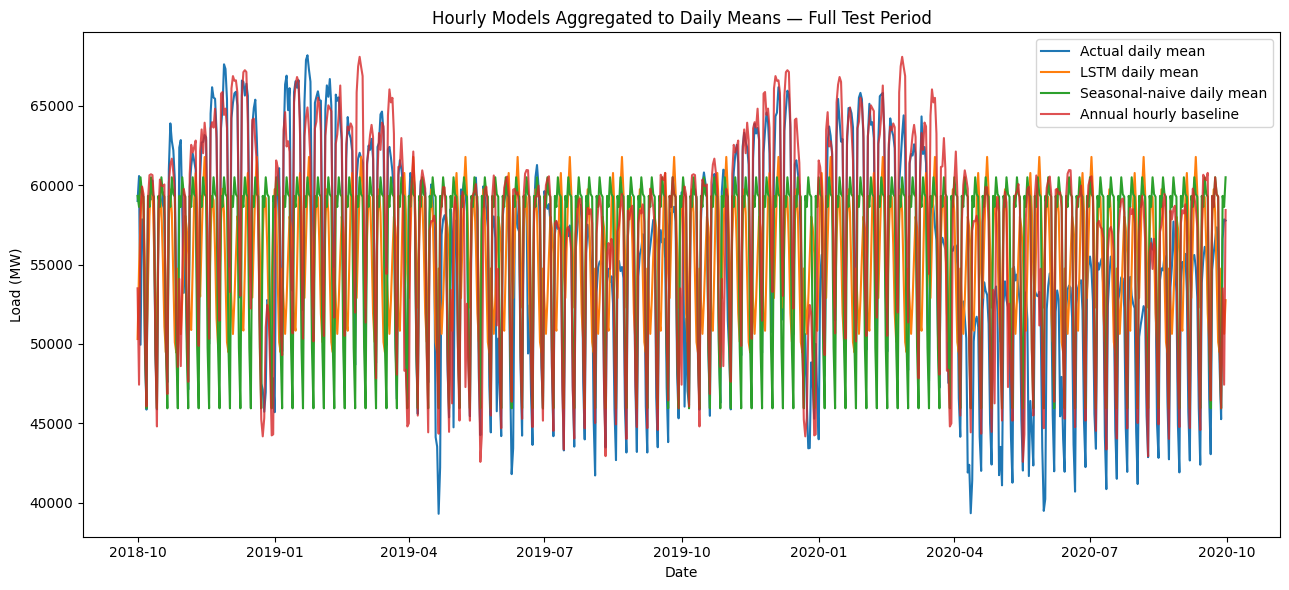

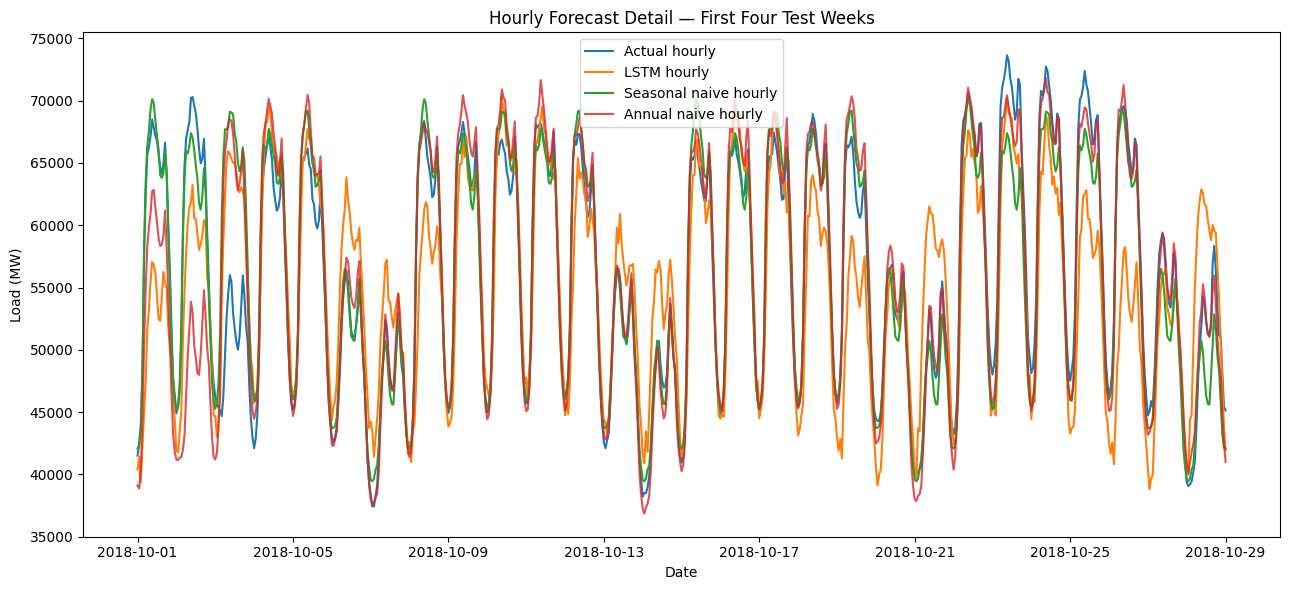

In [41]:
if RUN_LSTM:
    # Full test period shown as daily means for readability.
    actual_daily_test = test_hourly.resample("D").mean()
    lstm_daily_test = lstm_hourly_forecast.resample("D").mean()
    hourly_snaive_daily = hourly_seasonal_naive.resample("D").mean()
    hourly_annual_naive_daily = hourly_annual_seasonal_naive.resample("D").mean()

    plt.figure(figsize=(13, 6))
    plt.plot(actual_daily_test.index, actual_daily_test.values, label="Actual daily mean")
    plt.plot(lstm_daily_test.index, lstm_daily_test.values, label="LSTM daily mean")
    plt.plot(hourly_snaive_daily.index, hourly_snaive_daily.values, label="Seasonal-naive daily mean")
    plt.plot(hourly_annual_naive_daily.index, hourly_annual_naive_daily.values,
             label="Annual hourly baseline", alpha=0.8)
    plt.title("Hourly Models Aggregated to Daily Means — Full Test Period")
    plt.xlabel("Date")
    plt.ylabel("Load (MW)")
    plt.legend()
    finish_plot("19_lstm_full_test_daily_means.png")

    sample_end = test_hourly.index.min() + pd.Timedelta(weeks=4)
    plt.figure(figsize=(13, 6))
    plt.plot(test_hourly.loc[:sample_end].index, test_hourly.loc[:sample_end].values, label="Actual hourly")
    plt.plot(lstm_hourly_forecast.loc[:sample_end].index, lstm_hourly_forecast.loc[:sample_end].values, label="LSTM hourly")
    plt.plot(hourly_seasonal_naive.loc[:sample_end].index, hourly_seasonal_naive.loc[:sample_end].values, label="Seasonal naive hourly")
    plt.plot(hourly_annual_seasonal_naive.loc[:sample_end].index,
             hourly_annual_seasonal_naive.loc[:sample_end].values,
             label="Annual naive hourly", alpha=0.8)
    plt.title("Hourly Forecast Detail — First Four Test Weeks")
    plt.xlabel("Date")
    plt.ylabel("Load (MW)")
    plt.legend()
    finish_plot("20_lstm_first_four_weeks.png")

    # Common-frequency comparison: aggregate LSTM hourly forecasts to weekly means.
    lstm_weekly_forecast = lstm_hourly_forecast.resample(WEEK_FREQ).mean().reindex(
        test_weekly.index
    )
    if lstm_weekly_forecast.isna().any():
        raise ValueError("Weekly LSTM aggregation does not fully cover the common test index.")
    weekly_forecasts["LSTM Weekly Aggregate"] = lstm_weekly_forecast
    forecast_metadata["LSTM Weekly Aggregate"] = (
        "Fixed-origin operational; hourly 168-step block forecast aggregated weekly",
        "Weekly",
    )

### LSTM seed stability (three independent initializations)

The reported principal LSTM remains the original selected architecture and seed. If enabled, two extra models with **the same pre-test-selected hyperparameters and training epochs** are fitted with different random seeds. Their test-set metrics are used only to assess sensitivity to initialization, not to choose or replace the final model. This adds training time; set `RUN_LSTM_SEED_STABILITY=False` if compute limits prevent it and disclose the omission.


In [42]:
if RUN_LSTM:
    seed_results = [{
        "seed": RANDOM_SEED,
        "RMSE_MW": rmse(test_hourly, lstm_hourly_forecast),
        "MAE_MW": float(mean_absolute_error(test_hourly, lstm_hourly_forecast)),
        "role": "Primary pre-selected configuration / fixed seed",
    }]
    if RUN_LSTM_SEED_STABILITY:
        for stability_seed in LSTM_STABILITY_EXTRA_SEEDS:
            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(int(stability_seed))
            alternate_lstm = build_lstm_model(best_lstm_config, LSTM_OUTPUT_HORIZON)
            alternate_lstm.fit(
                X_full_lstm, y_full_lstm,
                epochs=max(1, int(best_lstm_epoch)),
                batch_size=best_lstm_config["batch_size"],
                shuffle=False, verbose=0,
            )
            alternate_scaled = recursive_lstm_block_forecast(
                alternate_lstm, train_hourly_scaled,
                best_lstm_config["input_window"], LSTM_OUTPUT_HORIZON,
                len(test_hourly),
            )
            alternate_forecast = inverse_standard_scale(alternate_scaled, hourly_scaler)
            assert len(alternate_forecast) == len(test_hourly)
            assert np.isfinite(alternate_forecast).all()
            seed_results.append({
                "seed": int(stability_seed),
                "RMSE_MW": rmse(test_hourly, alternate_forecast),
                "MAE_MW": float(mean_absolute_error(test_hourly, alternate_forecast)),
                "role": "Additional seed; analysis only (not selected by test errors)",
            })
            del alternate_lstm, alternate_scaled, alternate_forecast
            tf.keras.backend.clear_session()
            gc.collect()
    else:
        print("Extra seed stability fitting not run; report this limitation.")

    lstm_seed_stability = pd.DataFrame(seed_results)
    lstm_seed_stability.to_csv(TABLE_DIR / "lstm_seed_stability.csv", index=False)
    print(lstm_seed_stability.to_string(index=False))
    if len(lstm_seed_stability) > 1:
        print("Seed RMSE mean / sample SD:",
              lstm_seed_stability["RMSE_MW"].mean(),
              lstm_seed_stability["RMSE_MW"].std(ddof=1))


 seed     RMSE_MW      MAE_MW                                                         role
   42 7601.608632 6113.788400              Primary pre-selected configuration / fixed seed
   43 9345.748136 7531.839202 Additional seed; analysis only (not selected by test errors)
   44 8345.287178 6624.815665 Additional seed; analysis only (not selected by test errors)
Seed RMSE mean / sample SD: 8430.881315328208 875.214499220867


## Part 7 — Fair model comparison and required analytical evidence

In [43]:
weekly_metric_records = []
for model_name, forecast in weekly_forecasts.items():
    protocol, frequency = forecast_metadata[model_name]
    weekly_metric_records.append(
        metric_record(
            model_name,
            test_weekly,
            forecast,
            train_weekly,
            SEASONAL_PERIOD_WEEKLY,
            protocol,
            frequency,
        )
    )

weekly_metrics = pd.DataFrame(weekly_metric_records)
baseline_rmse = float(
    weekly_metrics.loc[weekly_metrics["Model"] == "Seasonal Naive", "RMSE"].iloc[0]
)
weekly_metrics["Improvement_vs_seasonal_naive_pct"] = (
    baseline_rmse - weekly_metrics["RMSE"]
) / baseline_rmse * 100.0
weekly_metrics = weekly_metrics.sort_values("RMSE").reset_index(drop=True)
weekly_metrics.to_csv(TABLE_DIR / "all_weekly_model_metrics.csv", index=False)

print(weekly_metrics.to_string(index=False))

                                  Model Frequency                                                                   Protocol   N        RMSE         MAE  sMAPE_pct     MASE  Improvement_vs_seasonal_naive_pct
                         RF Conditional    Weekly                      Fixed-origin conditional: observed future temperature 104 2939.486788 2242.276903   4.162438 1.659638                           1.631777
                         Seasonal Naive    Weekly                                                   Fixed-origin operational 104 2988.248349 2288.489240   4.206690 1.693843                           0.000000
                        GBR Conditional    Weekly                      Fixed-origin conditional: observed future temperature 104 2989.881447 2229.530224   4.138913 1.650204                          -0.054651
                        GBR Operational    Weekly            Fixed-origin operational: training-only temperature climatology 104 2998.363428 2325.844151   4.294116 1.72

### Accuracy and complexity audit across model families

All weekly scores below use an identical horizon and denominator. Conditional models are never ranked as deployable without a weather forecast available at the origin. The complexity table is an explicit qualitative comparison, not a measured computational benchmark.

In [44]:
# A small operational-versus-conditional summary for an auditable report comparison.
_operational_models = weekly_metrics.loc[
    weekly_metrics["Protocol"].str.contains("operational", case=False, na=False)
].copy()
_conditional_models = weekly_metrics.loc[
    weekly_metrics["Protocol"].str.contains("conditional", case=False, na=False)
].copy()
assert "RF Conditional" not in set(_operational_models["Model"])
assert "Seasonal Naive" in set(_operational_models["Model"])
comparison_by_availability = pd.concat([
    _operational_models.assign(Availability="Origin-available"),
    _conditional_models.assign(Availability="Observed future weather, conditional"),
], ignore_index=True)
comparison_by_availability.to_csv(TABLE_DIR / "model_comparison_by_availability.csv", index=False)
print("Best origin-available weekly forecast:")
print(_operational_models.nsmallest(5, "RMSE")[
    ["Model", "RMSE", "MAE", "sMAPE_pct", "MASE", "Improvement_vs_seasonal_naive_pct"]
].to_string(index=False))

model_tradeoffs = pd.DataFrame([
    {"Family": "Seasonal naive", "Forecast_type": "Operational", "Coefficients_or_features": "Annual persistence",
     "Interpretability": "Direct", "Uncertainty": "No intrinsic calibrated interval", "Maintenance": "Low"},
    {"Family": "SARIMA", "Forecast_type": "Operational", "Coefficients_or_features": "AR/MA and seasonal orders",
     "Interpretability": "Coefficients and residual diagnostics", "Uncertainty": "Parametric interval; verify coverage", "Maintenance": "Moderate"},
    {"Family": "SARIMAX", "Forecast_type": "Operational or conditional", "Coefficients_or_features": "SARIMA with holidays/weather",
     "Interpretability": "Model coefficients, conditional effects", "Uncertainty": "Parametric interval; verify coverage", "Maintenance": "Moderate/high"},
    {"Family": "Tree ensemble", "Forecast_type": "Operational or conditional", "Coefficients_or_features": "Recursive lagged/calendar/weather features",
     "Interpretability": "Feature attribution, not causal", "Uncertainty": "No intrinsic interval", "Maintenance": "Moderate/high"},
    {"Family": "LSTM", "Forecast_type": "Operational", "Coefficients_or_features": "Hourly historical load window",
     "Interpretability": "Low without additional explanation", "Uncertainty": "No calibrated interval", "Maintenance": "High"},
])
model_tradeoffs.to_csv(TABLE_DIR / "forecast_model_tradeoffs.csv", index=False)
print(model_tradeoffs.to_string(index=False))

Best origin-available weekly forecast:
           Model        RMSE         MAE  sMAPE_pct     MASE  Improvement_vs_seasonal_naive_pct
  Seasonal Naive 2988.248349 2288.489240   4.206690 1.693843                           0.000000
 GBR Operational 2998.363428 2325.844151   4.294116 1.721491                          -0.338495
  RF Operational 3003.576426 2342.450517   4.331341 1.733783                          -0.512945
SARIMAX Holidays 3808.919996 3067.109370   5.545280 2.270144                         -27.463301
          SARIMA 3890.555460 3116.197315   5.640106 2.306477                         -30.195185
        Family              Forecast_type                   Coefficients_or_features                        Interpretability                          Uncertainty   Maintenance
Seasonal naive                Operational                         Annual persistence                                  Direct     No intrinsic calibrated interval           Low
        SARIMA                Ope

### Auditable timestamp-aligned prediction exports

Export **all** weekly predictions (including conditional temperature experiments) on exactly the same 104-week test index. The hourly file contains the original LSTM and both hourly baselines. These files permit independent reconstruction of each reported error metric; future observed temperature is never relabelled as an operational input.


In [45]:
# Exports are created after every forecast is available; no retraining is required.
weekly_prediction_table = pd.DataFrame(index=test_weekly.index)
weekly_prediction_table.index.name = "week_end_utc"
weekly_prediction_table["actual_MW"] = test_weekly.to_numpy(dtype=float)
weekly_protocol_records = []
for name, forecast in weekly_forecasts.items():
    if not forecast.index.equals(test_weekly.index):
        raise ValueError(f"{name}: prediction index is not the common test index")
    if not np.isfinite(forecast.to_numpy()).all():
        raise ValueError(f"{name}: non-finite forecast")
    # The exact metric Model name is preserved as the CSV column identifier.
    weekly_prediction_table[name] = forecast.to_numpy(dtype=float)
    protocol, frequency = forecast_metadata[name]
    weekly_protocol_records.append({
        "Model": name, "Prediction CSV column": name,
        "Protocol": protocol, "Frequency": frequency,
        "Forecast origin": str(forecast_start),
        "Uses observed future temperature": "conditional" in protocol.lower(),
    })
weekly_prediction_table.to_csv(TABLE_DIR / "weekly_predictions_vs_actual.csv")
pd.DataFrame(weekly_protocol_records).to_csv(
    TABLE_DIR / "weekly_prediction_protocols.csv", index=False
)

if RUN_LSTM:
    hourly_prediction_table = pd.DataFrame({
        "actual_MW": test_hourly.to_numpy(dtype=float),
        "LSTM Fixed-Origin": lstm_hourly_forecast.to_numpy(dtype=float),
        "Hourly Seasonal Naive": hourly_seasonal_naive.to_numpy(dtype=float),
        "Hourly Annual Seasonal Naive": hourly_annual_seasonal_naive.to_numpy(dtype=float),
    }, index=test_hourly.index)
    hourly_prediction_table.index.name = "timestamp_utc"
    hourly_prediction_table.to_csv(TABLE_DIR / "hourly_predictions_vs_actual.csv")
    print(f"Exported {len(hourly_prediction_table):,} hourly prediction rows")

print(f"Exported {len(weekly_prediction_table):,} weekly prediction rows ",
      f"for {len(weekly_forecasts)} models")


Exported 17,544 hourly prediction rows
Exported 104 weekly prediction rows  for 15 models


### Supplementary robustness, uncertainty and scenario diagnostics

These analyses inspect the **held-out** errors after all models have been selected. They are not tuning criteria. The moving-block-bootstrap intervals measure variability of the paired forecast-error comparison conditional on this historical test window, not predictive intervals for electricity demand. A model outperforming a benchmark on a single origin need not outperform it at other origins.

In [46]:
# Horizon breakdown (13/26/52/104 weeks) to expose long recursive drift.
HORIZON_BANDS = [(1, 13), (14, 26), (27, 52), (53, len(test_weekly))]
horizon_records = []
for name, forecast in weekly_forecasts.items():
    for first, last in HORIZON_BANDS:
        if first > last:
            continue
        obs = test_weekly.iloc[first-1:last]
        pred = forecast.iloc[first-1:last]
        horizon_records.append({"Model": name, "Horizon": f"weeks_{first}_{last}",
                                "N": len(obs), "RMSE": rmse(obs, pred),
                                "MAE": float(mean_absolute_error(obs, pred))})
horizon_scores = pd.DataFrame(horizon_records)
horizon_scores.to_csv(TABLE_DIR / "weekly_horizon_errors.csv", index=False)
print(horizon_scores.loc[horizon_scores["Model"].isin([
    "Seasonal Naive", "SARIMA", "RF Operational", "RF Conditional"
])].to_string(index=False))

# Circular moving block bootstrap for paired model-vs-benchmark RMSE difference.
# Positive benefit means lower RMSE than the seasonal-naive model.
def paired_rmse_block_bootstrap(actual, baseline, challenger,
                                block_length=8, draws=1000, random_seed=42):
    actual, baseline, challenger = map(
        lambda x: np.asarray(x, dtype=float), (actual, baseline, challenger))
    if not (len(actual) == len(baseline) == len(challenger)):
        raise ValueError("Identical test lengths required")
    n = len(actual)
    if n < block_length * 2:
        raise ValueError("Test set too short for block length")
    generator = np.random.default_rng(random_seed)
    original = rmse(actual, baseline) - rmse(actual, challenger)
    benefits = np.empty(draws)
    for i in range(draws):
        starts = generator.integers(0, n, size=math.ceil(n / block_length))
        selected = np.concatenate([(s + np.arange(block_length)) % n
                                   for s in starts])[:n]
        benefits[i] = (rmse(actual[selected], baseline[selected])
                       - rmse(actual[selected], challenger[selected]))
    low, high = np.quantile(benefits, [0.025, 0.975])
    return float(original), float(low), float(high)

baseline = weekly_forecasts["Seasonal Naive"]
bootstrap_rows = []
for model_name, forecast in weekly_forecasts.items():
    if model_name == "Seasonal Naive":
        continue
    benefit, low, high = paired_rmse_block_bootstrap(
        test_weekly, baseline, forecast, random_seed=RANDOM_SEED)
    bootstrap_rows.append({"Model": model_name, "RMSE_gain_MW": benefit,
                           "block_bootstrap_lower_95pct": low,
                           "block_bootstrap_upper_95pct": high,
                           "block_weeks": 8, "draws": 1000})
bootstrap_comparison = pd.DataFrame(bootstrap_rows)
bootstrap_comparison.to_csv(TABLE_DIR / "weekly_rmse_block_bootstrap.csv", index=False)
print(bootstrap_comparison.to_string(index=False))

# Calendar covariates are known at the origin; observed test weather is not.
scenario_metadata = pd.DataFrame([
    {"Forecast type": "Operational", "Covariate": "Future holiday dates",
     "Known at origin": True, "Source": "Prepublished Germany calendar"},
    {"Forecast type": "Operational", "Covariate": "Future Berlin temperature",
     "Known at origin": False, "Source": "Training-only week climatology PROXY"},
    {"Forecast type": "Conditional", "Covariate": "Observed test temperature",
     "Known at origin": False, "Source": "Explanatory hindsight scenario"},
])
scenario_metadata.to_csv(TABLE_DIR / "forecast_covariate_availability.csv", index=False)
print(scenario_metadata.to_string(index=False))


         Model      Horizon  N        RMSE         MAE
Seasonal Naive   weeks_1_13 13 1004.961999  881.419414
Seasonal Naive  weeks_14_26 13 2147.173718 1653.113095
Seasonal Naive  weeks_27_52 26 2140.221843 1785.778846
Seasonal Naive weeks_53_104 52 3763.496476 3050.455929
        SARIMA   weeks_1_13 13 1046.290372  826.139879
        SARIMA  weeks_14_26 13 2330.401680 1747.554017
        SARIMA  weeks_27_52 26 2617.950420 2242.103900
        SARIMA weeks_53_104 52 5021.417876 4467.919207
RF Conditional   weeks_1_13 13 1622.813747 1252.169325
RF Conditional  weeks_14_26 13 1429.783911 1193.225637
RF Conditional  weeks_27_52 26 1946.286390 1660.167271
RF Conditional weeks_53_104 52 3770.636309 3043.121430
RF Operational   weeks_1_13 13 1819.965920 1350.415635
RF Operational  weeks_14_26 13 1623.591920 1440.776901
RF Operational  weeks_27_52 26 1990.600446 1697.361858
RF Operational weeks_53_104 52 3817.671537 3138.421971
                                  Model  RMSE_gain_MW  block_boot

### Prediction-interval reliability and interval score

Evaluate SARIMA and all five SARIMAX nominal 95% intervals over the full test window **and separately by forecast horizon**. An interval score penalizes excessively broad intervals and misses. These are held-out evaluation diagnostics **only**: do not tune, shrink or calibrate forecast intervals using these test observations.


In [47]:
def interval_diagnostic_rows(actual, lower, upper, name, alpha=0.05):
    # Evaluation only; all arrays must use a matching chronological index.
    for interval_series in (lower, upper):
        if not actual.index.equals(interval_series.index):
            raise ValueError(f"{name}: interval timestamps do not align")
    y = actual.to_numpy(dtype=float)
    lo, hi = lower.to_numpy(dtype=float), upper.to_numpy(dtype=float)
    if not (np.isfinite(y).all() and np.isfinite(lo).all() and np.isfinite(hi).all()):
        raise ValueError(f"{name}: non-finite interval values")
    if np.any(lo > hi):
        raise ValueError(f"{name}: lower interval bound exceeds upper")
    results = []
    for first, last in [(1, len(y))] + HORIZON_BANDS:
        if first > last:
            continue
        a, b, c = y[first-1:last], lo[first-1:last], hi[first-1:last]
        coverage = np.mean((a >= b) & (a <= c))
        widths = c - b
        score = widths + (2/alpha)*(b-a)* (a<b) + (2/alpha)*(a-c)*(a>c)
        results.append({
            "Model": name, "Horizon": f"weeks_{first}_{last}",
            "N": len(a), "Nominal_coverage": 1-alpha,
            "Empirical_coverage": float(coverage),
            "Coverage_gap_percentage_points": 100*float(coverage - (1-alpha)),
            "Mean_interval_width_MW": float(np.mean(widths)),
            "Mean_interval_score_MW": float(np.mean(score)),
            "Test_used_for_calibration": False,
        })
    return results

interval_rows = interval_diagnostic_rows(
    test_weekly, sarima_confidence.iloc[:,0], sarima_confidence.iloc[:,1], "SARIMA")
for model_name, ci in sarimax_confidence_intervals.items():
    interval_rows.extend(interval_diagnostic_rows(
        test_weekly, ci.iloc[:,0], ci.iloc[:,1], model_name))
interval_analysis = pd.DataFrame(interval_rows)
interval_analysis.to_csv(TABLE_DIR / "prediction_interval_diagnostics.csv", index=False)
print(interval_analysis[interval_analysis["Horizon"] == f"weeks_1_{len(test_weekly)}"].to_string(index=False))


                                  Model     Horizon   N  Nominal_coverage  Empirical_coverage  Coverage_gap_percentage_points  Mean_interval_width_MW  Mean_interval_score_MW  Test_used_for_calibration
                                 SARIMA weeks_1_104 104              0.95            0.701923                      -24.807692             7982.377104            28112.629622                      False
                       SARIMAX Holidays weeks_1_104 104              0.95            0.653846                      -29.615385             6895.761409            33030.168083                      False
        SARIMAX Temperature Conditional weeks_1_104 104              0.95            0.663462                      -28.653846             7721.853270            31168.231252                      False
       SARIMAX Temp+Holiday Conditional weeks_1_104 104              0.95            0.615385                      -33.461538             6367.041173            38990.296218                      F

### Fixed-origin error analysis across 2020

A forecast made in 2018 cannot anticipate all future structural shifts. Compare errors before and after 1 March 2020 **descriptively**; the split date is used only after models have been frozen, never to tune or select them. The analysis does not identify a causal explanation for the shift.


                Model            Period  N        RMSE         MAE  Mean_signed_error_MW  Selection_uses_this_split
       Seasonal Naive Before 2020-03-01 73 1823.986347 1444.056670            673.766226                      False
       Seasonal Naive 2020-03-01 onward 31 4703.518656 4276.991743           4276.991743                      False
               SARIMA Before 2020-03-01 73 2432.278027 2000.384319           1657.011141                      False
               SARIMA 2020-03-01 onward 31 6070.344595 5743.756952           5743.756952                      False
       RF Operational Before 2020-03-01 73 1995.932811 1520.494064            619.703063                      False
       RF Operational 2020-03-01 onward 31 4569.955995 4278.025392           4278.025392                      False
LSTM Weekly Aggregate Before 2020-03-01 73 4065.534243 3399.751088          -1233.772438                      False
LSTM Weekly Aggregate 2020-03-01 onward 31 5173.250477 4784.318879      

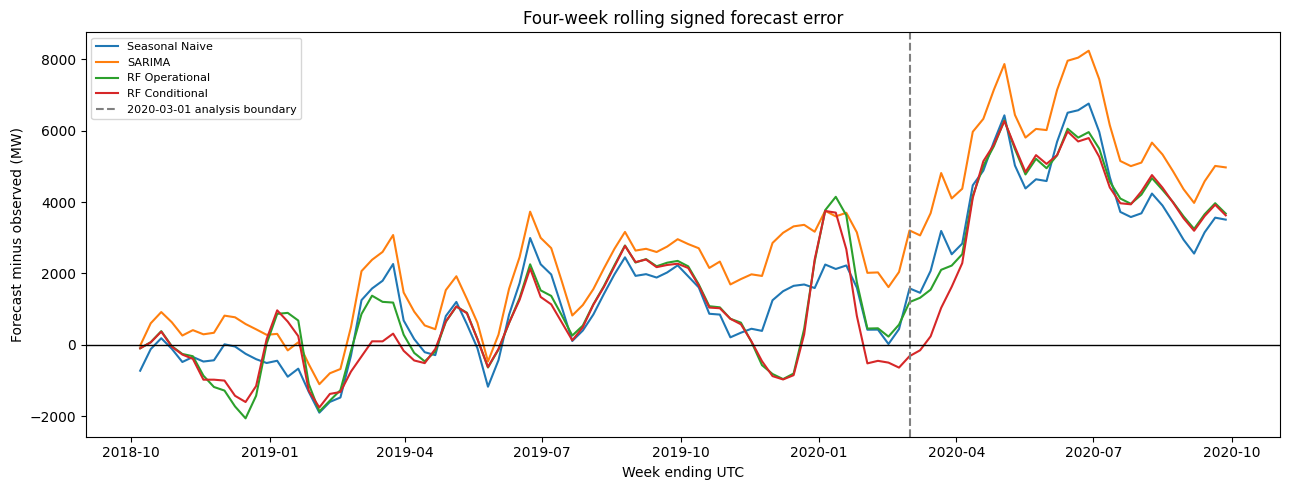

In [48]:
_period_cut = pd.Timestamp("2020-03-01")
period_records = []
for model_name, forecast in weekly_forecasts.items():
    for period_label, mask in [
        ("Before 2020-03-01", test_weekly.index < _period_cut),
        ("2020-03-01 onward", test_weekly.index >= _period_cut),
    ]:
        actual_part = test_weekly.loc[mask]
        forecast_part = forecast.loc[mask]
        if len(actual_part):
            period_records.append({
                "Model": model_name, "Period": period_label,
                "N": len(actual_part), "RMSE": rmse(actual_part, forecast_part),
                "MAE": float(mean_absolute_error(actual_part, forecast_part)),
                "Mean_signed_error_MW": float((forecast_part - actual_part).mean()),
                "Selection_uses_this_split": False,
            })
structural_period_errors = pd.DataFrame(period_records)
structural_period_errors.to_csv(TABLE_DIR / "pre_post_2020_period_errors.csv", index=False)
print(structural_period_errors[structural_period_errors["Model"].isin(
    ["Seasonal Naive", "SARIMA", "RF Operational", "LSTM Weekly Aggregate"]
)].to_string(index=False))

# A post-selection check of how sensitive the small RMSE gains are to block size.
block_sensitivity_records = []
for candidate_name in ["RF Conditional", "GBR Conditional", "RF Operational", "GBR Operational", "SARIMA"]:
    if candidate_name not in weekly_forecasts: continue
    for block_weeks in [4, 8, 13]:
        gain, low, high = paired_rmse_block_bootstrap(
            test_weekly, weekly_forecasts["Seasonal Naive"],
            weekly_forecasts[candidate_name],
            block_length=block_weeks, draws=500, random_seed=RANDOM_SEED,
        )
        block_sensitivity_records.append({
            "Model": candidate_name, "Block_weeks": block_weeks,
            "Gain_RMSE_MW": gain, "Lower_95pct": low, "Upper_95pct": high,
            "Evaluation_only": True,
        })
bootstrap_block_sensitivity = pd.DataFrame(block_sensitivity_records)
bootstrap_block_sensitivity.to_csv(TABLE_DIR / "bootstrap_block_length_sensitivity.csv", index=False)

fig, ax = plt.subplots(figsize=(13, 5))
for model_name in ["Seasonal Naive", "SARIMA", "RF Operational", "RF Conditional"]:
    if model_name not in weekly_forecasts: continue
    error = weekly_forecasts[model_name] - test_weekly
    ax.plot(error.index, error.rolling(4, min_periods=1).mean(), label=model_name)
ax.axvline(_period_cut, linestyle="--", color="gray", label="2020-03-01 analysis boundary")
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Four-week rolling signed forecast error", xlabel="Week ending UTC", ylabel="Forecast minus observed (MW)")
ax.legend(fontsize=8)
finish_plot("24_structural_shift_forecast_errors.png")


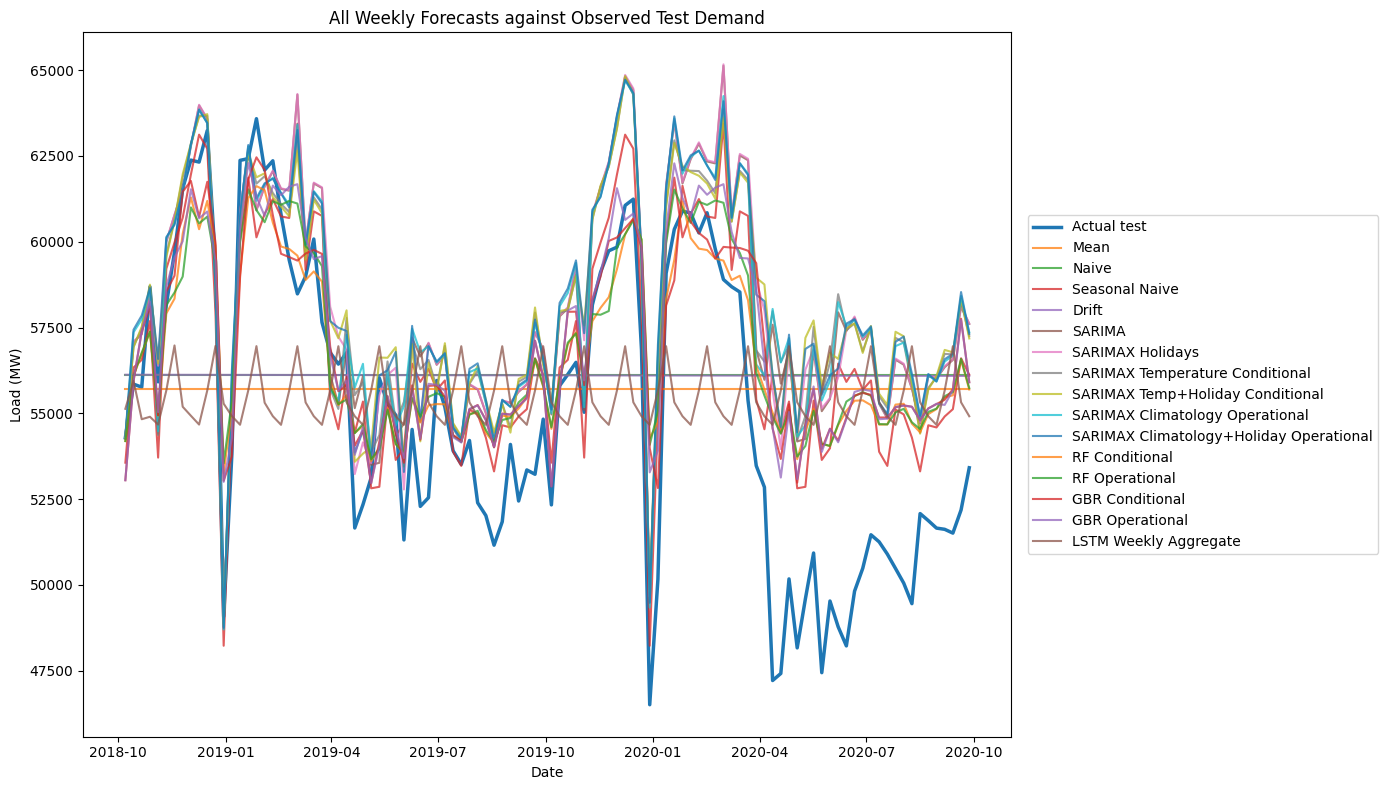

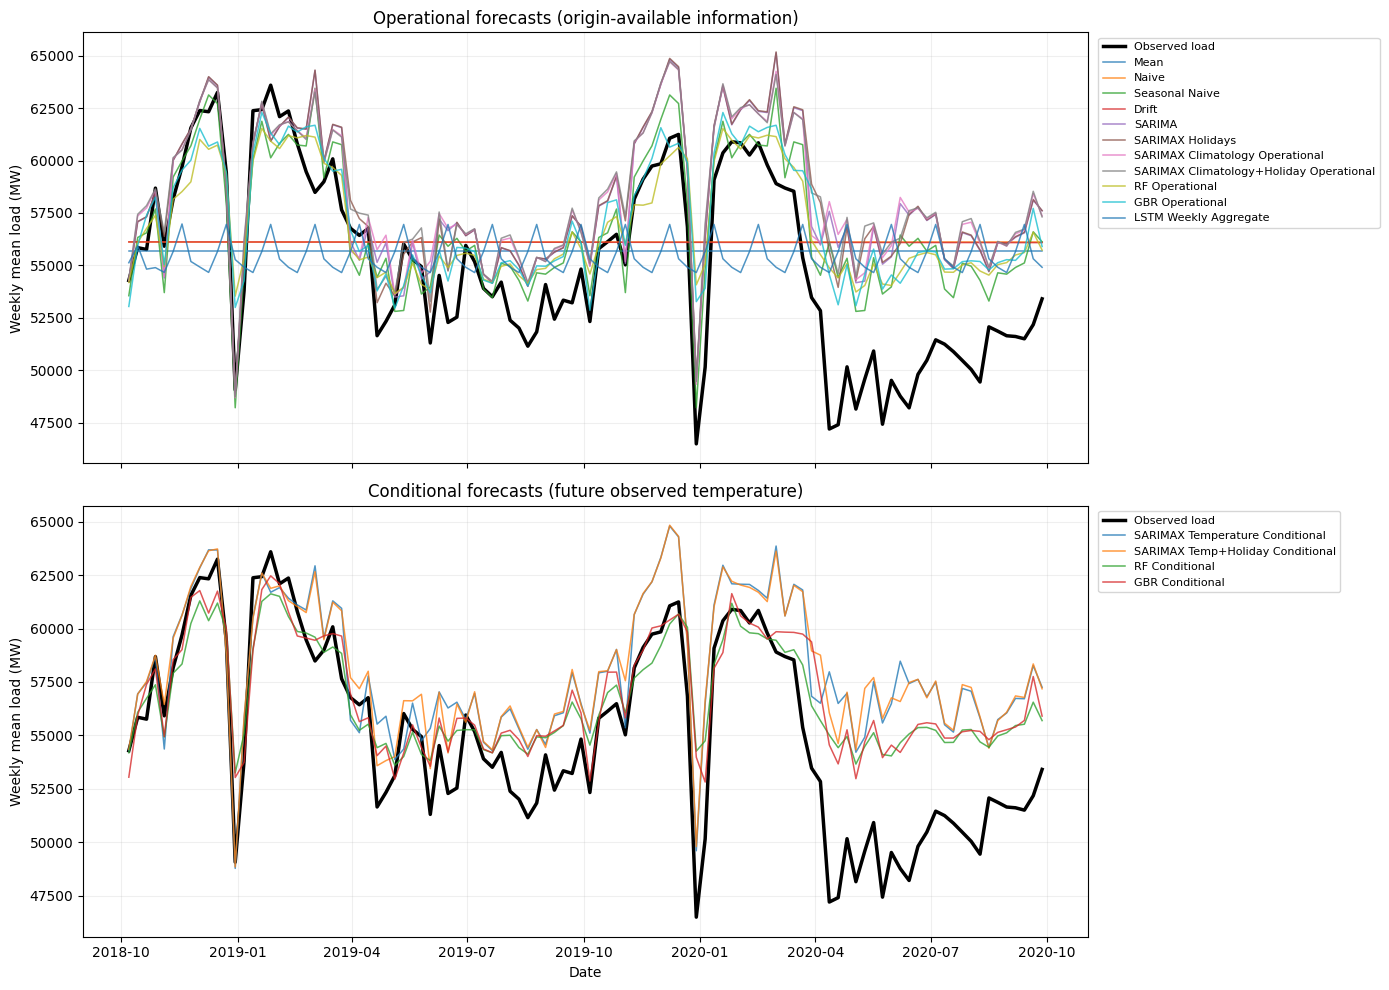

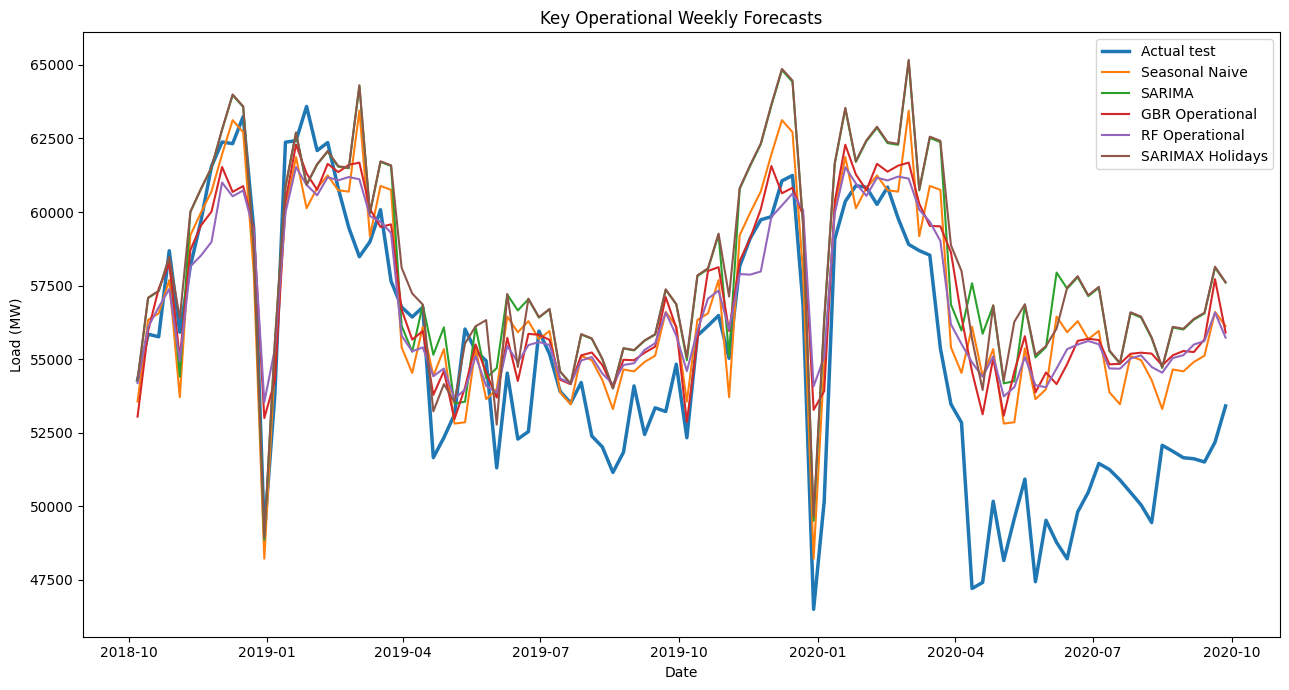

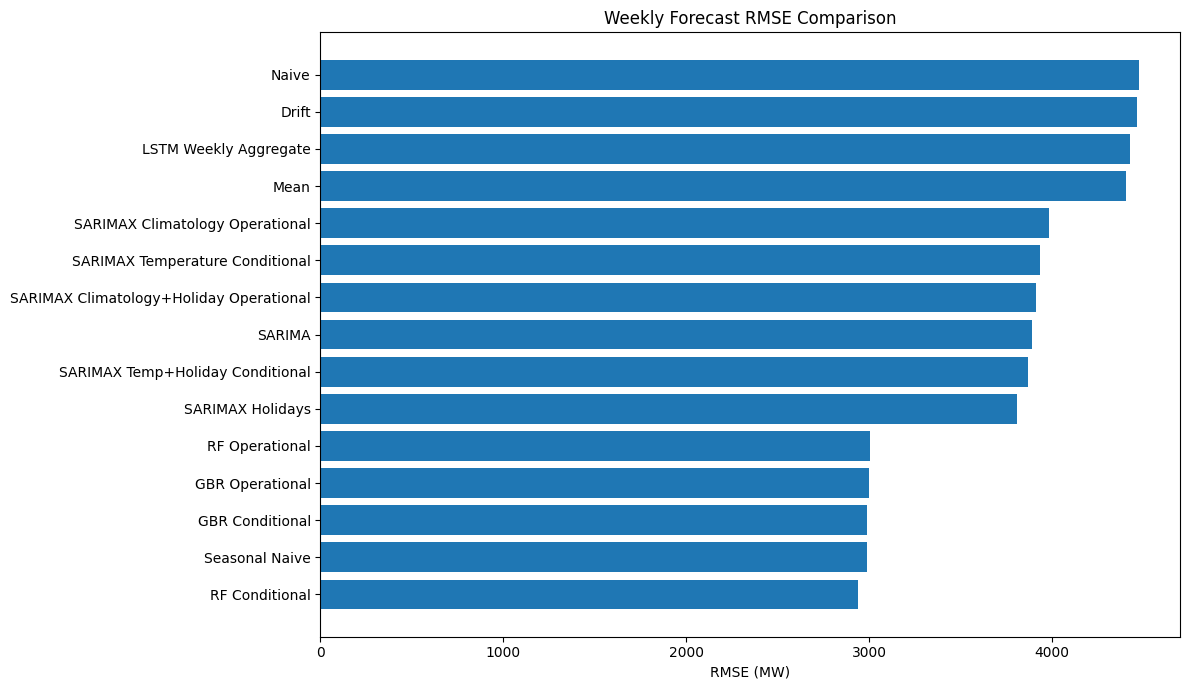

In [49]:
# All weekly forecasts, kept in one figure for the code requirement.
plt.figure(figsize=(14, 8))
plt.plot(test_weekly.index, test_weekly.values, linewidth=2.5, label="Actual test")
for model_name, forecast in weekly_forecasts.items():
    common = test_weekly.index.intersection(forecast.index)
    plt.plot(common, forecast.loc[common].values, alpha=0.75, label=model_name)
plt.title("All Weekly Forecasts against Observed Test Demand")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
plt.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
finish_plot("21_all_weekly_forecasts.png")

# Separate model families improve legibility while keeping full 15-model plot.
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
for ax, category, label in [
    (axes[0], False, "Operational forecasts (origin-available information)"),
    (axes[1], True, "Conditional forecasts (future observed temperature)"),
]:
    ax.plot(test_weekly.index, test_weekly, label="Observed load", color="black", linewidth=2.5)
    for _name, _forecast in weekly_forecasts.items():
        _is_conditional = "conditional" in forecast_metadata[_name][0].lower()
        if _is_conditional == category:
            ax.plot(_forecast.index, _forecast.to_numpy(), alpha=0.78, linewidth=1.1, label=_name)
    ax.set(title=label, ylabel="Weekly mean load (MW)")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left", bbox_to_anchor=(1.005, 1.0), fontsize=8)
axes[-1].set_xlabel("Date")
finish_plot("21b_weekly_forecasts_by_protocol.png")

# A readable key-model figure for the report.
operational_rows = weekly_metrics[
    weekly_metrics["Protocol"].str.contains("operational", case=False, na=False)
]
best_operational_names = operational_rows.head(4)["Model"].tolist()
selected_names = list(dict.fromkeys(["Seasonal Naive", "SARIMA"] + best_operational_names))

plt.figure(figsize=(13, 7))
plt.plot(test_weekly.index, test_weekly.values, linewidth=2.5, label="Actual test")
for model_name in selected_names:
    if model_name in weekly_forecasts:
        forecast = weekly_forecasts[model_name]
        common = test_weekly.index.intersection(forecast.index)
        plt.plot(common, forecast.loc[common].values, label=model_name)
plt.title("Key Operational Weekly Forecasts")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
plt.legend()
finish_plot("22_key_operational_forecasts.png")

plt.figure(figsize=(12, 7))
plot_table = weekly_metrics.sort_values("RMSE", ascending=True)
plt.barh(plot_table["Model"], plot_table["RMSE"])
plt.title("Weekly Forecast RMSE Comparison")
plt.xlabel("RMSE (MW)")
finish_plot("23_weekly_rmse_comparison.png")

### Independent synthetic validation tests

The tests below create their **own small, artificial load and weather sequences**.
They independently test the exact leakage boundaries and metric identities without
reading the saved forecast results to define expected answers. Tests are executed
before the result-bundle is created; any failure stops the notebook. The test
outcomes are saved and can be inspected independently of model training.

In [50]:
# Synthetic, self-contained tests with independent expected values.
import unittest

class ForecastingIndependentUnitTests(unittest.TestCase):
    def test_weekly_training_lags_are_past_only(self):
        idx = pd.date_range("2014-01-05", periods=70, freq="W-SUN")
        demand = pd.Series(np.arange(70, dtype=float) + 1000, index=idx)
        temperature = pd.Series(np.arange(70, dtype=float) + 2000, index=idx)
        features = build_weekly_training_features(
            demand, temperature, pd.Series(0.0, index=idx))
        row = features.iloc[-1]
        self.assertEqual(float(row["target"]), 1069.0)
        self.assertEqual(float(row["load_lag_1"]), 1068.0)
        self.assertEqual(float(row["load_lag_52"]), 1017.0)
        self.assertEqual(float(row["temp_lag_1"]), 2068.0)
        self.assertEqual(float(row["temp_lag_52"]), 2017.0)
        self.assertAlmostEqual(float(row["load_roll_mean_4"]), 1066.5)

    def test_recursive_forecast_does_not_peek_at_future_load(self):
        idx = pd.date_range("2015-01-04", periods=60, freq="W-SUN")
        y = pd.Series(100 + np.arange(60, dtype=float), index=idx)
        temp = pd.Series(200 + np.arange(60, dtype=float), index=idx)
        future = pd.date_range(idx[-1] + pd.Timedelta(weeks=1), periods=3, freq="W-SUN")
        weather = pd.Series([10.0, 11.0, 12.0], index=future)
        holidays = pd.Series(0.0, index=future)
        class Recorder:
            def __init__(self): self.rows = []
            def predict(self, X):
                self.rows.append(X.copy())
                return np.array([999.0])
        recorder = Recorder()
        output = recursive_feature_forecast(
            recorder, y, future, temp, weather, holidays, feature_columns)
        self.assertEqual(list(output), [999.0] * 3)
        self.assertEqual(float(recorder.rows[0]["load_lag_1"].iloc[0]), 159.0)
        self.assertEqual(float(recorder.rows[1]["load_lag_1"].iloc[0]), 999.0)
        self.assertEqual(float(recorder.rows[1]["temp_lag_1"].iloc[0]), 10.0)
        self.assertEqual(float(recorder.rows[2]["temp_lag_1"].iloc[0]), 11.0)

    def test_rolling_statistics_exclude_target_week(self):
        idx = pd.date_range("2015-01-04", periods=60, freq="W-SUN")
        y = pd.Series(np.arange(60, dtype=float), index=idx)
        weather = pd.Series(np.arange(60, dtype=float), index=idx)
        result = make_recursive_feature_row(
            idx[-1] + pd.Timedelta(weeks=1), y, weather, 15.0, 0.0,
            feature_columns)
        self.assertAlmostEqual(float(result["load_roll_mean_4"].iloc[0]), 57.5)
        self.assertAlmostEqual(float(result["load_roll_std_4"].iloc[0]), float(np.std([56, 57, 58, 59], ddof=1)))

    def test_metric_identity(self):
        expected = np.array([100.0, 200.0, 300.0])
        predicted = np.array([110.0, 190.0, 310.0])
        self.assertAlmostEqual(rmse(expected, predicted), 10.0)
        self.assertAlmostEqual(smape(expected, predicted), float(
            200 * np.mean(np.abs(expected - predicted) / (np.abs(expected) + np.abs(predicted)))))

    def test_train_only_weekly_mase(self):
        example_train = np.array([0.0, 1.0, 2.0, 3.0, 4.0])
        self.assertAlmostEqual(mase([10.0], [12.0], example_train, 1), 2.0)

    def test_complete_sarima_grid_independently(self):
        independently_expected = {
            ((p, d, q), (P, D, Q, 52))
            for p, d, q, P, D, Q in itertools.product(
                range(7), range(3), range(7), range(2), range(2), range(2))
        }
        observed = {(parse_tuple(o), parse_tuple(s))
                    for o, s in zip(sarima_grid["order"], sarima_grid["seasonal_order"])}
        self.assertEqual(observed, independently_expected)
        self.assertEqual(len(sarima_grid), 1176)

    def test_test_index_alignment(self):
        self.assertEqual(len(test_weekly), 104)
        self.assertTrue(test_weekly.index.is_unique)
        self.assertTrue(test_weekly.index.is_monotonic_increasing)
        self.assertTrue(all(s.index.equals(test_weekly.index) for s in weekly_forecasts.values()))
        self.assertLess(train_weekly.index.max(), test_weekly.index.min())

    def test_conditional_weather_is_explicit(self):
        self.assertTrue(np.isfinite(test_exog_all["temp_climatology"].to_numpy()).all())
        self.assertTrue(np.isfinite(test_exog_all["temp_observed"].to_numpy()).all())
        self.assertTrue((test_exog_all.index == test_weekly.index).all())
        self.assertIn("conditional", forecast_metadata["RF Conditional"][0].lower())
        self.assertIn("operational", forecast_metadata["RF Operational"][0].lower())

_unit_suite = unittest.defaultTestLoader.loadTestsFromTestCase(ForecastingIndependentUnitTests)
_unit_result = unittest.TextTestRunner(verbosity=2).run(_unit_suite)
_individual_outcomes = []
for _case in unittest.defaultTestLoader.loadTestsFromTestCase(ForecastingIndependentUnitTests):
    _label = _case._testMethodName
    _failed = any(_label in str(test) for test, _ in _unit_result.failures + _unit_result.errors)
    _individual_outcomes.append({"test": _label, "passed": not _failed})
independent_unit_test_results = pd.DataFrame(_individual_outcomes)
independent_unit_test_results.to_csv(TABLE_DIR / "independent_unit_tests.csv", index=False)
if not _unit_result.wasSuccessful():
    raise AssertionError("Independent synthetic tests failed; inspect test output")
print(f"Independent synthetic tests passed: {_unit_result.testsRun}")

test_complete_sarima_grid_independently (__main__.ForecastingIndependentUnitTests.test_complete_sarima_grid_independently) ... ok
test_conditional_weather_is_explicit (__main__.ForecastingIndependentUnitTests.test_conditional_weather_is_explicit) ... ok
test_metric_identity (__main__.ForecastingIndependentUnitTests.test_metric_identity) ... ok
test_recursive_forecast_does_not_peek_at_future_load (__main__.ForecastingIndependentUnitTests.test_recursive_forecast_does_not_peek_at_future_load) ... ok
test_rolling_statistics_exclude_target_week (__main__.ForecastingIndependentUnitTests.test_rolling_statistics_exclude_target_week) ... ok
test_test_index_alignment (__main__.ForecastingIndependentUnitTests.test_test_index_alignment) ... ok
test_train_only_weekly_mase (__main__.ForecastingIndependentUnitTests.test_train_only_weekly_mase) ... ok
test_weekly_training_lags_are_past_only (__main__.ForecastingIndependentUnitTests.test_weekly_training_lags_are_past_only) ... ok

---------------------

Independent synthetic tests passed: 8


## Part 8 — Report outputs

In [51]:
def project_relative(path: Path) -> str:
    try:
        return str(path.resolve().relative_to(PROJECT_DIR.resolve()))
    except ValueError:
        return str(path)


report_asset_manifest = pd.DataFrame({
    "Recommended report item": [
        "Initial weekly-demand plot",
        "Weekly seasonal decomposition",
        "Stationarity tests",
        "Benchmark forecast plot",
        "SARIMA forecast and confidence interval",
        "SARIMA residual ACF and Ljung-Box table",
        "SARIMAX temperature/holiday comparison",
        "Feature-model forecast and importance",
        "LSTM recursive-validation plot",
        "LSTM full-period daily-mean plot",
        "SARIMA prediction interval coverage",
        "Horizon-wise model error table",
        "Paired block-bootstrap model comparison",
        "Final weekly metric table",
        "Key operational forecast plot",
        "All models: timestamp-aligned weekly predictions",
        "Hourly LSTM and baseline predictions",
        "SARIMA training-diagnostic sensitivity",
        "Forecast interval horizon coverage and score",
        "Repeated LSTM seed stability",
        "Hourly MASE common denominator check",
        "AIC comparison by differencing family",
        "Leakage-safe pretest feature ablation",
        "2020 time-split diagnostic",
        "Bootstrap confidence interval block sensitivity",
        "Operational versus conditional split plot",
        "Training week and hour seasonality heatmap",
        "SARIMA adequacy and interval interpretation",
        "SARIMA observed versus nominal interval coverage",
        "Tree ensemble model-reload verification",
        "LSTM and scaler model-reload verification",
        "Independent synthetic validation tests",
    ],
    "Generated path": [
        project_relative(FIGURE_DIR / "03_weekly_load.png"),
        project_relative(FIGURE_DIR / "06_decomposition_seasonal.png"),
        project_relative(TABLE_DIR / "stationarity_tests.csv"),
        project_relative(FIGURE_DIR / "09_benchmark_forecasts.png"),
        project_relative(FIGURE_DIR / "14_sarima_forecast.png"),
        project_relative(TABLE_DIR / "sarima_ljung_box.csv"),
        project_relative(TABLE_DIR / "all_weekly_model_metrics.csv"),
        project_relative(FIGURE_DIR / "17_random_forest_importance.png"),
        project_relative(FIGURE_DIR / "18b_lstm_recursive_validation_rmse.png"),
        project_relative(FIGURE_DIR / "19_lstm_full_test_daily_means.png"),
        project_relative(TABLE_DIR / "sarima_interval_coverage.csv"),
        project_relative(TABLE_DIR / "weekly_horizon_errors.csv"),
        project_relative(TABLE_DIR / "weekly_rmse_block_bootstrap.csv"),
        project_relative(TABLE_DIR / "all_weekly_model_metrics.csv"),
        project_relative(FIGURE_DIR / "22_key_operational_forecasts.png"),
        project_relative(TABLE_DIR / "weekly_predictions_vs_actual.csv"),
        project_relative(TABLE_DIR / "hourly_predictions_vs_actual.csv"),
        project_relative(TABLE_DIR / "sarima_diagnostic_sensitivity.csv"),
        project_relative(TABLE_DIR / "prediction_interval_diagnostics.csv"),
        project_relative(TABLE_DIR / "lstm_seed_stability.csv"),
        project_relative(TABLE_DIR / "hourly_lstm_metrics.csv"),
        project_relative(TABLE_DIR / "sarima_differencing_aic_comparison.csv"),
        project_relative(TABLE_DIR / "feature_ablation_pretest_validation.csv"),
        project_relative(TABLE_DIR / "pre_post_2020_period_errors.csv"),
        project_relative(TABLE_DIR / "bootstrap_block_length_sensitivity.csv"),
        project_relative(FIGURE_DIR / "21b_weekly_forecasts_by_protocol.png"),
        project_relative(FIGURE_DIR / "04d_training_weekday_hour_heatmap.png"),
        project_relative(TABLE_DIR / "sarima_diagnostic_interpretation.csv"),
        project_relative(FIGURE_DIR / "14b_sarima_interval_reliability.png"),
        project_relative(TABLE_DIR / "tree_model_reload_checks.csv"),
        project_relative(TABLE_DIR / "lstm_model_reload_checks.csv"),
        project_relative(TABLE_DIR / "independent_unit_tests.csv"),
    ],
})
report_asset_manifest.to_csv(TABLE_DIR / "report_asset_manifest.csv", index=False)
print(report_asset_manifest.to_string(index=False))

# The manifest must refer to real run files, not a list of planned figures.
_missing_assets = [path for path in report_asset_manifest["Generated path"]
                   if not (PROJECT_DIR / path).exists()]
if _missing_assets:
    raise FileNotFoundError(f"Report manifest references missing run outputs: {_missing_assets}")
assert (FIGURE_DIR / "15b_temperature_seasonal_anomaly_association.png").exists()
print("Every report-asset manifest entry exists in this notebook execution.")


                         Recommended report item                                         Generated path
                      Initial weekly-demand plot                     outputs/figures/03_weekly_load.png
                   Weekly seasonal decomposition          outputs/figures/06_decomposition_seasonal.png
                              Stationarity tests                  outputs/tables/stationarity_tests.csv
                         Benchmark forecast plot             outputs/figures/09_benchmark_forecasts.png
         SARIMA forecast and confidence interval                 outputs/figures/14_sarima_forecast.png
         SARIMA residual ACF and Ljung-Box table                    outputs/tables/sarima_ljung_box.csv
          SARIMAX temperature/holiday comparison            outputs/tables/all_weekly_model_metrics.csv
           Feature-model forecast and importance        outputs/figures/17_random_forest_importance.png
                  LSTM recursive-validation plot outputs/figures

## Final validation

### Standalone verification of the exported results (independent process)

The separate script `verify_exported_results.py` reads the **on-disk CSVs** rather
than notebook variables, reconstructs all weekly and hourly error statistics,
verifies all 1,176 unique SARIMA combinations, checks chronology, model artifacts,
and confirms reload-test evidence. It runs as a new Python process and writes
`independent_external_verification.csv`. This is an additional reproducibility
check, **not** a fresh model-training run.

In [52]:
VERIFIER_SCRIPT_SOURCE = '"""Independent, read-only verification of German demand forecasting exports.\n\nUsage: python verify_exported_results.py PATH_TO/German_Electricity_Forecasting\nNo model retraining, network requests, or notebook globals are required.\n"""\nfrom __future__ import annotations\nimport argparse\nimport ast\nimport itertools\nimport json\nimport sys\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\n\n\ndef verify(project: Path) -> pd.DataFrame:\n    tables = project / "outputs" / "tables"\n    models = project / "outputs" / "models"\n    data = project / "data"\n    records = []\n\n    def check(label, condition, detail=""):\n        ok = bool(condition)\n        records.append({"test": label, "passed": ok, "detail": str(detail)[:240]})\n        return ok\n\n    def read_csv(name):\n        path = tables / name\n        if not path.is_file():\n            raise FileNotFoundError(str(path))\n        return pd.read_csv(path)\n\n    weekly = read_csv("weekly_predictions_vs_actual.csv")\n    summary = read_csv("all_weekly_model_metrics.csv")\n    grid = read_csv("sarima_full_grid.csv")\n    historical_weekly = pd.read_csv(data / "german_load_weekly.csv")\n    check("104-week fixed-origin evaluation", len(weekly) == 104)\n    check("one observation per model per test week", len(summary) == len(weekly.columns) - 2)\n    dates = pd.to_datetime(weekly.iloc[:, 0], errors="coerce")\n    check("weekly chronology unique and increasing", dates.notna().all() and dates.is_unique and dates.is_monotonic_increasing)\n    check("Sunday week endings", (dates.dt.dayofweek == 6).all())\n    check("weekly forecasts and observations finite", np.isfinite(weekly.iloc[:, 1:].to_numpy(dtype=float)).all())\n\n    actual = weekly["actual_MW"].to_numpy(dtype=float)\n    model_columns = [c for c in weekly.columns if c not in {weekly.columns[0], "actual_MW"}]\n    check("every weekly model has an evaluation record", set(model_columns) == set(summary["Model"]))\n    by_model = summary.set_index("Model")\n    weekly_train = historical_weekly.iloc[:len(historical_weekly) - len(weekly)]["load"].to_numpy(dtype=float)\n    seasonal_period = 52\n    denominator = np.mean(np.abs(weekly_train[seasonal_period:] - weekly_train[:-seasonal_period]))\n    check("weekly MASE training denominator positive", np.isfinite(denominator) and denominator > 0)\n    for model_name in model_columns:\n        yhat = weekly[model_name].to_numpy(dtype=float)\n        diff = actual - yhat\n        reconstructed = {\n            "RMSE": float(np.sqrt(np.mean(diff ** 2))),\n            "MAE": float(np.mean(np.abs(diff))),\n            "sMAPE_pct": float(200 * np.mean(np.abs(diff) / (np.abs(actual) + np.abs(yhat)))),\n            "MASE": float(np.mean(np.abs(diff)) / denominator),\n        }\n        available = by_model.loc[model_name]\n        ok = all(np.isclose(reconstructed[key], float(available[key]), atol=1e-5, rtol=1e-6)\n                 for key in reconstructed)\n        check(f"independent weekly metrics: {model_name}", ok)\n\n    observed_specifications = {(tuple(ast.literal_eval(o)), tuple(ast.literal_eval(s)))\n                               for o, s in zip(grid["order"], grid["seasonal_order"])}\n    expected_specifications = {\n        ((p, d, q), (P, D, Q, 52))\n        for p, d, q, P, D, Q in itertools.product(range(7), range(3), range(7), range(2), range(2), range(2))\n    }\n    check("complete 1,176 unique SARIMA specifications", len(grid) == 1176 and observed_specifications == expected_specifications)\n    check("SARIMA primary diagnostic files present", all((tables / n).is_file() for n in (\n        "sarima_diagnostic_summary.csv", "sarima_ljung_box.csv", "sarima_interval_coverage.csv",\n        "sarima_diagnostic_interpretation.csv")))\n    if (tables / "sarima_diagnostic_summary.csv").exists():\n        diagnostic = read_csv("sarima_diagnostic_summary.csv").iloc[0]\n        check("SARIMA residual screen truthfully labelled", bool(diagnostic["passes_residual_screen"]) ==\n              (float(diagnostic["minimum_ljung_box_p"]) > float(diagnostic["residual_screen_alpha"])))\n    check("all tree models persisted", all((models / (name + ".joblib")).is_file() for name in\n          ("rf_conditional", "rf_operational", "gbr_conditional", "gbr_operational")))\n    check("tree-model reload verification recorded", (tables / "tree_model_reload_checks.csv").is_file())\n    check("tree feature schema persisted", (models / "tree_feature_schema.json").is_file())\n    if (tables / "tree_model_reload_checks.csv").is_file():\n        reload_rows = read_csv("tree_model_reload_checks.csv")\n        check("all four tree models reloaded and verified", len(reload_rows) == 4 and reload_rows["passed"].astype(bool).all())\n\n    hourly_file = tables / "hourly_predictions_vs_actual.csv"\n    if hourly_file.exists():\n        hourly = pd.read_csv(hourly_file)\n        hourly_metrics = read_csv("hourly_lstm_metrics.csv").set_index("Model")\n        check("hourly predictions cover whole test horizon", len(hourly) >= 17000)\n        check("common hourly MASE denominator", hourly_metrics["MASE_scaling_hours"].eq(168).all()\n              and hourly_metrics["MASE_denominator_MW"].nunique() == 1)\n        truth = hourly["actual_MW"].to_numpy(dtype=float)\n        hourly_ok = True\n        for model_name in ("LSTM Fixed-Origin", "Hourly Seasonal Naive", "Hourly Annual Seasonal Naive"):\n            pred = hourly[model_name].to_numpy(dtype=float)\n            calc_rmse = np.sqrt(np.mean((truth - pred)**2))\n            calc_mae = np.mean(np.abs(truth - pred))\n            calculated_mase = calc_mae / float(hourly_metrics.loc[model_name, "MASE_denominator_MW"])\n            row = hourly_metrics.loc[model_name]\n            hourly_ok &= bool(np.isclose(row["RMSE"], calc_rmse, atol=1e-5)\n                              and np.isclose(row["MAE"], calc_mae, atol=1e-5)\n                              and np.isclose(row["MASE"], calculated_mase, atol=1e-5))\n        check("independent hourly RMSE/MAE/MASE", hourly_ok)\n        check("LSTM model and training-only scaler persisted", (models / "lstm_final_retrained.keras").is_file()\n              and (models / "lstm_standard_scaler.joblib").is_file())\n        check("LSTM reload verification recorded", (tables / "lstm_model_reload_checks.csv").is_file())\n        if (tables / "lstm_model_reload_checks.csv").is_file():\n            lstm_rows = read_csv("lstm_model_reload_checks.csv")\n            check("reloaded LSTM passed numerical comparison", len(lstm_rows) == 1 and bool(lstm_rows.loc[0, "passed"]))\n    else:\n        check("hourly LSTM required by assignment", False, "Hourly forecast table missing")\n\n    check("training-only weather provenance recorded", (tables / "weather_source_provenance.json").is_file()\n          and (tables / "forecast_covariate_availability.csv").is_file())\n    result = pd.DataFrame(records)\n    path = tables / "independent_external_verification.csv"\n    result.to_csv(path, index=False)\n    return result\n\n\ndef main():\n    ap = argparse.ArgumentParser(description=__doc__)\n    ap.add_argument("project_dir", type=Path)\n    args = ap.parse_args()\n    try:\n        results = verify(args.project_dir)\n    except Exception as exc:\n        print(f"Verification could not complete: {type(exc).__name__}: {exc}", file=sys.stderr)\n        return 2\n    print(results.to_string(index=False))\n    passed = int(results["passed"].sum())\n    total = len(results)\n    print(f"Independent export verification: {passed}/{total} checks passed")\n    return 0 if passed == total else 1\n\nif __name__ == "__main__":\n    raise SystemExit(main())\n'

# Reconstruct all reported forecast metrics in a separate Python process.
import sys
from subprocess import run

_VERIFIER_FILE = PROJECT_DIR / "verify_exported_results.py"
_VERIFIER_FILE.write_text(VERIFIER_SCRIPT_SOURCE, encoding="utf-8")
_verification_run = run(
    [sys.executable, str(_VERIFIER_FILE), str(PROJECT_DIR)],
    capture_output=True, text=True, check=False,
)
print(_verification_run.stdout[-12000:])
if _verification_run.stderr.strip():
    print("Verification stderr:", _verification_run.stderr[-4000:])
if _verification_run.returncode != 0:
    raise RuntimeError(
        f"Standalone export verification failed (exit {_verification_run.returncode}). "
        "Inspect the verification report for failed checks."
    )

                                                               test  passed detail
                                   104-week fixed-origin evaluation    True       
                            one observation per model per test week    True       
                            weekly chronology unique and increasing    True       
                                                Sunday week endings    True       
                           weekly forecasts and observations finite    True       
                        every weekly model has an evaluation record    True       
                          weekly MASE training denominator positive    True       
                                   independent weekly metrics: Mean    True       
                                  independent weekly metrics: Naive    True       
                         independent weekly metrics: Seasonal Naive    True       
                                  independent weekly metrics: Drift    True       
    

In [53]:
required_output_names = [
    "stationarity_tests.csv",
    "training_temperature_association.csv",
    "model_comparison_by_availability.csv",
    "forecast_model_tradeoffs.csv",
    "benchmark_metrics.csv",
    "sarima_full_grid.csv",
    "sarima_ljung_box.csv",
    "sarima_interval_coverage.csv",
    "weekly_horizon_errors.csv",
    "weekly_rmse_block_bootstrap.csv",
    "forecast_covariate_availability.csv",
    "sarima_diagnostic_summary.csv",
    "sarimax_residual_diagnostics.csv",
    "feature_model_tuning_summary.csv",
    "all_weekly_model_metrics.csv",
    "weekly_predictions_vs_actual.csv",
    "weekly_prediction_protocols.csv",
    "sarima_diagnostic_sensitivity.csv",
    "sarima_diagnostic_screen_comparison.csv",
    "prediction_interval_diagnostics.csv",
    "stationarity_interpretation.csv",
    "sarima_differencing_aic_comparison.csv",
    "imputed_hourly_observations.csv",
    "training_day_hour_profile.csv",
    "feature_ablation_pretest_validation.csv",
    "pre_post_2020_period_errors.csv",
    "bootstrap_block_length_sensitivity.csv",
    "sarima_diagnostic_interpretation.csv",
    "tree_model_reload_checks.csv",
    "independent_unit_tests.csv",
    "independent_external_verification.csv",
]
if RUN_LSTM:
    required_output_names.extend([
        "lstm_tuning_results.csv",
        "hourly_lstm_metrics.csv",
        "hourly_predictions_vs_actual.csv",
        "lstm_seed_stability.csv",
        "lstm_model_reload_checks.csv",
    ])

missing_outputs = [
    name for name in required_output_names
    if not (TABLE_DIR / name).exists()
]
assert not missing_outputs, f"Missing required output tables: {missing_outputs}"

assert len(sarima_grid) == len(sarima_specs) == 1176, (
    f"Expected 1,176 SARIMA specifications, found {len(sarima_grid)}."
)
assert len({parse_tuple(value) for value in sarima_grid["order"]}) == 147
assert json.loads(SARIMA_GRID_META_FILE.read_text(encoding="utf-8")) == expected_grid_metadata
assert weekly_metrics["RMSE"].notna().all()
assert np.isfinite(weekly_metrics[["RMSE", "MAE", "sMAPE_pct"]].to_numpy()).all()

for model_name, forecast in weekly_forecasts.items():
    assert forecast.index.equals(test_weekly.index), (
        f"{model_name} does not use the common weekly test index."
    )
    assert np.isfinite(forecast.to_numpy()).all(), (
        f"{model_name} contains a non-finite forecast."
    )

if RUN_LSTM:
    assert lstm_hourly_forecast.index.equals(test_hourly.index)
    assert np.isfinite(lstm_hourly_forecast.to_numpy()).all()
    assert best_lstm_artifact["scaler_fit_end"] == str(train_hourly.index.max())

print("Final automated validation passed.")
print(f"Verified {len(sarima_grid)} SARIMA specifications and {len(weekly_forecasts)} weekly forecasts.")
print("All required output tables exist and all reported forecasts are finite.")

# Synthetic unit test: target lags MUST come from the forecast history; temperature
# lags MUST come from observed training + supplied future proxy, never future truth.
class _CapturePredictor:
    def __init__(self):
        self.rows = []
    def predict(self, X):
        self.rows.append(X.copy())
        return np.array([100.0])

_t_idx = pd.date_range("2015-01-04", periods=60, freq="W-SUN")
_t_y = pd.Series(np.arange(60, dtype=float) + 100, index=_t_idx)
_t_temp = pd.Series(np.arange(60, dtype=float) + 1000, index=_t_idx)
_f_idx = pd.date_range(_t_idx[-1] + pd.Timedelta(weeks=1), periods=3, freq="W-SUN")
_f_proxy = pd.Series([10.0, 11.0, 12.0], index=_f_idx)
_f_holiday = pd.Series(0.0, index=_f_idx)
_capture = _CapturePredictor()
recursive_feature_forecast(_capture, _t_y, _f_idx, _t_temp,
                           _f_proxy, _f_holiday, feature_columns)
assert _capture.rows[0].iloc[0]["temp_lag_1"] == 1059.0
assert _capture.rows[1].iloc[0]["temp_lag_1"] == 10.0
assert _capture.rows[2].iloc[0]["temp_lag_1"] == 11.0
assert _capture.rows[1].iloc[0]["load_lag_1"] == 100.0
assert set(["temp_lag_1", "temp_lag_2", "temp_lag_4", "temp_lag_52"]).issubset(feature_columns)
print("Synthetic data-leakage and feature-alignment tests passed.")

# Protection against rerunning the results with an inadvertently changed test horizon.
assert (test_weekly.index.min() >= forecast_start)
assert len(test_weekly) >= 100, "Expected approximately 104 weekly test observations"
assert len(test_hourly) >= 24 * 365 * 2 - 24, "Expected approximately two years of test hours"
assert set(weekly_metrics["Model"]) == set(weekly_forecasts)
assert all(np.isclose(weekly_metrics.set_index("Model").loc[name, "RMSE"],
                      rmse(test_weekly, f)) for name, f in weekly_forecasts.items())
print("Protocol and common-horizon metric checks passed.")
# Independent metric reconstruction from the actual exported CSV files.
_csv_weekly = pd.read_csv(TABLE_DIR / "weekly_predictions_vs_actual.csv", index_col=0)
assert len(_csv_weekly) == len(test_weekly)
assert len(_csv_weekly.columns) - 1 == len(weekly_forecasts)
assert set(_csv_weekly.columns) == ({"actual_MW"} | set(weekly_forecasts))
assert np.allclose(_csv_weekly["actual_MW"], test_weekly.to_numpy())
for _name in weekly_forecasts:
    _saved_rmse = float(weekly_metrics.set_index("Model").loc[_name, "RMSE"])
    _recomputed = rmse(_csv_weekly["actual_MW"], _csv_weekly[_name])
    assert np.isclose(_saved_rmse, _recomputed, atol=1e-8), (_name, _saved_rmse, _recomputed)
if RUN_LSTM:
    _csv_hourly = pd.read_csv(TABLE_DIR / "hourly_predictions_vs_actual.csv", index_col=0)
    assert len(_csv_hourly) == len(test_hourly)
    assert np.allclose(_csv_hourly["actual_MW"], test_hourly.to_numpy())
    _lstm_saved_rmse = float(hourly_metrics.set_index("Model").loc["LSTM Fixed-Origin", "RMSE"])
    assert (hourly_metrics["MASE_scaling_hours"] == HOURLY_MASE_SCALING_PERIOD).all()
    expected_hourly_mase = hourly_metrics["MAE"] / hourly_mase_denominator
    assert np.allclose(hourly_metrics["MASE"], expected_hourly_mase, atol=1e-10)
    assert np.isclose(_lstm_saved_rmse,
                      rmse(_csv_hourly["actual_MW"], _csv_hourly["LSTM Fixed-Origin"]),
                      atol=1e-8)
    _seed_table = pd.read_csv(TABLE_DIR / "lstm_seed_stability.csv")
    assert len(_seed_table) == (1 + len(LSTM_STABILITY_EXTRA_SEEDS) if RUN_LSTM_SEED_STABILITY else 1)

assert len(interval_analysis) == 6 * (1 + len(HORIZON_BANDS))
assert interval_analysis["Mean_interval_score_MW"].notna().all()
assert all(interval_analysis["Test_used_for_calibration"] == False)
assert (feature_ablation_validation["Used_test_targets_for_selection"] == False).all()
assert (structural_period_errors["Selection_uses_this_split"] == False).all()
assert len(feature_ablation_validation) == 8
assert len(bootstrap_block_sensitivity) == 15
assert (stationarity_results["ADF_rejects_unit_root_at_5pct"] ==
        (stationarity_results["ADF_p_value"] < 0.05)).all()
assert weekly_prediction_table.index.equals(test_weekly.index)
print("Prediction-file reproducibility, diagnostic and coverage checks passed.")


Final automated validation passed.
Verified 1176 SARIMA specifications and 15 weekly forecasts.
All required output tables exist and all reported forecasts are finite.
Synthetic data-leakage and feature-alignment tests passed.
Protocol and common-horizon metric checks passed.
Prediction-file reproducibility, diagnostic and coverage checks passed.


In [54]:
# Evidence manifest: this is created only if all final assertions have passed.
# It records hashes so report tables can be linked to this exact completed run.
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024*1024), b""):
            h.update(chunk)
    return h.hexdigest()

core_files = [
    TABLE_DIR / "all_weekly_model_metrics.csv",
    TABLE_DIR / "weekly_predictions_vs_actual.csv",
    TABLE_DIR / "sarima_full_grid.csv",
    TABLE_DIR / "sarima_diagnostic_interpretation.csv",
    TABLE_DIR / "independent_unit_tests.csv",
    TABLE_DIR / "independent_external_verification.csv",
    TABLE_DIR / "tree_model_reload_checks.csv",
    MODEL_DIR / "tree_feature_schema.json",
    TABLE_DIR / "training_temperature_association.csv",
    TABLE_DIR / "weather_source_provenance.json",
    TABLE_DIR / "model_comparison_by_availability.csv",
    TABLE_DIR / "sarima_full_grid_metadata.json",
    TABLE_DIR / "prediction_interval_diagnostics.csv",
    DATA_DIR / "german_load_hourly_clean.csv",
    DATA_DIR / "german_load_weekly.csv",
]
# Document the exact cached weather used if available.
if (DATA_DIR / "berlin_temperature_daily_utc.csv").exists():
    core_files.append(DATA_DIR / "berlin_temperature_daily_utc.csv")
if RUN_LSTM:
    core_files += [TABLE_DIR / "hourly_predictions_vs_actual.csv",
                   TABLE_DIR / "hourly_lstm_metrics.csv",
                   TABLE_DIR / "lstm_seed_stability.csv",
                   TABLE_DIR / "lstm_model_reload_checks.csv",
                   MODEL_DIR / "lstm_standard_scaler.joblib"]
for path in core_files:
    assert path.exists(), str(path)

execution_audit = {
    "runtime": EXECUTION_ENVIRONMENT, "forecast_origin": str(forecast_start),
    "train_weekly_N": int(len(train_weekly)), "test_weekly_N": int(len(test_weekly)),
    "train_hourly_N": int(len(train_hourly)), "test_hourly_N": int(len(test_hourly)),
    "sarima_specifications": int(len(sarima_grid)),
    "sarima_primary_order": str(best_order),
    "sarima_primary_seasonal_order": str(best_seasonal_order),
    "weekly_models_evaluated": int(len(weekly_forecasts)),
    "lstm_run": bool(RUN_LSTM),
    "lstm_seed_stability_run": bool(RUN_LSTM and RUN_LSTM_SEED_STABILITY),
    "test_targets_used_for_parameter_selection": False,
    "hourly_MASE_common_scaling_period_hours": HOURLY_MASE_SCALING_PERIOD,
    "hourly_MASE_common_training_denominator_MW": float(hourly_mase_denominator) if RUN_LSTM else None,
    "imputed_hourly_N": int(_imputed_mask.sum()),
    "tree_model_reload_verified": bool(tree_model_reload_checks["passed"].all()),
    "independent_synthetic_tests_verified": bool(independent_unit_test_results["passed"].all()),
    "independent_export_checks_verified": bool(pd.read_csv(TABLE_DIR / "independent_external_verification.csv")["passed"].all()),
    "lstm_model_reload_verified": bool(lstm_model_reload_checks["passed"].all()) if RUN_LSTM else None,
    "exogenous_feature_ablation_is_pretest_only": True,
    "2020_structural_period_split_is_postselection": True,
    "conditional_models_use_observed_test_weather": True,
    "package_versions": environment_versions,
    "sha256": {project_relative(path): sha256_file(path) for path in core_files},
}
(TABLE_DIR / "execution_audit.json").write_text(
    json.dumps(execution_audit, indent=2), encoding="utf-8")
print("Saved final SHA-256 execution audit for", len(core_files), "artifacts")


Saved final SHA-256 execution audit for 21 artifacts


In [55]:
# Save the exact package versions and a machine-readable quality checklist.
_lock_lines = [f"{name}=={value}" for name, value in sorted(environment_versions.items())
               if isinstance(value, str) and value != "not installed (TensorFlow is checked in Part 6)"]
(PROJECT_DIR / "requirements-ran.txt").write_text("\n".join(_lock_lines) + "\n", encoding="utf-8")
reproducibility_checks = pd.DataFrame([
    {"Check": "training/test chronological split", "Pass": train_weekly.index.max() < test_weekly.index.min()},
    {"Check": "complete SARIMA parameter grid", "Pass": len(sarima_grid) == 1176},
    {"Check": "common weekly prediction index", "Pass": all(s.index.equals(test_weekly.index) for s in weekly_forecasts.values())},
    {"Check": "hourly MASE denominator consistent", "Pass": (not RUN_LSTM) or bool((hourly_metrics["MASE_scaling_hours"] == 168).all())},
    {"Check": "all weekly predictions finite", "Pass": all(np.isfinite(s.to_numpy()).all() for s in weekly_forecasts.values())},
    {"Check": "trained-weather climatology only", "Pass": train_temp.index.max() < test_weekly.index.min()},
    {"Check": "SARIMA model fits training only", "Pass": best_model.nobs == len(train_weekly)},
    {"Check": "four tree models reload exactly", "Pass": bool(tree_model_reload_checks["passed"].all())},
    {"Check": "independent synthetic tests", "Pass": bool(independent_unit_test_results["passed"].all())},
    {"Check": "external export verification", "Pass": bool(pd.read_csv(TABLE_DIR / "independent_external_verification.csv")["passed"].all())},
    {"Check": "LSTM model and scaler reload", "Pass": (not RUN_LSTM) or bool(lstm_model_reload_checks["passed"].all())},
])
reproducibility_checks.to_csv(TABLE_DIR / "final_reproducibility_checks.csv", index=False)
assert reproducibility_checks["Pass"].all(), "Final reproducibility self-check failed"
print(reproducibility_checks.to_string(index=False))


                             Check  Pass
 training/test chronological split  True
    complete SARIMA parameter grid  True
    common weekly prediction index  True
hourly MASE denominator consistent  True
     all weekly predictions finite  True
  trained-weather climatology only  True
   SARIMA model fits training only  True
   four tree models reload exactly  True
       independent synthetic tests  True
      external export verification  True
      LSTM model and scaler reload  True


### Export forecasting results

In [56]:
# Generate an archive of the final figures, tables and saved model artifacts.
# IMPORTANT: To retain progress in a later session also save the checkpoint pair.
import shutil
BUNDLE_PATH = WORKING_ROOT / "German_Electricity_Forecasting_Results.zip"
# Include clean data and weather cache alongside all outputs.
with zipfile.ZipFile(BUNDLE_PATH, "w", compression=zipfile.ZIP_DEFLATED) as output_zip:
    if (PROJECT_DIR / "requirements-ran.txt").exists():
        output_zip.write(PROJECT_DIR / "requirements-ran.txt", arcname="requirements-ran.txt")
    # Keep the standalone source verifier with the outputs for independent rechecking.
    if (PROJECT_DIR / "verify_exported_results.py").exists():
        output_zip.write(PROJECT_DIR / "verify_exported_results.py",
                         arcname="tools/verify_exported_results.py")
    for directory in (OUTPUT_DIR, DATA_DIR):
        for path in sorted(directory.rglob("*")):
            if path.is_file():
                output_zip.write(path, arcname=str(path.relative_to(PROJECT_DIR)))
with zipfile.ZipFile(BUNDLE_PATH) as output_zip:
    assert output_zip.testzip() is None, "Results archive integrity check failed"
CHECKPOINT_BACKUP = WORKING_ROOT / "German_Electricity_SARIMA_Checkpoint.zip"
with zipfile.ZipFile(CHECKPOINT_BACKUP, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in (SARIMA_GRID_FILE, SARIMA_GRID_META_FILE):
        if path.exists():
            archive.write(path, arcname=path.name)
print(f"Results archive: {BUNDLE_PATH} ({BUNDLE_PATH.stat().st_size / 1024**2:.2f} MB)")
print(f"SARIMA checkpoint archive: {CHECKPOINT_BACKUP}")
print(f"Result files are available in: {WORKING_ROOT}")


Results archive: /content/German_Electricity_Forecasting_Results.zip (19.19 MB)
SARIMA checkpoint archive: /content/German_Electricity_SARIMA_Checkpoint.zip
Result files are available in: /content
